In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
import os

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

print(os.listdir(BASE))

['test_series.csv', 'train_series.csv', 'sample_submission.csv', 'test_series', 'train_series', 'train.csv', 'test.csv']


In [3]:
import pandas as pd

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

train = pd.read_csv(f"{BASE}/train.csv")
train_series = pd.read_csv(f"{BASE}/train_series.csv")

print("Train:", train.shape)
print("Train series:", train_series.shape)

display(train.head())
display(train_series.head())

Train: (4407, 14)
Train series: (24371, 5)


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


In [4]:
labeled = train[train.iloc[:, 2:].notna().any(axis=1)].copy()

print("Total studies:", len(train))
print("Labeled studies:", len(labeled))
print("Unlabeled studies:", len(train) - len(labeled))

display(labeled.head())

Total studies: 4407
Labeled studies: 58
Unlabeled studies: 4349


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,1.2.826.0.1.3680043.8.498.10095687747295410396...,Antecedentes Clínicos:\nEsguince rodilla. [DAT...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,1.2.826.0.1.3680043.8.498.10170898615867673028...,The study reveals normal knee joint alignment...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,1.2.826.0.1.3680043.8.498.10306159113324811538...,Exam Type: MRI KNEE RIGHT WO CONTRAST\nExam Da...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
445,1.2.826.0.1.3680043.8.498.11287937729196958426...,"MRI of left Knee with \n-3-Plane Loc R'T, Sag ...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
470,1.2.826.0.1.3680043.8.498.11382021393803389951...,"In the medial compartment, there is longitudi...",1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
import os
import pydicom
import matplotlib.pyplot as plt

study_uid = labeled.iloc[0]["StudyInstanceUID"]

# Get all series for this study
study_series = train_series[
    train_series["StudyInstanceUID"] == study_uid
]

display(study_series)

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
163,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.10791858932231443712...,0,0,Sagittal
164,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.12451507871565834868...,0,0,Coronal
165,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.21497837050858589852...,1,1,Coronal
166,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,1,1,Sagittal
167,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,1,1,Axial


In [7]:
# Select the sagittal fluid-sensitive + fat-suppressed series automatically
selected_series = study_series[
    (study_series["Anatomical_Plane"] == "Sagittal") &
    (study_series["Fluid_Sensitive"] == 1) &
    (study_series["Fat_Suppression"] == 1)
].iloc[0]

series_uid = selected_series["SeriesInstanceUID"]

series_path = f"{BASE}/train_series/{study_uid}/{series_uid}"

files = [
    os.path.join(series_path, f)
    for f in os.listdir(series_path)
    if f.endswith(".dcm")
]

print("Series UID:", series_uid)
print("Number of DICOM slices:", len(files))
print("Series path:", series_path)

Series UID: 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
Number of DICOM slices: 36
Series path: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149/1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429


In [8]:
import pydicom
import numpy as np

# Load all DICOM slices
slices = [pydicom.dcmread(f) for f in files]

# Sort using ImagePositionPatient when available
slices.sort(
    key=lambda x: float(x.ImagePositionPatient[2])
    if hasattr(x, "ImagePositionPatient")
    else float(getattr(x, "InstanceNumber", 0))
)

images = np.stack([s.pixel_array for s in slices])

print("Number of slices:", images.shape[0])
print("Image size:", images.shape[1:])
print("Volume shape:", images.shape)
print("Data type:", images.dtype)

Number of slices: 36
Image size: (320, 320)
Volume shape: (36, 320, 320)
Data type: uint16


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Convert to float
volume = images.astype(np.float32)

# Percentile normalization to reduce extreme intensity values
low, high = np.percentile(volume, [1, 99])

volume = np.clip(volume, low, high)
volume = (volume - low) / (high - low + 1e-8)

print("Minimum:", volume.min())
print("Maximum:", volume.max())
print("Shape:", volume.shape)

Minimum: 0.0
Maximum: 0.9999999999748743
Shape: (36, 320, 320)


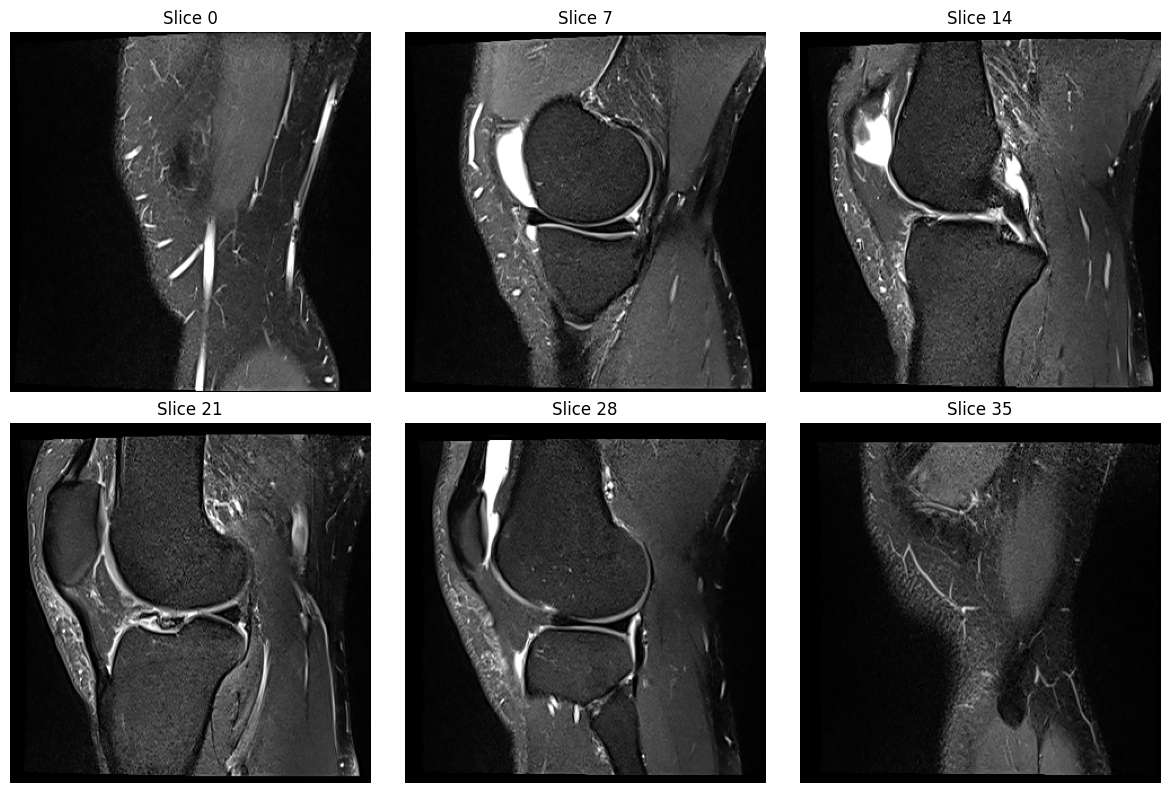

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

indices = np.linspace(0, volume.shape[0] - 1, 6).astype(int)

for ax, idx in zip(axes.ravel(), indices):
    ax.imshow(volume[idx], cmap="gray")
    ax.set_title(f"Slice {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count:", torch.cuda.device_count())
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu128
GPU available: True
GPU count: 2
GPU: Tesla T4


In [2]:
!pip install -q timm

In [3]:
import timm
import torch

print("timm:", timm.__version__)
print("CUDA:", torch.cuda.is_available())

timm: 1.0.26
CUDA: True


In [4]:
!pip install -q monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 55.0 MB/s eta 0:00:00


In [5]:
import monai

print("MONAI:", monai.__version__)

MONAI: 1.6.0


In [6]:
!pip install -q albumentations

In [7]:
import albumentations as A

print("Albumentations:", A.__version__)

Albumentations: 2.0.8


In [8]:
TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

print("Number of targets:", len(TARGETS))
print(TARGETS)

Number of targets: 12
['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


In [10]:
import pandas as pd

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

train = pd.read_csv(f"{BASE}/train.csv")
train_series = pd.read_csv(f"{BASE}/train_series.csv")

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

labeled = train[train[TARGETS].notna().any(axis=1)].copy()

labeled_data = labeled[["StudyInstanceUID"] + TARGETS].copy()

print("Total studies:", len(train))
print("Labeled studies:", len(labeled_data))

display(labeled_data.head())

Total studies: 4407
Labeled studies: 58


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,1.2.826.0.1.3680043.8.498.10095687747295410396...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,1.2.826.0.1.3680043.8.498.10170898615867673028...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,1.2.826.0.1.3680043.8.498.10306159113324811538...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
445,1.2.826.0.1.3680043.8.498.11287937729196958426...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
470,1.2.826.0.1.3680043.8.498.11382021393803389951...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
label_counts = labeled_data[TARGETS].sum().sort_values(ascending=False)

print(label_counts)

Effusion            35.0
Synovitis           27.0
Medial Meniscus     26.0
ACL                 24.0
Lateral Meniscus    23.0
PF OA               21.0
Contusion           19.0
Fracture            18.0
Medial OA           15.0
Baker's             12.0
Lateral OA          11.0
MCL                  9.0
dtype: float64


In [2]:
known_counts = labeled_data[TARGETS].notna().sum().sort_values(ascending=False)

print("Known labels per condition:")
print(known_counts)

print("\nTotal known labels:", int(known_counts.sum()))

NameError: name 'labeled_data' is not defined

In [1]:
import pandas as pd

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

train = pd.read_csv(f"{BASE}/train.csv")

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

labeled_data = train[train[TARGETS].notna().any(axis=1)].copy()

known_counts = labeled_data[TARGETS].notna().sum().sort_values(ascending=False)

print("Labeled studies:", len(labeled_data))
print("\nKnown labels per condition:")
print(known_counts)

print("\nTotal known labels:", int(known_counts.sum()))

Labeled studies: 58

Known labels per condition:
ACL                 58
MCL                 58
Medial Meniscus     58
Lateral Meniscus    58
Medial OA           58
Lateral OA          58
PF OA               58
Effusion            58
Synovitis           58
Baker's             58
Contusion           58
Fracture            58
dtype: int64

Total known labels: 696


In [2]:
print(labeled_data[TARGETS].value_counts())

ACL  MCL  Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  PF OA  Effusion  Synovitis  Baker's  Contusion  Fracture
1.0  0.0  1.0              1.0               1.0        1.0         1.0    1.0       1.0        1.0      0.0        0.0         2
0.0  1.0  0.0              0.0               0.0        0.0         0.0    0.0       0.0        0.0      0.0        0.0         2
1.0  0.0  1.0              0.0               0.0        0.0         0.0    1.0       0.0        0.0      0.0        0.0         2
                           1.0               0.0        0.0         0.0    1.0       1.0        0.0      1.0        1.0         2
0.0  0.0  0.0              0.0               0.0        0.0         0.0    0.0       0.0        0.0      0.0        1.0         1
                                                                                                         1.0        1.0         1
                                                                    1.0    0.0       1.0       

In [3]:
print(labeled_data[TARGETS].sum())
print()
print(labeled_data[TARGETS].mean().round(3))


ACL                 24.0
MCL                  9.0
Medial Meniscus     26.0
Lateral Meniscus    23.0
Medial OA           15.0
Lateral OA          11.0
PF OA               21.0
Effusion            35.0
Synovitis           27.0
Baker's             12.0
Contusion           19.0
Fracture            18.0
dtype: float64

ACL                 0.414
MCL                 0.155
Medial Meniscus     0.448
Lateral Meniscus    0.397
Medial OA           0.259
Lateral OA          0.190
PF OA               0.362
Effusion            0.603
Synovitis           0.466
Baker's             0.207
Contusion           0.328
Fracture            0.310
dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

train_ids, val_ids = train_test_split(
    labeled_data["StudyInstanceUID"],
    test_size=0.20,
    random_state=42
)

train_df = labeled_data[
    labeled_data["StudyInstanceUID"].isin(train_ids)
].reset_index(drop=True)

val_df = labeled_data[
    labeled_data["StudyInstanceUID"].isin(val_ids)
].reset_index(drop=True)

print("Training studies:", len(train_df))
print("Validation studies:", len(val_df))

Training studies: 46
Validation studies: 12


In [5]:
print("TRAINING POSITIVES")
print(train_df[TARGETS].sum())

print("\nVALIDATION POSITIVES")
print(val_df[TARGETS].sum())

TRAINING POSITIVES
ACL                 21.0
MCL                  6.0
Medial Meniscus     21.0
Lateral Meniscus    19.0
Medial OA           11.0
Lateral OA          11.0
PF OA               17.0
Effusion            27.0
Synovitis           23.0
Baker's             10.0
Contusion           17.0
Fracture            18.0
dtype: float64

VALIDATION POSITIVES
ACL                 3.0
MCL                 3.0
Medial Meniscus     5.0
Lateral Meniscus    4.0
Medial OA           4.0
Lateral OA          0.0
PF OA               4.0
Effusion            8.0
Synovitis           4.0
Baker's             2.0
Contusion           2.0
Fracture            0.0
dtype: float64


In [6]:
!pip install -q iterative-stratification

In [7]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = labeled_data["StudyInstanceUID"].values
Y = labeled_data[TARGETS].values

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(msss.split(X, Y))

train_df = labeled_data.iloc[train_idx].reset_index(drop=True)
val_df = labeled_data.iloc[val_idx].reset_index(drop=True)

print("Training studies:", len(train_df))
print("Validation studies:", len(val_df))

print("\nTRAINING POSITIVES")
print(train_df[TARGETS].sum())

print("\nVALIDATION POSITIVES")
print(val_df[TARGETS].sum())

Training studies: 47
Validation studies: 11

TRAINING POSITIVES
ACL                 19.0
MCL                  7.0
Medial Meniscus     22.0
Lateral Meniscus    18.0
Medial OA           12.0
Lateral OA           9.0
PF OA               17.0
Effusion            28.0
Synovitis           21.0
Baker's             10.0
Contusion           14.0
Fracture            14.0
dtype: float64

VALIDATION POSITIVES
ACL                 5.0
MCL                 2.0
Medial Meniscus     4.0
Lateral Meniscus    5.0
Medial OA           3.0
Lateral OA          2.0
PF OA               4.0
Effusion            7.0
Synovitis           6.0
Baker's             2.0
Contusion           5.0
Fracture            4.0
dtype: float64


In [8]:
import os
import pydicom
import numpy as np

def load_series(study_uid, series_uid):
    series_path = os.path.join(
        BASE,
        "train_series",
        study_uid,
        series_uid
    )

    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    slices = [pydicom.dcmread(f) for f in files]

    slices.sort(
        key=lambda x: float(x.ImagePositionPatient[2])
        if hasattr(x, "ImagePositionPatient")
        else float(getattr(x, "InstanceNumber", 0))
    )

    volume = np.stack([s.pixel_array for s in slices])

    return volume

print("MRI series loader created.")

MRI series loader created.


In [10]:
import pandas as pd

# Reload train_series
train_series = pd.read_csv(f"{BASE}/train_series.csv")

# Take the first training study
test_study = train_df.iloc[0]["StudyInstanceUID"]

# Find its MRI series
available_series = train_series[
    train_series["StudyInstanceUID"] == test_study
]

# Prefer sagittal fluid-sensitive + fat-suppressed
preferred = available_series[
    (available_series["Anatomical_Plane"] == "Sagittal") &
    (available_series["Fluid_Sensitive"] == 1) &
    (available_series["Fat_Suppression"] == 1)
]

if len(preferred) > 0:
    chosen_series = preferred.iloc[0]
else:
    chosen_series = available_series.iloc[0]

test_series_uid = chosen_series["SeriesInstanceUID"]

volume = load_series(test_study, test_series_uid)

print("Study UID:", test_study)
print("Series UID:", test_series_uid)
print("Plane:", chosen_series["Anatomical_Plane"])
print("Fluid Sensitive:", chosen_series["Fluid_Sensitive"])
print("Fat Suppression:", chosen_series["Fat_Suppression"])
print("Volume shape:", volume.shape)

Study UID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Series UID: 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
Plane: Sagittal
Fluid Sensitive: 1
Fat Suppression: 1
Volume shape: (36, 320, 320)


In [11]:
def normalize_volume(volume):
    volume = volume.astype(np.float32)

    low, high = np.percentile(volume, [1, 99])

    volume = np.clip(volume, low, high)
    volume = (volume - low) / (high - low + 1e-8)

    return volume


normalized_volume = normalize_volume(volume)

print("Shape:", normalized_volume.shape)
print("Minimum:", normalized_volume.min())
print("Maximum:", normalized_volume.max())

Shape: (36, 320, 320)
Minimum: 0.0
Maximum: 0.9999999999748743


In [12]:
import cv2

def resize_volume(volume, size=(224, 224)):
    resized = np.zeros(
        (volume.shape[0], size[0], size[1]),
        dtype=np.float32
    )

    for i in range(volume.shape[0]):
        resized[i] = cv2.resize(
            volume[i],
            size,
            interpolation=cv2.INTER_AREA
        )

    return resized


resized_volume = resize_volume(normalized_volume)

print("Original shape:", normalized_volume.shape)
print("Resized shape:", resized_volume.shape)

Original shape: (36, 320, 320)
Resized shape: (36, 224, 224)


In [13]:
import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=12
)

model = model.to(device)

print("Model:", type(model).__name__)
print("Device:", device)

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Model: EfficientNet
Device: cuda


In [14]:
def select_slices(volume, num_slices=8):
    indices = np.linspace(
        0,
        volume.shape[0] - 1,
        num_slices
    ).astype(int)

    return volume[indices], indices


sampled_slices, slice_indices = select_slices(
    resized_volume,
    num_slices=8
)

print("Selected slice indices:", slice_indices)
print("Selected slices shape:", sampled_slices.shape)

Selected slice indices: [ 0  5 10 15 20 25 30 35]
Selected slices shape: (8, 224, 224)


In [15]:
# Convert 8 grayscale MRI slices into 3-channel tensors

slice_tensor = torch.tensor(
    sampled_slices,
    dtype=torch.float32
)

# (8, 224, 224) → (8, 3, 224, 224)
slice_tensor = slice_tensor.unsqueeze(1).repeat(1, 3, 1, 1)

# Move to GPU
slice_tensor = slice_tensor.to(device)

print("Tensor shape:", slice_tensor.shape)
print("Device:", slice_tensor.device)

Tensor shape: torch.Size([8, 3, 224, 224])
Device: cuda:0


In [16]:
import torch
import timm

feature_model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=0,
    global_pool="avg"
)

feature_model = feature_model.to(device)
feature_model.eval()

with torch.no_grad():
    features = feature_model(slice_tensor)

print("Feature shape:", features.shape)

Feature shape: torch.Size([8, 1280])


In [17]:
# Average the features from all 8 slices
study_features = features.mean(dim=0)

print("Study feature shape:", study_features.shape)

Study feature shape: torch.Size([1280])


In [18]:
import torch.nn as nn

classifier = nn.Sequential(
    nn.Linear(1280, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 12)
).to(device)

print(classifier)

Sequential(
  (0): Linear(in_features=1280, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=12, bias=True)
)


In [19]:
import torch
import torch.nn as nn
import timm


class KneeNovaBaseline(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()

        # Pretrained EfficientNet feature extractor
        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        # Study-level classifier
        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        # x shape: (batch, slices, channels, height, width)

        batch_size, num_slices, channels, height, width = x.shape

        # Combine batch and slice dimensions
        x = x.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        # Extract features from each slice
        features = self.encoder(x)

        # Restore slice dimension
        features = features.view(
            batch_size,
            num_slices,
            -1
        )

        # Combine slice features into study representation
        study_features = features.mean(dim=1)

        # Predict 12 abnormalities
        output = self.classifier(study_features)

        return output


model = KneeNovaBaseline(num_classes=12).to(device)

print(model)

KneeNovaBaseline(
  (encoder): EfficientNet(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv_pw

In [20]:
# Freeze the pretrained EfficientNet encoder
for param in model.encoder.parameters():
    param.requires_grad = False

# Keep only the classification head trainable
for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 4669576
Trainable parameters: 662028


In [21]:
criterion = torch.nn.BCEWithLogitsLoss()

print("Loss function: BCEWithLogitsLoss")

Loss function: BCEWithLogitsLoss


In [22]:
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")

Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001


In [23]:
from torch.utils.data import Dataset

class KneeNovaDataset(Dataset):
    def __init__(self, dataframe, train_series, base_path, num_slices=8):
        self.df = dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        # Find series for this study
        study_series = self.train_series[
            self.train_series["StudyInstanceUID"] == study_uid
        ]

        # Prefer sagittal fluid-sensitive + fat-suppressed
        preferred = study_series[
            (study_series["Anatomical_Plane"] == "Sagittal") &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        if len(preferred) > 0:
            series_row = preferred.iloc[0]
        else:
            series_row = study_series.iloc[0]

        series_uid = series_row["SeriesInstanceUID"]

        # Load MRI volume
        volume = load_series(study_uid, series_uid)

        # Normalize
        volume = normalize_volume(volume)

        # Resize
        volume = resize_volume(volume, size=(224, 224))

        # Select representative slices
        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        # Convert to tensor
        image = torch.tensor(volume, dtype=torch.float32)

        # Grayscale -> 3 channels
        image = image.unsqueeze(1).repeat(1, 3, 1, 1)

        # Labels
        labels = torch.tensor(
            row[TARGETS].values.astype(np.float32)
        )

        return image, labels


print("KneeNovaDataset created.")

KneeNovaDataset created.


In [24]:
train_dataset = KneeNovaDataset(
    dataframe=train_df,
    train_series=train_series,
    base_path=BASE,
    num_slices=8
)

val_dataset = KneeNovaDataset(
    dataframe=val_df,
    train_series=train_series,
    base_path=BASE,
    num_slices=8
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 47
Validation samples: 11


In [25]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label shape:", label.shape)
print("Labels:", label)
print("Image minimum:", image.min().item())
print("Image maximum:", image.max().item())

Image shape: torch.Size([8, 3, 224, 224])
Label shape: torch.Size([12])
Labels: tensor([0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0.])
Image minimum: 0.0
Image maximum: 1.0


In [26]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 24
Validation batches: 6


In [27]:
batch_images, batch_labels = next(iter(train_loader))

print("Batch image shape:", batch_images.shape)
print("Batch label shape:", batch_labels.shape)

Batch image shape: torch.Size([2, 8, 3, 224, 224])
Batch label shape: torch.Size([2, 12])


In [28]:
model.eval()

with torch.no_grad():
    batch_images = batch_images.to(device)
    outputs = model(batch_images)

print("Input shape:", batch_images.shape)
print("Output shape:", outputs.shape)
print("Raw outputs:", outputs)

Input shape: torch.Size([2, 8, 3, 224, 224])
Output shape: torch.Size([2, 12])
Raw outputs: tensor([[-0.0423,  0.0886,  0.1203,  0.0121,  0.0580, -0.0153,  0.0663, -0.0582,
         -0.0984, -0.0748,  0.1776, -0.0573],
        [-0.0542,  0.0639,  0.1005,  0.0651,  0.1686,  0.1174,  0.0511, -0.0206,
         -0.0077, -0.0766,  0.2503, -0.0263]], device='cuda:0')


In [29]:
probabilities = torch.sigmoid(outputs)

print("Probabilities:")
print(probabilities)
print("\nRange:", probabilities.min().item(), "to", probabilities.max().item())

Probabilities:
tensor([[0.4894, 0.5221, 0.5300, 0.5030, 0.5145, 0.4962, 0.5166, 0.4854, 0.4754,
         0.4813, 0.5443, 0.4857],
        [0.4864, 0.5160, 0.5251, 0.5163, 0.5421, 0.5293, 0.5128, 0.4949, 0.4981,
         0.4809, 0.5622, 0.4934]], device='cuda:0')

Range: 0.4754100739955902 to 0.5622474551200867


In [30]:
import torch

EPOCHS = 10

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    # --------------------
    # Training
    # --------------------
    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    # --------------------
    # Validation
    # --------------------
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 1/10 | Train Loss: 0.6549 | Val Loss: 0.6442
Epoch 2/10 | Train Loss: 0.6236 | Val Loss: 0.6386
Epoch 3/10 | Train Loss: 0.6178 | Val Loss: 0.6318
Epoch 4/10 | Train Loss: 0.6175 | Val Loss: 0.6350
Epoch 5/10 | Train Loss: 0.6183 | Val Loss: 0.6315
Epoch 6/10 | Train Loss: 0.5891 | Val Loss: 0.6290
Epoch 7/10 | Train Loss: 0.6003 | Val Loss: 0.6330
Epoch 8/10 | Train Loss: 0.5892 | Val Loss: 0.6273
Epoch 9/10 | Train Loss: 0.5683 | Val Loss: 0.6337
Epoch 10/10 | Train Loss: 0.5798 | Val Loss: 0.6368


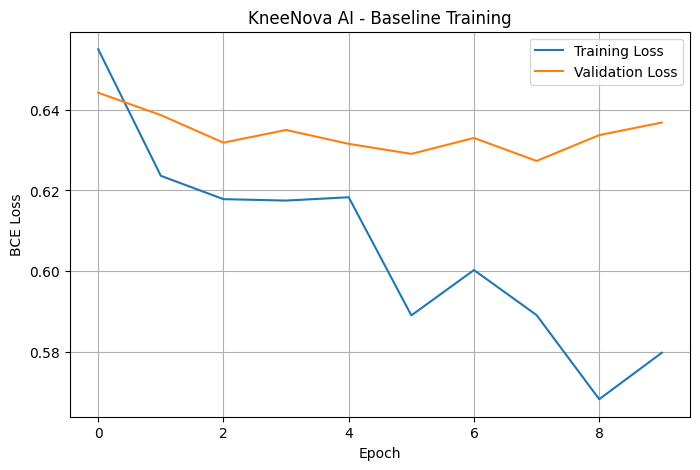

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("KneeNova AI - Baseline Training")
plt.legend()
plt.grid(True)

plt.show()

In [32]:
from sklearn.metrics import roc_auc_score
import numpy as np
import torch

model.eval()

all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        
        outputs = model(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        
        all_probs.append(probs)
        all_labels.append(labels.numpy())

all_probs = np.concatenate(all_probs, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

print("Validation shape:", all_probs.shape)

print("\nROC-AUC per abnormality:")

for i, target in enumerate(TARGETS):
    y_true = all_labels[:, i]
    y_score = all_probs[:, i]
    
    # AUC requires both positive and negative examples
    if len(np.unique(y_true)) < 2:
        print(f"{target}: N/A")
    else:
        auc = roc_auc_score(y_true, y_score)
        print(f"{target}: {auc:.4f}")

Validation shape: (11, 12)

ROC-AUC per abnormality:
ACL: 0.6333
MCL: 0.3333
Medial Meniscus: 0.3929
Lateral Meniscus: 0.6667
Medial OA: 0.5000
Lateral OA: 0.6667
PF OA: 0.5000
Effusion: 0.6786
Synovitis: 0.3667
Baker's: 0.8889
Contusion: 0.5667
Fracture: 0.5714


In [33]:
torch.save(
    model.state_dict(),
    "/kaggle/working/kneenova_baseline.pth"
)

print("Baseline model saved.")

Baseline model saved.


In [34]:
# Inspect reports from the labeled studies

for i in range(min(5, len(labeled_data))):
    study_id = labeled_data.iloc[i]["StudyInstanceUID"]
    report = train.loc[
        train["StudyInstanceUID"] == study_id,
        "Report"
    ].iloc[0]

    print("=" * 100)
    print("Study:", study_id)
    print(report)
    print()

Study: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea
femoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región
central de la simple femoral. Cartílago rotuliano sin alteraciones.
Leve derrame articular. No hay quistes poplíteos patológicos.
Aumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del
tendón rotuliano, sin signos de rotura.
No hay alteraciones de señal de la grasa de Hoffa.
Impresión:
Amputación marginal del cuerpo de

In [35]:
import re

reports = train[["StudyInstanceUID", "Report"]].copy()

def clean_report(text):
    if pd.isna(text):
        return ""
    
    text = str(text).lower()
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    
    return text.strip()

reports["clean_report"] = reports["Report"].apply(clean_report)

print("Total reports:", len(reports))
print()
print(reports[["StudyInstanceUID", "clean_report"]].head(3))

Total reports: 4407

                                    StudyInstanceUID  \
0  1.2.826.0.1.3680043.8.498.10004873229099053869...   
1  1.2.826.0.1.3680043.8.498.10004945927472656027...   
2  1.2.826.0.1.3680043.8.498.10009278692606631573...   

                                        clean_report  
0  técnica: rmn de la rodilla. resultados: rotura...  
1  [date]: * mr knie rechts 15ch aa klinische inl...  
2  hallazgos: no hay alteraciones en significativ...  


In [36]:
KEYWORDS = {
    "ACL": [
        "acl", "anterior cruciate ligament",
        "ligamento cruzado anterior",
        "ligament croisé antérieur",
        "vordere kreuzband", "vorderes kreuzband",
        "ön çapraz bağ"
    ],
    
    "MCL": [
        "mcl", "medial collateral ligament",
        "ligamento colateral medial",
        "ligament collatéral médial",
        "mediales kollateralband",
        "mediales seitenband",
        "medial kollateral bağ"
    ],
    
    "Medial Meniscus": [
        "medial meniscus", "medial meniscal",
        "menisco medial", "menisco interno",
        "menisque médial",
        "medialer meniskus",
        "medial menisküs"
    ],
    
    "Lateral Meniscus": [
        "lateral meniscus", "lateral meniscal",
        "menisco lateral", "menisque latéral",
        "lateraler meniskus",
        "lateral menisküs"
    ],
    
    "Medial OA": [
        "medial osteoarthritis",
        "medial compartment osteoarthritis",
        "medial compartment",
        "artrosis femorotibial medial",
        "gonarthrose médiale",
        "mediale osteoarthrose"
    ],
    
    "Lateral OA": [
        "lateral osteoarthritis",
        "lateral compartment osteoarthritis",
        "lateral compartment",
        "artrosis femorotibial lateral",
        "gonarthrose latérale",
        "laterale osteoarthrose"
    ],
    
    "PF OA": [
        "patellofemoral osteoarthritis",
        "patellofemoral",
        "patellofemoral compartment",
        "artrosis patelofemoral",
        "arthrose fémoro-patellaire",
        "patellofemorale osteoarthrose"
    ],
    
    "Effusion": [
        "joint effusion", "effusion",
        "derrame articular", "derrame",
        "épanchement",
        "gelenkerguss",
        "eklem efüzyonu"
    ],
    
    "Synovitis": [
        "synovitis",
        "synovial thickening",
        "thickened synovial tissue",
        "sinovitis",
        "synoviale verdickung",
        "synoviale kalınlaşma"
    ],
    
    "Baker's": [
        "baker's cyst", "baker cyst",
        "popliteal cyst",
        "quiste poplíteo",
        "kyste poplité",
        "baker-zyste",
        "baker kisti"
    ],
    
    "Contusion": [
        "bone contusion", "bone bruise",
        "bone marrow edema", "marrow edema",
        "contusión ósea",
        "contusion osseuse",
        "knochenprellung"
    ],
    
    "Fracture": [
        "fracture",
        "fractura",
        "fraktur",
        "fracture osseuse",
        "kırık"
    ]
}

print("Number of targets:", len(KEYWORDS))
for target, terms in KEYWORDS.items():
    print(f"{target}: {len(terms)} keywords")

Number of targets: 12
ACL: 7 keywords
MCL: 7 keywords
Medial Meniscus: 7 keywords
Lateral Meniscus: 6 keywords
Medial OA: 6 keywords
Lateral OA: 6 keywords
PF OA: 6 keywords
Effusion: 7 keywords
Synovitis: 6 keywords
Baker's: 7 keywords
Contusion: 7 keywords
Fracture: 5 keywords


In [37]:
NEGATION_WORDS = [
    "no",
    "not",
    "without",
    "negative for",
    "absent",
    "normal",
    "intact",
    "none",
    "neither",
    "no evidence of",
    "no sign of"
]

def is_negated(text, keyword, window=80):
    """
    Check whether a keyword is preceded by a common
    negation phrase within a limited text window.
    """
    positions = []
    start = 0

    while True:
        pos = text.find(keyword, start)

        if pos == -1:
            break

        positions.append(pos)
        start = pos + len(keyword)

    for pos in positions:
        context = text[max(0, pos - window):pos]

        for neg in NEGATION_WORDS:
            if neg in context:
                return True

    return False


# Test examples
test_1 = "acl is intact."
test_2 = "complete tear of the anterior cruciate ligament."
test_3 = "no knee effusion is present."

print("Test 1:", is_negated(test_1, "acl"))
print("Test 2:", is_negated(test_2, "anterior cruciate ligament"))
print("Test 3:", is_negated(test_3, "effusion"))

Test 1: False
Test 2: False
Test 3: True


In [39]:
import re

NEGATION_PATTERNS = [
    r"\bno\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bwithout\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bKEYWORD\s+is\s+intact\b",
    r"\bKEYWORD\s+is\s+normal\b",
    r"\bKEYWORD\s+(?:appears|remain|remains)\s+normal\b",
    r"\bno\s+evidence\s+of\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bno\s+signs?\s+of\s+(?:\w+\s+){0,4}KEYWORD\b",
]

def is_negated_improved(text, keyword):
    text = text.lower()
    keyword = re.escape(keyword.lower())

    for pattern in NEGATION_PATTERNS:
        pattern = pattern.replace("KEYWORD", keyword)

        if re.search(pattern, text):
            return True

    return False


# Test cases
tests = [
    ("acl is intact.", "acl"),
    ("complete tear of the anterior cruciate ligament.", "anterior cruciate ligament"),
    ("no knee effusion is present.", "effusion"),
    ("without fracture.", "fracture"),
    ("the medial meniscus is normal.", "medial meniscus"),
]

for text, keyword in tests:
    print(text, "→", is_negated_improved(text, keyword))

acl is intact. → True
complete tear of the anterior cruciate ligament. → False
no knee effusion is present. → True
without fracture. → True
the medial meniscus is normal. → True


In [40]:
def detect_finding(text, keywords):
    text = text.lower()

    for keyword in keywords:
        if keyword.lower() in text:
            if not is_negated_improved(text, keyword):
                return 1

    return 0


def extract_report_labels(text):
    labels = {}

    for target, keywords in KEYWORDS.items():
        labels[target] = detect_finding(text, keywords)

    return labels


# Test on first 10 reports
for i in range(10):
    text = reports.iloc[i]["clean_report"]
    extracted = extract_report_labels(text)

    print("=" * 80)
    print("Study:", reports.iloc[i]["StudyInstanceUID"])
    print(extracted)

Study: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
{'ACL': 0, 'MCL': 0, 'Medial Meniscus': 1, 'Lateral Meniscus': 0, 'Medial OA': 1, 'Lateral OA': 0, 'PF OA': 0, 'Effusion': 1, 'Synovitis': 0, "Baker's": 0, 'Contusion': 0, 'Fracture': 0}
Study: 1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585
{'ACL': 0, 'MCL': 0, 'Medial Meniscus': 0, 'Lateral Meniscus': 0, 'Medial OA': 0, 'Lateral OA': 0, 'PF OA': 0, 'Effusion': 0, 'Synovitis': 0, "Baker's": 0, 'Contusion': 0, 'Fracture': 0}
Study: 1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231
{'ACL': 0, 'MCL': 0, 'Medial Meniscus': 1, 'Lateral Meniscus': 1, 'Medial OA': 0, 'Lateral OA': 0, 'PF OA': 0, 'Effusion': 0, 'Synovitis': 0, "Baker's": 0, 'Contusion': 0, 'Fracture': 0}
Study: 1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764
{'ACL': 0, 'MCL': 1, 'Medial Meniscus': 0, 'Lateral Meniscus': 1, 'Medial OA': 1, 'Lateral OA': 1, 'PF OA': 1, 'Effusion': 0, 'Synovitis': 0, "Baker's"

In [41]:
# Create report-based labels for all reports
report_label_rows = []

for _, row in reports.iterrows():
    extracted = extract_report_labels(row["clean_report"])
    extracted["StudyInstanceUID"] = row["StudyInstanceUID"]
    report_label_rows.append(extracted)

report_labels = pd.DataFrame(report_label_rows)

# Keep the same target order
report_labels = report_labels[
    ["StudyInstanceUID"] + TARGETS
]

# Merge with the official labels
comparison = labeled_data.merge(
    report_labels,
    on="StudyInstanceUID",
    suffixes=("_true", "_report")
)

print("Labeled studies compared:", len(comparison))

# Calculate agreement for each target
for target in TARGETS:
    true_values = comparison[f"{target}_true"]
    report_values = comparison[f"{target}_report"]

    accuracy = (true_values == report_values).mean()

    print(f"{target}: {accuracy:.3f}")

Labeled studies compared: 58
ACL: 0.569
MCL: 0.621
Medial Meniscus: 0.534
Lateral Meniscus: 0.638
Medial OA: 0.724
Lateral OA: 0.724
PF OA: 0.500
Effusion: 0.569
Synovitis: 0.621
Baker's: 0.828
Contusion: 0.724
Fracture: 0.776


In [42]:
report_labels.to_csv(
    "/kaggle/working/kneenova_report_labels.csv",
    index=False
)

print("Report-derived labels saved.")

Report-derived labels saved.


In [43]:
!pip install -q transformers sentencepiece

In [44]:
import transformers

print("Transformers:", transformers.__version__)

Transformers: 5.0.0


In [45]:
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
text_model = AutoModel.from_pretrained(MODEL_NAME)

text_model = text_model.to(device)
text_model.eval()

print("Model loaded:", MODEL_NAME)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded: xlm-roberta-base


In [46]:
sample_text = reports.iloc[0]["clean_report"]

inputs = tokenizer(
    sample_text,
    return_tensors="pt",
    truncation=True,
    max_length=256,
    padding=True
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs_text = text_model(**inputs)

text_features = outputs_text.last_hidden_state[:, 0, :]

print("Input text length:", len(sample_text))
print("Text feature shape:", text_features.shape)

Input text length: 322
Text feature shape: torch.Size([1, 768])


In [47]:
sample_texts = reports["clean_report"].head(100).tolist()

token_lengths = []

for text in sample_texts:
    tokens = tokenizer(
        text,
        truncation=False,
        add_special_tokens=True
    )

    token_lengths.append(len(tokens["input_ids"]))

print("Minimum tokens:", min(token_lengths))
print("Maximum tokens:", max(token_lengths))
print("Average tokens:", sum(token_lengths) / len(token_lengths))

Token indices sequence length is longer than the specified maximum sequence length for this model (528 > 512). Running this sequence through the model will result in indexing errors


Minimum tokens: 41
Maximum tokens: 884
Average tokens: 295.39


In [48]:
sample_text = reports.iloc[0]["clean_report"]

inputs = tokenizer(
    sample_text,
    return_tensors="pt",
    truncation=True,
    max_length=512,
    padding="max_length"
)

print("Tokenized shape:", inputs["input_ids"].shape)
print("Maximum length:", inputs["input_ids"].shape[1])

Tokenized shape: torch.Size([1, 512])
Maximum length: 512


In [49]:
def extract_text_features(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=512,
        padding="max_length"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = text_model(**inputs)

    # Use the first token representation
    features = outputs.last_hidden_state[:, 0, :]

    return features.squeeze(0).cpu()


# Test on one report
sample_features = extract_text_features(
    reports.iloc[0]["clean_report"]
)

print("Text feature shape:", sample_features.shape)

Text feature shape: torch.Size([768])


In [50]:
import torch

# MRI feature vector: 1280
# Text feature vector: 768

mri_features = study_features.detach().to(device)
text_features_gpu = sample_features.to(device)

# Combine them
fused_features = torch.cat(
    [mri_features, text_features_gpu],
    dim=0
)

print("MRI features:", mri_features.shape)
print("Text features:", text_features_gpu.shape)
print("Fused features:", fused_features.shape)

MRI features: torch.Size([1280])
Text features: torch.Size([768])
Fused features: torch.Size([2048])


In [51]:
import torch.nn as nn

teacher_head = nn.Sequential(
    nn.Linear(2048, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 12)
).to(device)

print(teacher_head)

Sequential(
  (0): Linear(in_features=2048, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=12, bias=True)
)


In [52]:
class KneeNovaTeacher(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()

        # MRI encoder
        self.image_encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        # Report encoder
        self.text_encoder = AutoModel.from_pretrained(
            "xlm-roberta-base"
        )

        # Fusion + classifier
        self.classifier = nn.Sequential(
            nn.Linear(1280 + 768, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, images, input_ids, attention_mask):

        # images:
        # (batch, slices, channels, height, width)

        batch_size, num_slices, channels, height, width = images.shape

        # Flatten slices
        images = images.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        # MRI features
        image_features = self.image_encoder(images)

        image_features = image_features.view(
            batch_size,
            num_slices,
            -1
        )

        # Study-level MRI feature
        image_features = image_features.mean(dim=1)

        # Text features
        text_outputs = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        text_features = text_outputs.last_hidden_state[:, 0, :]

        # Fuse MRI + text
        fused = torch.cat(
            [image_features, text_features],
            dim=1
        )

        # Final predictions
        output = self.classifier(fused)

        return output


teacher = KneeNovaTeacher(num_classes=12).to(device)

print("KneeNova multimodal teacher created.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


KneeNova multimodal teacher created.


In [53]:
teacher.eval()

# Use the first training study
sample_image, sample_label = train_dataset[0]

# Add batch dimension
sample_image = sample_image.unsqueeze(0).to(device)

sample_study_id = train_df.iloc[0]["StudyInstanceUID"]

sample_report = reports.loc[
    reports["StudyInstanceUID"] == sample_study_id,
    "clean_report"
].iloc[0]

text_inputs = tokenizer(
    sample_report,
    return_tensors="pt",
    truncation=True,
    max_length=512,
    padding="max_length"
)

input_ids = text_inputs["input_ids"].to(device)
attention_mask = text_inputs["attention_mask"].to(device)

with torch.no_grad():
    teacher_output = teacher(
        sample_image,
        input_ids,
        attention_mask
    )

print("MRI input:", sample_image.shape)
print("Text input:", input_ids.shape)
print("Teacher output:", teacher_output.shape)

MRI input: torch.Size([1, 8, 3, 224, 224])
Text input: torch.Size([1, 512])
Teacher output: torch.Size([1, 12])


In [54]:
# Freeze MRI encoder
for param in teacher.image_encoder.parameters():
    param.requires_grad = False

# Freeze text encoder
for param in teacher.text_encoder.parameters():
    param.requires_grad = False

# Keep only fusion/classification head trainable
for param in teacher.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in teacher.parameters()
)

trainable_params = sum(
    p.numel() for p in teacher.parameters()
    if p.requires_grad
)

print("Total teacher parameters:", total_params)
print("Trainable teacher parameters:", trainable_params)

Total teacher parameters: 283106440
Trainable teacher parameters: 1055244


In [55]:
teacher_criterion = torch.nn.BCEWithLogitsLoss()

teacher_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, teacher.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

print("Teacher loss: BCEWithLogitsLoss")
print("Teacher optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")

Teacher loss: BCEWithLogitsLoss
Teacher optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001


In [56]:
from torch.utils.data import Dataset

class KneeNovaTeacherDataset(Dataset):
    def __init__(
        self,
        dataframe,
        train_series,
        reports,
        base_path,
        tokenizer,
        num_slices=8,
        max_length=512
    ):
        self.df = dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.reports = reports
        self.base_path = base_path
        self.tokenizer = tokenizer
        self.num_slices = num_slices
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        # -------------------------
        # 1. Find MRI series
        # -------------------------
        study_series = self.train_series[
            self.train_series["StudyInstanceUID"] == study_uid
        ]

        preferred = study_series[
            (study_series["Anatomical_Plane"] == "Sagittal") &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        if len(preferred) > 0:
            series_row = preferred.iloc[0]
        else:
            series_row = study_series.iloc[0]

        series_uid = series_row["SeriesInstanceUID"]

        # -------------------------
        # 2. Load MRI
        # -------------------------
        volume = load_series(study_uid, series_uid)

        # Normalize
        volume = normalize_volume(volume)

        # Resize
        volume = resize_volume(volume, size=(224, 224))

        # Select representative slices
        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        # Convert to tensor
        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        # Grayscale → 3 channels
        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        # -------------------------
        # 3. Get report
        # -------------------------
        report = self.reports.loc[
            self.reports["StudyInstanceUID"] == study_uid,
            "clean_report"
        ].iloc[0]

        text = self.tokenizer(
            report,
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt"
        )

        input_ids = text["input_ids"].squeeze(0)
        attention_mask = text["attention_mask"].squeeze(0)

        # -------------------------
        # 4. Labels
        # -------------------------
        labels = torch.tensor(
            row[TARGETS].values.astype(np.float32)
        )

        return (
            image,
            input_ids,
            attention_mask,
            labels
        )


print("KneeNovaTeacherDataset created.")

KneeNovaTeacherDataset created.


In [57]:
teacher_train_dataset = KneeNovaTeacherDataset(
    dataframe=train_df,
    train_series=train_series,
    reports=reports,
    base_path=BASE,
    tokenizer=tokenizer,
    num_slices=8,
    max_length=512
)

teacher_val_dataset = KneeNovaTeacherDataset(
    dataframe=val_df,
    train_series=train_series,
    reports=reports,
    base_path=BASE,
    tokenizer=tokenizer,
    num_slices=8,
    max_length=512
)

teacher_train_loader = DataLoader(
    teacher_train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

teacher_val_loader = DataLoader(
    teacher_val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Teacher training studies:", len(teacher_train_dataset))
print("Teacher validation studies:", len(teacher_val_dataset))
print("Teacher training batches:", len(teacher_train_loader))
print("Teacher validation batches:", len(teacher_val_loader))

Teacher training studies: 47
Teacher validation studies: 11
Teacher training batches: 47
Teacher validation batches: 11


In [58]:
teacher_batch = next(iter(teacher_train_loader))

batch_images, batch_input_ids, batch_attention_mask, batch_labels = teacher_batch

print("MRI shape:", batch_images.shape)
print("Input IDs shape:", batch_input_ids.shape)
print("Attention mask shape:", batch_attention_mask.shape)
print("Labels shape:", batch_labels.shape)

MRI shape: torch.Size([1, 8, 3, 224, 224])
Input IDs shape: torch.Size([1, 512])
Attention mask shape: torch.Size([1, 512])
Labels shape: torch.Size([1, 12])


In [59]:
teacher.train()

images, input_ids, attention_mask, labels = next(iter(teacher_train_loader))

images = images.to(device)
input_ids = input_ids.to(device)
attention_mask = attention_mask.to(device)
labels = labels.to(device)

teacher_optimizer.zero_grad()

outputs = teacher(
    images,
    input_ids,
    attention_mask
)

loss = teacher_criterion(outputs, labels)

loss.backward()
teacher_optimizer.step()

print("Teacher output shape:", outputs.shape)
print("Training loss:", loss.item())

Teacher output shape: torch.Size([1, 12])
Training loss: 0.6619662046432495


In [60]:
EPOCHS = 5

teacher_train_losses = []
teacher_val_losses = []

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    teacher.train()
    running_train_loss = 0.0

    for images, input_ids, attention_mask, labels in teacher_train_loader:

        images = images.to(device, non_blocking=True)
        input_ids = input_ids.to(device, non_blocking=True)
        attention_mask = attention_mask.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        teacher_optimizer.zero_grad()

        outputs = teacher(
            images,
            input_ids,
            attention_mask
        )

        loss = teacher_criterion(outputs, labels)

        loss.backward()
        teacher_optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(teacher_train_loader)

    # -------------------------
    # Validation
    # -------------------------
    teacher.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for images, input_ids, attention_mask, labels in teacher_val_loader:

            images = images.to(device, non_blocking=True)
            input_ids = input_ids.to(device, non_blocking=True)
            attention_mask = attention_mask.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = teacher(
                images,
                input_ids,
                attention_mask
            )

            loss = teacher_criterion(outputs, labels)

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(teacher_val_loader)

    teacher_train_losses.append(train_loss)
    teacher_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6629 | Val Loss: 0.6364
Epoch 2/5 | Train Loss: 0.6478 | Val Loss: 0.6398
Epoch 3/5 | Train Loss: 0.6300 | Val Loss: 0.6404
Epoch 4/5 | Train Loss: 0.6417 | Val Loss: 0.6696
Epoch 5/5 | Train Loss: 0.6448 | Val Loss: 0.6370


In [61]:
torch.save(
    teacher.state_dict(),
    "/kaggle/working/kneenova_teacher.pth"
)

print("Teacher model saved.")

Teacher model saved.


In [62]:
student = KneeNovaBaseline(num_classes=12).to(device)

print("KneeNova MRI-only student created.")

KneeNova MRI-only student created.


In [63]:
for param in student.encoder.parameters():
    param.requires_grad = False

for param in student.classifier.parameters():
    param.requires_grad = True

student_trainable = sum(
    p.numel()
    for p in student.parameters()
    if p.requires_grad
)

print("Student trainable parameters:", student_trainable)

Student trainable parameters: 662028


In [64]:
student_criterion = torch.nn.BCEWithLogitsLoss()

student_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, student.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

print("Student loss: BCEWithLogitsLoss")
print("Student optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")

Student loss: BCEWithLogitsLoss
Student optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001


In [66]:
student.eval()
teacher.eval()

# Move MRI batch to GPU
student_images = batch_images.to(device)

# Move teacher inputs to GPU
teacher_images = images.to(device)
teacher_input_ids = input_ids.to(device)
teacher_attention_mask = attention_mask.to(device)

with torch.no_grad():

    student_outputs = student(student_images)

    teacher_outputs = teacher(
        teacher_images,
        teacher_input_ids,
        teacher_attention_mask
    )

print("Student output shape:", student_outputs.shape)
print("Teacher output shape:", teacher_outputs.shape)

Student output shape: torch.Size([1, 12])
Teacher output shape: torch.Size([1, 12])


In [67]:
with torch.no_grad():

    student_probs = torch.sigmoid(student_outputs)
    teacher_probs = torch.sigmoid(teacher_outputs)

print("Student probabilities:")
print(student_probs.cpu().numpy())

print("\nTeacher probabilities:")
print(teacher_probs.cpu().numpy())

Student probabilities:
[[0.49823326 0.505896   0.5281475  0.51139927 0.49167433 0.48842037
  0.5057892  0.51423043 0.54817635 0.5146051  0.48379183 0.4830508 ]]

Teacher probabilities:
[[0.45237488 0.1691651  0.48218063 0.3508646  0.30592635 0.24593164
  0.36041144 0.6052554  0.43669978 0.25532097 0.43056968 0.37769762]]


In [68]:
import torch.nn.functional as F

def distillation_loss(
    student_logits,
    teacher_logits,
    true_labels,
    alpha=0.5,
    temperature=2.0
):
    # Normal supervised loss
    supervised_loss = F.binary_cross_entropy_with_logits(
        student_logits,
        true_labels
    )

    # Soft probabilities from teacher
    teacher_probs = torch.sigmoid(
        teacher_logits / temperature
    )

    # Student probabilities
    student_probs = torch.sigmoid(
        student_logits / temperature
    )

    # Distillation loss
    soft_loss = F.binary_cross_entropy(
        student_probs,
        teacher_probs
    )

    # Combined loss
    total_loss = (
        alpha * soft_loss
        + (1 - alpha) * supervised_loss
    )

    return total_loss


print("Knowledge distillation loss created.")

Knowledge distillation loss created.


In [69]:
loss_value = distillation_loss(
    student_outputs,
    teacher_outputs,
    batch_labels.to(device),
    alpha=0.5,
    temperature=2.0
)

print("Distillation loss:", loss_value.item())

Distillation loss: 0.6978046894073486


In [70]:
student_epochs = 5

student_train_losses = []
student_val_losses = []

for epoch in range(student_epochs):

    # -------------------------
    # Training
    # -------------------------
    student.train()
    teacher.eval()

    running_train_loss = 0.0

    for images, input_ids, attention_mask, labels in teacher_train_loader:

        images = images.to(device, non_blocking=True)
        input_ids = input_ids.to(device, non_blocking=True)
        attention_mask = attention_mask.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Teacher predictions
        with torch.no_grad():
            teacher_outputs = teacher(
                images,
                input_ids,
                attention_mask
            )

        # Student predictions
        student_optimizer.zero_grad()

        student_outputs = student(images)

        # Distillation loss
        loss = distillation_loss(
            student_outputs,
            teacher_outputs,
            labels,
            alpha=0.5,
            temperature=2.0
        )

        loss.backward()
        student_optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(teacher_train_loader)

    # -------------------------
    # Validation
    # -------------------------
    student.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for images, input_ids, attention_mask, labels in teacher_val_loader:

            images = images.to(device, non_blocking=True)
            input_ids = input_ids.to(device, non_blocking=True)
            attention_mask = attention_mask.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Teacher predictions
            teacher_outputs = teacher(
                images,
                input_ids,
                attention_mask
            )

            # Student predictions
            student_outputs = student(images)

            loss = distillation_loss(
                student_outputs,
                teacher_outputs,
                labels,
                alpha=0.5,
                temperature=2.0
            )

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(teacher_val_loader)

    student_train_losses.append(train_loss)
    student_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{student_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6677 | Val Loss: 0.6664
Epoch 2/5 | Train Loss: 0.6596 | Val Loss: 0.6593
Epoch 3/5 | Train Loss: 0.6601 | Val Loss: 0.6617
Epoch 4/5 | Train Loss: 0.6543 | Val Loss: 0.6629
Epoch 5/5 | Train Loss: 0.6566 | Val Loss: 0.6614


In [71]:
def get_preferred_series(study_uid):
    study_series = train_series[
        train_series["StudyInstanceUID"] == study_uid
    ]

    selected = {}

    for plane in ["Sagittal", "Coronal", "Axial"]:

        candidates = study_series[
            (study_series["Anatomical_Plane"] == plane) &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        if len(candidates) > 0:
            selected[plane] = candidates.iloc[0]["SeriesInstanceUID"]

    return selected


# Test on one training study
test_study = train_df.iloc[0]["StudyInstanceUID"]

selected_series = get_preferred_series(test_study)

print("Study:", test_study)
print("Selected series:")
for plane, uid in selected_series.items():
    print(plane, "→", uid)

Study: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Selected series:
Sagittal → 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
Coronal → 1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198
Axial → 1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430


In [72]:
def load_preferred_series_volumes(study_uid, num_slices=8):
    selected = get_preferred_series(study_uid)

    volumes = {}

    for plane in ["Sagittal", "Coronal", "Axial"]:

        if plane not in selected:
            continue

        series_uid = selected[plane]

        # Load DICOM volume
        volume = load_series(
            study_uid,
            series_uid
        )

        # Normalize
        volume = normalize_volume(volume)

        # Resize
        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        # Select representative slices
        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            num_slices
        ).astype(int)

        volume = volume[indices]

        # Convert to tensor
        volume = torch.tensor(
            volume,
            dtype=torch.float32
        )

        # Grayscale → 3 channels
        volume = volume.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        volumes[plane] = volume

    return volumes


# Test
test_volumes = load_preferred_series_volumes(
    test_study,
    num_slices=8
)

for plane, vol in test_volumes.items():
    print(plane, ":", vol.shape)

Sagittal : torch.Size([8, 3, 224, 224])
Coronal : torch.Size([8, 3, 224, 224])
Axial : torch.Size([8, 3, 224, 224])


In [73]:
model_encoder = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=0,
    global_pool="avg"
).to(device)

model_encoder.eval()

plane_features = {}

with torch.no_grad():

    for plane, volume_tensor in test_volumes.items():

        # Add batch dimension and move to GPU
        x = volume_tensor.to(device)

        # x shape: (8, 3, 224, 224)
        features = model_encoder(x)

        # Average 8 slices → one plane representation
        features = features.mean(dim=0)

        plane_features[plane] = features

        print(
            plane,
            "slice features:",
            features.shape
        )

Sagittal slice features: torch.Size([1280])
Coronal slice features: torch.Size([1280])
Axial slice features: torch.Size([1280])


In [74]:
multi_plane_features = torch.cat(
    [
        plane_features["Sagittal"],
        plane_features["Coronal"],
        plane_features["Axial"]
    ],
    dim=0
)

print("Multi-plane feature shape:", multi_plane_features.shape)


Multi-plane feature shape: torch.Size([3840])


In [75]:
multi_plane_classifier = nn.Sequential(
    nn.Linear(3840, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 12)
).to(device)

with torch.no_grad():
    multi_plane_output = multi_plane_classifier(
        multi_plane_features.unsqueeze(0).to(device)
    )

print("Input feature shape:", multi_plane_features.unsqueeze(0).shape)
print("Output shape:", multi_plane_output.shape)

Input feature shape: torch.Size([1, 3840])
Output shape: torch.Size([1, 12])


In [76]:
class KneeNovaMultiPlane(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()

        # Shared pretrained EfficientNet encoder
        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        # Three-plane fusion classifier
        self.classifier = nn.Sequential(
            nn.Linear(1280 * 3, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def extract_plane_features(self, volume):
        # volume: (batch, slices, channels, height, width)

        batch_size, num_slices, channels, height, width = volume.shape

        volume = volume.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        features = self.encoder(volume)

        features = features.view(
            batch_size,
            num_slices,
            -1
        )

        # Average slice features
        return features.mean(dim=1)

    def forward(self, sagittal, coronal, axial):

        sagittal_features = self.extract_plane_features(sagittal)
        coronal_features = self.extract_plane_features(coronal)
        axial_features = self.extract_plane_features(axial)

        # Concatenate three plane representations
        fused = torch.cat(
            [
                sagittal_features,
                coronal_features,
                axial_features
            ],
            dim=1
        )

        return self.classifier(fused)


multi_plane_model = KneeNovaMultiPlane(
    num_classes=12
).to(device)

print("KneeNova multi-plane model created.")

KneeNova multi-plane model created.


In [77]:
for param in multi_plane_model.encoder.parameters():
    param.requires_grad = False

for param in multi_plane_model.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel()
    for p in multi_plane_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in multi_plane_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 5980296
Trainable parameters: 1972748


In [78]:
multi_plane_criterion = nn.BCEWithLogitsLoss()

multi_plane_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, multi_plane_model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

print("Loss: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")

Loss: BCEWithLogitsLoss
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001


In [79]:
class KneeNovaMultiPlaneDataset(Dataset):
    def __init__(
        self,
        dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def preprocess_series(self, study_uid, series_uid):
        volume = load_series(study_uid, series_uid)

        volume = normalize_volume(volume)

        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        return image

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        selected = get_preferred_series(study_uid)

        planes = {}

        for plane in ["Sagittal", "Coronal", "Axial"]:

            if plane in selected:

                planes[plane] = self.preprocess_series(
                    study_uid,
                    selected[plane]
                )

            else:

                # If a plane is missing, use zeros
                planes[plane] = torch.zeros(
                    self.num_slices,
                    3,
                    224,
                    224,
                    dtype=torch.float32
                )

        labels = torch.tensor(
            row[TARGETS].values.astype(np.float32)
        )

        return (
            planes["Sagittal"],
            planes["Coronal"],
            planes["Axial"],
            labels
        )


print("KneeNovaMultiPlaneDataset created.")

KneeNovaMultiPlaneDataset created.


In [80]:
multi_train_dataset = KneeNovaMultiPlaneDataset(
    dataframe=train_df,
    train_series=train_series,
    base_path=BASE,
    num_slices=8
)

multi_val_dataset = KneeNovaMultiPlaneDataset(
    dataframe=val_df,
    train_series=train_series,
    base_path=BASE,
    num_slices=8
)

multi_train_loader = DataLoader(
    multi_train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

multi_val_loader = DataLoader(
    multi_val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Multi-plane training studies:", len(multi_train_dataset))
print("Multi-plane validation studies:", len(multi_val_dataset))
print("Training batches:", len(multi_train_loader))
print("Validation batches:", len(multi_val_loader))

Multi-plane training studies: 47
Multi-plane validation studies: 11
Training batches: 47
Validation batches: 11


In [81]:
multi_batch = next(iter(multi_train_loader))

sagittal_batch, coronal_batch, axial_batch, multi_labels = multi_batch

print("Sagittal:", sagittal_batch.shape)
print("Coronal :", coronal_batch.shape)
print("Axial   :", axial_batch.shape)
print("Labels  :", multi_labels.shape)

Sagittal: torch.Size([1, 8, 3, 224, 224])
Coronal : torch.Size([1, 8, 3, 224, 224])
Axial   : torch.Size([1, 8, 3, 224, 224])
Labels  : torch.Size([1, 12])


In [82]:
multi_plane_model.eval()

with torch.no_grad():
    sag = sagittal_batch.to(device)
    cor = coronal_batch.to(device)
    ax = axial_batch.to(device)

    multi_outputs = multi_plane_model(
        sag,
        cor,
        ax
    )

print("Multi-plane output shape:", multi_outputs.shape)
print("Raw outputs:", multi_outputs)

Multi-plane output shape: torch.Size([1, 12])
Raw outputs: tensor([[ 0.0992,  0.0684, -0.1511,  0.0057,  0.1271,  0.0838,  0.0008,  0.0878,
          0.0321,  0.0987,  0.0906, -0.1364]], device='cuda:0')


In [83]:
EPOCHS = 5

multi_train_losses = []
multi_val_losses = []

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    multi_plane_model.train()
    running_train_loss = 0.0

    for sagittal, coronal, axial, labels in multi_train_loader:

        sagittal = sagittal.to(device, non_blocking=True)
        coronal = coronal.to(device, non_blocking=True)
        axial = axial.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        multi_plane_optimizer.zero_grad()

        outputs = multi_plane_model(
            sagittal,
            coronal,
            axial
        )

        loss = multi_plane_criterion(
            outputs,
            labels
        )

        loss.backward()
        multi_plane_optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(multi_train_loader)

    # -------------------------
    # Validation
    # -------------------------
    multi_plane_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for sagittal, coronal, axial, labels in multi_val_loader:

            sagittal = sagittal.to(device, non_blocking=True)
            coronal = coronal.to(device, non_blocking=True)
            axial = axial.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = multi_plane_model(
                sagittal,
                coronal,
                axial
            )

            loss = multi_plane_criterion(
                outputs,
                labels
            )

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(multi_val_loader)

    multi_train_losses.append(train_loss)
    multi_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6894 | Val Loss: 0.6476
Epoch 2/5 | Train Loss: 0.6591 | Val Loss: 0.6435
Epoch 3/5 | Train Loss: 0.6365 | Val Loss: 0.6431
Epoch 4/5 | Train Loss: 0.6232 | Val Loss: 0.6317
Epoch 5/5 | Train Loss: 0.6202 | Val Loss: 0.6387


In [4]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [5]:
class PlaneAttentionFusion(nn.Module):
    def __init__(self, feature_dim=1280):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, sagittal, coronal, axial):
        # Shape:
        # [batch, 1280]

        features = torch.stack(
            [sagittal, coronal, axial],
            dim=1
        )
        # [batch, 3, 1280]

        scores = self.attention(features)
        # [batch, 3, 1]

        weights = torch.softmax(scores, dim=1)

        fused = (features * weights).sum(dim=1)
        # [batch, 1280]

        return fused, weights


attention_fusion = PlaneAttentionFusion(
    feature_dim=1280
).to(device)

print("Attention fusion layer created.")

Attention fusion layer created.


In [10]:
# ============================================================
# KNEENOVA AI — MASTER SETUP
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import pydicom
import timm

from torch.utils.data import Dataset, DataLoader

# -------------------------
# Device
# -------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# -------------------------
# Dataset path
# -------------------------
BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

# -------------------------
# Target labels
# -------------------------
TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

# -------------------------
# Load CSV files
# -------------------------
train = pd.read_csv(f"{BASE}/train.csv")
train_series = pd.read_csv(f"{BASE}/train_series.csv")

print("Device:", device)
print("Train studies:", len(train))
print("Train series:", len(train_series))

# -------------------------
# DICOM loader
# -------------------------
def load_series(study_uid, series_uid):

    series_path = os.path.join(
        BASE,
        "train_series",
        study_uid,
        series_uid
    )

    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    slices = [
        pydicom.dcmread(f)
        for f in files
    ]

    slices.sort(
        key=lambda x: float(x.ImagePositionPatient[2])
        if hasattr(x, "ImagePositionPatient")
        else float(getattr(x, "InstanceNumber", 0))
    )

    volume = np.stack([
        s.pixel_array for s in slices
    ])

    return volume

# -------------------------
# Normalize MRI
# -------------------------
def normalize_volume(volume):

    volume = volume.astype(np.float32)

    low, high = np.percentile(
        volume,
        [1, 99]
    )

    volume = np.clip(
        volume,
        low,
        high
    )

    volume = (
        volume - low
    ) / (
        high - low + 1e-8
    )

    return volume

# -------------------------
# Resize MRI
# -------------------------
def resize_volume(
    volume,
    size=(224, 224)
):

    import cv2

    resized = np.zeros(
        (
            volume.shape[0],
            size[0],
            size[1]
        ),
        dtype=np.float32
    )

    for i in range(volume.shape[0]):

        resized[i] = cv2.resize(
            volume[i],
            size,
            interpolation=cv2.INTER_AREA
        )

    return resized

# -------------------------
# Select preferred MRI series
# -------------------------
def get_preferred_series(study_uid):

    study_series = train_series[
        train_series["StudyInstanceUID"]
        == study_uid
    ]

    selected = {}

    for plane in [
        "Sagittal",
        "Coronal",
        "Axial"
    ]:

        candidates = study_series[
            (study_series["Anatomical_Plane"] == plane) &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        if len(candidates) > 0:

            selected[plane] = (
                candidates.iloc[0]["SeriesInstanceUID"]
            )

    return selected

# -------------------------
# Load preferred MRI planes
# -------------------------
def load_preferred_series_volumes(
    study_uid,
    num_slices=8
):

    selected = get_preferred_series(
        study_uid
    )

    volumes = {}

    for plane in [
        "Sagittal",
        "Coronal",
        "Axial"
    ]:

        if plane not in selected:
            continue

        volume = load_series(
            study_uid,
            selected[plane]
        )

        volume = normalize_volume(
            volume
        )

        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            num_slices
        ).astype(int)

        volume = volume[indices]

        volume = torch.tensor(
            volume,
            dtype=torch.float32
        )

        volume = volume.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        volumes[plane] = volume

    return volumes

# -------------------------
# Attention fusion
# -------------------------
class PlaneAttentionFusion(nn.Module):

    def __init__(
        self,
        feature_dim=1280
    ):

        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(
                feature_dim,
                128
            ),
            nn.ReLU(),
            nn.Linear(
                128,
                1
            )
        )

    def forward(
        self,
        sagittal,
        coronal,
        axial
    ):

        features = torch.stack(
            [
                sagittal,
                coronal,
                axial
            ],
            dim=1
        )

        scores = self.attention(
            features
        )

        weights = torch.softmax(
            scores,
            dim=1
        )

        fused = (
            features * weights
        ).sum(dim=1)

        return fused, weights

print("KneeNova master setup ready.")

Device: cuda
Train studies: 4407
Train series: 24371
KneeNova master setup ready.


In [11]:
# Choose a known labeled study
test_study = train["StudyInstanceUID"].iloc[0]

# Load 8 representative slices from each preferred plane
test_volumes = load_preferred_series_volumes(
    test_study,
    num_slices=8
)

# EfficientNet feature extractor
encoder = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=0,
    global_pool="avg"
).to(device)

encoder.eval()

plane_features = {}

with torch.no_grad():
    for plane, volume in test_volumes.items():
        volume = volume.to(device)

        features = encoder(volume)

        # 8 slices → 1 feature vector
        plane_features[plane] = features.mean(dim=0)

# Attention layer
attention_fusion = PlaneAttentionFusion(
    feature_dim=1280
).to(device)

attention_fusion.eval()

with torch.no_grad():
    fused, weights = attention_fusion(
        plane_features["Sagittal"].unsqueeze(0),
        plane_features["Coronal"].unsqueeze(0),
        plane_features["Axial"].unsqueeze(0)
    )

print("Study:", test_study)
print("Fused features:", fused.shape)
print("Sagittal weight:", weights[0, 0, 0].item())
print("Coronal weight :", weights[0, 1, 0].item())
print("Axial weight   :", weights[0, 2, 0].item())
print("Weight sum     :", weights.sum().item())

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Study: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
Fused features: torch.Size([1, 1280])
Sagittal weight: 0.3041577637195587
Coronal weight : 0.3155180513858795
Axial weight   : 0.38032418489456177
Weight sum     : 1.0


In [12]:
class KneeNovaAttentionModel(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()

        # Shared pretrained image encoder
        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        # Attention-based plane fusion
        self.plane_attention = PlaneAttentionFusion(
            feature_dim=1280
        )

        # Final classifier
        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def extract_features(self, volume):

        batch_size, num_slices, channels, height, width = volume.shape

        volume = volume.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        features = self.encoder(volume)

        features = features.view(
            batch_size,
            num_slices,
            -1
        )

        # Aggregate slice features
        return features.mean(dim=1)

    def forward(self, sagittal, coronal, axial):

        sagittal_features = self.extract_features(sagittal)
        coronal_features = self.extract_features(coronal)
        axial_features = self.extract_features(axial)

        fused_features, attention_weights = self.plane_attention(
            sagittal_features,
            coronal_features,
            axial_features
        )

        outputs = self.classifier(
            fused_features
        )

        return outputs, attention_weights


attention_model = KneeNovaAttentionModel(
    num_classes=12
).to(device)

print("KneeNova attention model created.")

KneeNova attention model created.


In [13]:
# Freeze EfficientNet
for param in attention_model.encoder.parameters():
    param.requires_grad = False

# Train attention fusion + classifier
for param in attention_model.plane_attention.parameters():
    param.requires_grad = True

for param in attention_model.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel()
    for p in attention_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in attention_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 4833673
Trainable parameters: 826125


In [14]:
attention_criterion = nn.BCEWithLogitsLoss()

attention_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        attention_model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

print("Loss: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")

Loss: BCEWithLogitsLoss
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001


In [17]:
!pip install -q iterative-stratification


In [18]:
# Recreate the multi-label train/validation split
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from torch.utils.data import Dataset, DataLoader

# Create labeled data
labeled_data = train[
    train[TARGETS].notna().any(axis=1)
].copy()

X = labeled_data["StudyInstanceUID"].values
Y = labeled_data[TARGETS].values

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, Y)
)

train_df = labeled_data.iloc[
    train_idx
].reset_index(drop=True)

val_df = labeled_data.iloc[
    val_idx
].reset_index(drop=True)


# Multi-plane Dataset
class KneeNovaMultiPlaneDataset(Dataset):

    def __init__(
        self,
        dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def preprocess_series(
        self,
        study_uid,
        series_uid
    ):
        volume = load_series(
            study_uid,
            series_uid
        )

        volume = normalize_volume(volume)

        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        return image

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        selected = get_preferred_series(
            study_uid
        )

        planes = {}

        for plane in [
            "Sagittal",
            "Coronal",
            "Axial"
        ]:

            if plane in selected:

                planes[plane] = self.preprocess_series(
                    study_uid,
                    selected[plane]
                )

            else:

                planes[plane] = torch.zeros(
                    self.num_slices,
                    3,
                    224,
                    224,
                    dtype=torch.float32
                )

        labels = torch.tensor(
            row[TARGETS].values.astype(
                np.float32
            )
        )

        return (
            planes["Sagittal"],
            planes["Coronal"],
            planes["Axial"],
            labels
        )


# Create datasets
attention_train_dataset = KneeNovaMultiPlaneDataset(
    train_df,
    train_series,
    BASE,
    num_slices=8
)

attention_val_dataset = KneeNovaMultiPlaneDataset(
    val_df,
    train_series,
    BASE,
    num_slices=8
)


# Create loaders
attention_train_loader = DataLoader(
    attention_train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

attention_val_loader = DataLoader(
    attention_val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training studies:", len(attention_train_dataset))
print("Validation studies:", len(attention_val_dataset))
print("Training batches:", len(attention_train_loader))
print("Validation batches:", len(attention_val_loader))

Training studies: 47
Validation studies: 11
Training batches: 47
Validation batches: 11


In [19]:
attention_batch = next(iter(attention_train_loader))

sagittal, coronal, axial, labels = attention_batch

print("Sagittal:", sagittal.shape)
print("Coronal :", coronal.shape)
print("Axial   :", axial.shape)
print("Labels  :", labels.shape)

Sagittal: torch.Size([1, 8, 3, 224, 224])
Coronal : torch.Size([1, 8, 3, 224, 224])
Axial   : torch.Size([1, 8, 3, 224, 224])
Labels  : torch.Size([1, 12])


In [20]:
attention_model.eval()

sagittal = sagittal.to(device)
coronal = coronal.to(device)
axial = axial.to(device)

with torch.no_grad():
    attention_output, attention_weights = attention_model(
        sagittal,
        coronal,
        axial
    )

print("Output shape:", attention_output.shape)

print(
    "Attention weights:",
    attention_weights.squeeze().cpu().numpy()
)

print(
    "Weight sum:",
    attention_weights.sum().item()
)

Output shape: torch.Size([1, 12])
Attention weights: [0.33011258 0.33259633 0.33729112]
Weight sum: 1.0


In [21]:
EPOCHS = 5

attention_train_losses = []
attention_val_losses = []

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    attention_model.train()
    running_train_loss = 0.0

    for sagittal, coronal, axial, labels in attention_train_loader:

        sagittal = sagittal.to(device, non_blocking=True)
        coronal = coronal.to(device, non_blocking=True)
        axial = axial.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        attention_optimizer.zero_grad()

        outputs, weights = attention_model(
            sagittal,
            coronal,
            axial
        )

        loss = attention_criterion(
            outputs,
            labels
        )

        loss.backward()
        attention_optimizer.step()

        running_train_loss += loss.item()

    train_loss = (
        running_train_loss /
        len(attention_train_loader)
    )

    # -------------------------
    # Validation
    # -------------------------
    attention_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for sagittal, coronal, axial, labels in attention_val_loader:

            sagittal = sagittal.to(device, non_blocking=True)
            coronal = coronal.to(device, non_blocking=True)
            axial = axial.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs, weights = attention_model(
                sagittal,
                coronal,
                axial
            )

            loss = attention_criterion(
                outputs,
                labels
            )

            running_val_loss += loss.item()

    val_loss = (
        running_val_loss /
        len(attention_val_loader)
    )

    attention_train_losses.append(train_loss)
    attention_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 1/5 | Train Loss: 0.6625 | Val Loss: 0.6507
Epoch 2/5 | Train Loss: 0.6338 | Val Loss: 0.6364
Epoch 3/5 | Train Loss: 0.6256 | Val Loss: 0.6320
Epoch 4/5 | Train Loss: 0.6203 | Val Loss: 0.6348
Epoch 5/5 | Train Loss: 0.6204 | Val Loss: 0.6346


In [22]:
HIGH_CONFIDENCE_TARGETS = [
    "Baker's",
    "Fracture",
    "Medial OA",
    "Lateral OA",
    "Contusion"
]

print("High-confidence pseudo-label targets:")
for target in HIGH_CONFIDENCE_TARGETS:
    print("-", target)

High-confidence pseudo-label targets:
- Baker's
- Fracture
- Medial OA
- Lateral OA
- Contusion


In [24]:
import os
import pandas as pd

report_file = "/kaggle/working/kneenova_report_labels.csv"

if not os.path.exists(report_file):
    print("Saved report-label file not found.")
else:
    report_labels = pd.read_csv(report_file)
    print("Report labels loaded:", report_labels.shape)

    unlabeled = train[
        train[TARGETS].isna().all(axis=1)
    ].copy()

    pseudo_labels = report_labels[
        report_labels["StudyInstanceUID"].isin(
            unlabeled["StudyInstanceUID"]
        )
    ].copy()

    pseudo_labels = pseudo_labels[
        ["StudyInstanceUID"] + HIGH_CONFIDENCE_TARGETS
    ].copy()

    print("Unlabeled studies:", len(unlabeled))
    print("Pseudo-label table:", pseudo_labels.shape)

    display(pseudo_labels.head())

Saved report-label file not found.


In [26]:
import re
import pandas as pd

# --------------------------------------------------
# 1. Prepare reports
# --------------------------------------------------

reports = train[["StudyInstanceUID", "Report"]].copy()

def clean_report(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)

    return text.strip()

reports["clean_report"] = reports["Report"].apply(clean_report)


# --------------------------------------------------
# 2. Multilingual keyword dictionary
# --------------------------------------------------

KEYWORDS = {
    "ACL": [
        "acl",
        "anterior cruciate ligament",
        "ligamento cruzado anterior",
        "ligament croisé antérieur",
        "vordere kreuzband",
        "vorderes kreuzband",
        "ön çapraz bağ"
    ],

    "MCL": [
        "mcl",
        "medial collateral ligament",
        "ligamento colateral medial",
        "ligament collatéral médial",
        "mediales kollateralband",
        "mediales seitenband",
        "medial kollateral bağ"
    ],

    "Medial Meniscus": [
        "medial meniscus",
        "medial meniscal",
        "menisco medial",
        "menisco interno",
        "menisque médial",
        "medialer meniskus",
        "medial menisküs"
    ],

    "Lateral Meniscus": [
        "lateral meniscus",
        "lateral meniscal",
        "menisco lateral",
        "menisque latéral",
        "lateraler meniskus",
        "lateral menisküs"
    ],

    "Medial OA": [
        "medial osteoarthritis",
        "medial compartment osteoarthritis",
        "medial compartment",
        "artrosis femorotibial medial",
        "gonarthrose médiale",
        "mediale osteoarthrose"
    ],

    "Lateral OA": [
        "lateral osteoarthritis",
        "lateral compartment osteoarthritis",
        "lateral compartment",
        "artrosis femorotibial lateral",
        "gonarthrose latérale",
        "laterale osteoarthrose"
    ],

    "PF OA": [
        "patellofemoral osteoarthritis",
        "patellofemoral",
        "patellofemoral compartment",
        "artrosis patelofemoral",
        "arthrose fémoro-patellaire",
        "patellofemorale osteoarthrose"
    ],

    "Effusion": [
        "joint effusion",
        "effusion",
        "derrame articular",
        "derrame",
        "épanchement",
        "gelenkerguss",
        "eklem efüzyonu"
    ],

    "Synovitis": [
        "synovitis",
        "synovial thickening",
        "thickened synovial tissue",
        "sinovitis",
        "synoviale verdickung",
        "synoviale kalınlaşma"
    ],

    "Baker's": [
        "baker's cyst",
        "baker cyst",
        "popliteal cyst",
        "quiste poplíteo",
        "kyste poplité",
        "baker-zyste",
        "baker kisti"
    ],

    "Contusion": [
        "bone contusion",
        "bone bruise",
        "bone marrow edema",
        "marrow edema",
        "contusión ósea",
        "contusion osseuse",
        "knochenprellung"
    ],

    "Fracture": [
        "fracture",
        "fractura",
        "fraktur",
        "fracture osseuse",
        "kırık"
    ]
}


# --------------------------------------------------
# 3. Negation detection
# --------------------------------------------------

NEGATION_PATTERNS = [
    r"\bno\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bwithout\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bKEYWORD\s+is\s+intact\b",
    r"\bKEYWORD\s+is\s+normal\b",
    r"\bKEYWORD\s+(?:appears|remain|remains)\s+normal\b",
    r"\bno\s+evidence\s+of\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bno\s+signs?\s+of\s+(?:\w+\s+){0,4}KEYWORD\b"
]

def is_negated_improved(text, keyword):
    text = text.lower()
    keyword = re.escape(keyword.lower())

    for pattern in NEGATION_PATTERNS:
        pattern = pattern.replace("KEYWORD", keyword)

        if re.search(pattern, text):
            return True

    return False


# --------------------------------------------------
# 4. Detect each abnormality
# --------------------------------------------------

def detect_finding(text, keywords):

    text = text.lower()

    for keyword in keywords:

        if keyword.lower() in text:

            if not is_negated_improved(
                text,
                keyword
            ):
                return 1

    return 0


def extract_report_labels(text):

    labels = {}

    for target, keywords in KEYWORDS.items():

        labels[target] = detect_finding(
            text,
            keywords
        )

    return labels


# --------------------------------------------------
# 5. Generate report-based labels
# --------------------------------------------------

report_label_rows = []

for _, row in reports.iterrows():

    extracted = extract_report_labels(
        row["clean_report"]
    )

    extracted["StudyInstanceUID"] = (
        row["StudyInstanceUID"]
    )

    report_label_rows.append(extracted)


report_labels = pd.DataFrame(
    report_label_rows
)

report_labels = report_labels[
    ["StudyInstanceUID"] + TARGETS
]

print(
    "Report labels recreated:",
    report_labels.shape
)

Report labels recreated: (4407, 13)


In [27]:
# Studies without official labels
unlabeled = train[
    train[TARGETS].isna().all(axis=1)
].copy()

# Keep only report-derived labels for these studies
pseudo_labels = report_labels[
    report_labels["StudyInstanceUID"].isin(
        unlabeled["StudyInstanceUID"]
    )
].copy()

# Focus on the 5 higher-confidence conditions
pseudo_labels = pseudo_labels[
    ["StudyInstanceUID"] + HIGH_CONFIDENCE_TARGETS
].copy()

print("Unlabeled studies:", len(unlabeled))
print("Pseudo-label dataset shape:", pseudo_labels.shape)

print("\nPseudo-label positive counts:")
print(
    pseudo_labels[HIGH_CONFIDENCE_TARGETS].sum()
)

display(pseudo_labels.head())

Unlabeled studies: 4349
Pseudo-label dataset shape: (4349, 6)

Pseudo-label positive counts:
Baker's       643
Fracture      277
Medial OA     794
Lateral OA    746
Contusion     473
dtype: int64


,StudyInstanceUID,Baker's,Fracture,Medial OA,Lateral OA,Contusion
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,0,0,1,0,0
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,0,0,0,0,0
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,0,0,0,0,0
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,0,0,1,1,0
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,0,1,0,0,0


In [28]:
for target in HIGH_CONFIDENCE_TARGETS:
    positives = int(
        pseudo_labels[target].sum()
    )

    negatives = int(
        len(pseudo_labels) - positives
    )

    print(
        f"{target}: "
        f"Positive={positives}, "
        f"Negative={negatives}"
    )

Baker's: Positive=643, Negative=3706
Fracture: Positive=277, Negative=4072
Medial OA: Positive=794, Negative=3555
Lateral OA: Positive=746, Negative=3603
Contusion: Positive=473, Negative=3876


In [29]:
import torch

pseudo_pos_weights = {}

for target in HIGH_CONFIDENCE_TARGETS:

    positives = pseudo_labels[target].sum()
    negatives = len(pseudo_labels) - positives

    weight = negatives / max(positives, 1)

    pseudo_pos_weights[target] = weight

print("Positive-class weights:")

for target, weight in pseudo_pos_weights.items():
    print(f"{target}: {weight:.2f}")

Positive-class weights:
Baker's: 5.76
Fracture: 14.70
Medial OA: 4.48
Lateral OA: 4.83
Contusion: 8.19


In [30]:
# Order matches HIGH_CONFIDENCE_TARGETS
POS_WEIGHTS = torch.tensor(
    [
        pseudo_pos_weights["Baker's"],
        pseudo_pos_weights["Fracture"],
        pseudo_pos_weights["Medial OA"],
        pseudo_pos_weights["Lateral OA"],
        pseudo_pos_weights["Contusion"]
    ],
    dtype=torch.float32
).to(device)

def weighted_pseudo_loss(logits, targets):
    return nn.functional.binary_cross_entropy_with_logits(
        logits,
        targets,
        pos_weight=POS_WEIGHTS
    )

print("Positive weights:", POS_WEIGHTS)

Positive weights: tensor([ 5.7636, 14.7004,  4.4773,  4.8298,  8.1945], device='cuda:0')


In [31]:
class KneeNovaPseudoDataset(Dataset):

    def __init__(
        self,
        pseudo_dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = pseudo_dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        # Find preferred sagittal FS + fat-suppressed series
        selected = get_preferred_series(study_uid)

        if "Sagittal" not in selected:
            raise RuntimeError(
                f"No preferred sagittal series for {study_uid}"
            )

        series_uid = selected["Sagittal"]

        # Load MRI volume
        volume = load_series(
            study_uid,
            series_uid
        )

        # Normalize
        volume = normalize_volume(volume)

        # Resize
        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        # Select representative slices
        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        # Convert to tensor
        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        # Grayscale -> 3 channels
        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        # Five weak labels
        pseudo_targets = torch.tensor(
            row[HIGH_CONFIDENCE_TARGETS]
            .values
            .astype(np.float32)
        )

        return image, pseudo_targets


print("KneeNovaPseudoDataset created.")

KneeNovaPseudoDataset created.


In [33]:
from torch.utils.data import Dataset, DataLoader

class KneeNovaPseudoDataset(Dataset):

    def __init__(
        self,
        pseudo_dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = pseudo_dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        selected = get_preferred_series(study_uid)

        if "Sagittal" not in selected:
            raise RuntimeError(
                f"No preferred sagittal series for {study_uid}"
            )

        series_uid = selected["Sagittal"]

        volume = load_series(
            study_uid,
            series_uid
        )

        volume = normalize_volume(volume)

        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        pseudo_targets = torch.tensor(
            row[HIGH_CONFIDENCE_TARGETS]
            .values
            .astype(np.float32)
        )

        return image, pseudo_targets


# Create dataset
pseudo_dataset = KneeNovaPseudoDataset(
    pseudo_labels,
    train_series,
    BASE,
    num_slices=8
)

# Create DataLoader
pseudo_train_loader = DataLoader(
    pseudo_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Pseudo-label studies:", len(pseudo_dataset))
print("Pseudo-label batches:", len(pseudo_train_loader))

Pseudo-label studies: 4349
Pseudo-label batches: 2175


In [34]:
pseudo_images, pseudo_targets = next(iter(pseudo_train_loader))

print("MRI batch shape:", pseudo_images.shape)
print("Pseudo-label shape:", pseudo_targets.shape)
print("Pseudo-labels:")
print(pseudo_targets)

MRI batch shape: torch.Size([2, 8, 3, 224, 224])
Pseudo-label shape: torch.Size([2, 5])
Pseudo-labels:
tensor([[0., 0., 1., 1., 0.],
        [1., 0., 0., 1., 1.]])


In [35]:
class KneeNovaPseudoPretrain(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        batch_size, num_slices, channels, height, width = x.shape

        x = x.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        features = self.encoder(x)

        features = features.view(
            batch_size,
            num_slices,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(study_features)


pseudo_model = KneeNovaPseudoPretrain(
    num_classes=5
).to(device)

print("Pseudo-pretraining model created.")

Pseudo-pretraining model created.


In [36]:
for param in pseudo_model.encoder.parameters():
    param.requires_grad = False

for param in pseudo_model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in pseudo_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 329221


In [37]:
pseudo_criterion = nn.BCEWithLogitsLoss(
    pos_weight=POS_WEIGHTS
)

pseudo_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        pseudo_model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

print("Pseudo-pretraining loss: Weighted BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")

Pseudo-pretraining loss: Weighted BCEWithLogitsLoss
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001


In [38]:
pseudo_model.eval()

pseudo_images, pseudo_targets = next(
    iter(pseudo_train_loader)
)

pseudo_images = pseudo_images.to(device)
pseudo_targets = pseudo_targets.to(device)

with torch.no_grad():
    pseudo_outputs = pseudo_model(
        pseudo_images
    )

print("Input shape:", pseudo_images.shape)
print("Target shape:", pseudo_targets.shape)
print("Output shape:", pseudo_outputs.shape)

Input shape: torch.Size([2, 8, 3, 224, 224])
Target shape: torch.Size([2, 5])
Output shape: torch.Size([2, 5])


In [2]:
from torch.utils.data import Dataset, DataLoader

print("Dataset and DataLoader ready.")

Dataset and DataLoader ready.


In [3]:
class KneeNovaPseudoDataset(Dataset):

    def __init__(
        self,
        pseudo_dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = pseudo_dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        study_series = self.train_series[
            self.train_series["StudyInstanceUID"] == study_uid
        ]

        # Preferred: Sagittal + Fluid Sensitive + Fat Suppression
        preferred = study_series[
            (study_series["Anatomical_Plane"] == "Sagittal") &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        # Fallback 1: any Sagittal series
        if len(preferred) == 0:
            preferred = study_series[
                study_series["Anatomical_Plane"] == "Sagittal"
            ]

        # Fallback 2: first available series
        if len(preferred) == 0:
            preferred = study_series.iloc[[0]]

        series_uid = preferred.iloc[0]["SeriesInstanceUID"]

        # Load MRI
        volume = load_series(
            study_uid,
            series_uid
        )

        # Normalize
        volume = normalize_volume(volume)

        # Resize
        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        # Select 8 representative slices
        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        # Convert to tensor
        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        # Grayscale → 3 channels
        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        # Five pseudo-labels
        pseudo_targets = torch.tensor(
            row[HIGH_CONFIDENCE_TARGETS]
            .values.astype(np.float32)
        )

        return image, pseudo_targets


pseudo_dataset = KneeNovaPseudoDataset(
    pseudo_labels,
    train_series,
    BASE,
    num_slices=8
)

pseudo_train_loader = DataLoader(
    pseudo_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Pseudo-label studies:", len(pseudo_dataset))
print("Pseudo-label batches:", len(pseudo_train_loader))

NameError: name 'pseudo_labels' is not defined

In [10]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# -------------------------
# 1. Device + paths
# -------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

# -------------------------
# 2. Load training files
# -------------------------
train = pd.read_csv(f"{BASE}/train.csv")
train_series = pd.read_csv(f"{BASE}/train_series.csv")

# -------------------------
# 3. Target columns
# -------------------------
TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

HIGH_CONFIDENCE_TARGETS = [
    "Baker's",
    "Fracture",
    "Medial OA",
    "Lateral OA",
    "Contusion"
]

# -------------------------
# 4. Identify unlabeled studies
# -------------------------
unlabeled = train[
    train[TARGETS].isna().all(axis=1)
].copy()

print("Total studies:", len(train))
print("Unlabeled studies:", len(unlabeled))

# -------------------------
# 5. Check report labels
# -------------------------
if "report_labels" not in globals():
    print("report_labels is missing.")
    print("We will rebuild it in the next step.")
else:
    pseudo_labels = report_labels[
        report_labels["StudyInstanceUID"].isin(
            unlabeled["StudyInstanceUID"]
        )
    ].copy()

    pseudo_labels = pseudo_labels[
        ["StudyInstanceUID"] + HIGH_CONFIDENCE_TARGETS
    ].copy()

    print("Pseudo-label studies:", len(pseudo_labels))
    print("Pseudo-label shape:", pseudo_labels.shape)

Total studies: 4407
Unlabeled studies: 4349
report_labels is missing.
We will rebuild it in the next step.


In [11]:
import re
import pandas as pd

# -----------------------------------
# Prepare reports
# -----------------------------------
reports = train[["StudyInstanceUID", "Report"]].copy()

def clean_report(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)

    return text.strip()

reports["clean_report"] = reports["Report"].apply(clean_report)


# -----------------------------------
# Multilingual keyword dictionary
# -----------------------------------
KEYWORDS = {
    "ACL": [
        "acl",
        "anterior cruciate ligament",
        "ligamento cruzado anterior",
        "ligament croisé antérieur",
        "vordere kreuzband",
        "vorderes kreuzband",
        "ön çapraz bağ"
    ],

    "MCL": [
        "mcl",
        "medial collateral ligament",
        "ligamento colateral medial",
        "ligament collatéral médial",
        "mediales kollateralband",
        "mediales seitenband",
        "medial kollateral bağ"
    ],

    "Medial Meniscus": [
        "medial meniscus",
        "medial meniscal",
        "menisco medial",
        "menisco interno",
        "menisque médial",
        "medialer meniskus",
        "medial menisküs"
    ],

    "Lateral Meniscus": [
        "lateral meniscus",
        "lateral meniscal",
        "menisco lateral",
        "menisque latéral",
        "lateraler meniskus",
        "lateral menisküs"
    ],

    "Medial OA": [
        "medial osteoarthritis",
        "medial compartment osteoarthritis",
        "medial compartment",
        "artrosis femorotibial medial",
        "gonarthrose médiale",
        "mediale osteoarthrose"
    ],

    "Lateral OA": [
        "lateral osteoarthritis",
        "lateral compartment osteoarthritis",
        "lateral compartment",
        "artrosis femorotibial lateral",
        "gonarthrose latérale",
        "laterale osteoarthrose"
    ],

    "PF OA": [
        "patellofemoral osteoarthritis",
        "patellofemoral",
        "patellofemoral compartment",
        "artrosis patelofemoral",
        "arthrose fémoro-patellaire",
        "patellofemorale osteoarthrose"
    ],

    "Effusion": [
        "joint effusion",
        "effusion",
        "derrame articular",
        "derrame",
        "épanchement",
        "gelenkerguss",
        "eklem efüzyonu"
    ],

    "Synovitis": [
        "synovitis",
        "synovial thickening",
        "thickened synovial tissue",
        "sinovitis",
        "synoviale verdickung",
        "synoviale kalınlaşma"
    ],

    "Baker's": [
        "baker's cyst",
        "baker cyst",
        "popliteal cyst",
        "quiste poplíteo",
        "kyste poplité",
        "baker-zyste",
        "baker kisti"
    ],

    "Contusion": [
        "bone contusion",
        "bone bruise",
        "bone marrow edema",
        "marrow edema",
        "contusión ósea",
        "contusion osseuse",
        "knochenprellung"
    ],

    "Fracture": [
        "fracture",
        "fractura",
        "fraktur",
        "fracture osseuse",
        "kırık"
    ]
}


# -----------------------------------
# Negation detector
# -----------------------------------
NEGATION_PATTERNS = [
    r"\bno\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bwithout\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bKEYWORD\s+is\s+intact\b",
    r"\bKEYWORD\s+is\s+normal\b",
    r"\bKEYWORD\s+(?:appears|remain|remains)\s+normal\b",
    r"\bno\s+evidence\s+of\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bno\s+signs?\s+of\s+(?:\w+\s+){0,4}KEYWORD\b"
]

def is_negated_improved(text, keyword):
    keyword = re.escape(keyword.lower())

    for pattern in NEGATION_PATTERNS:
        pattern = pattern.replace("KEYWORD", keyword)

        if re.search(pattern, text):
            return True

    return False


# -----------------------------------
# Detect one finding
# -----------------------------------
def detect_finding(text, keywords):

    for keyword in keywords:

        if keyword.lower() in text:

            if not is_negated_improved(
                text,
                keyword
            ):
                return 1

    return 0


# -----------------------------------
# Extract 12 report labels
# -----------------------------------
def extract_report_labels(text):

    return {
        target: detect_finding(
            text,
            keywords
        )
        for target, keywords in KEYWORDS.items()
    }


# -----------------------------------
# Process all reports
# -----------------------------------
report_label_rows = []

for _, row in reports.iterrows():

    extracted = extract_report_labels(
        row["clean_report"]
    )

    extracted["StudyInstanceUID"] = (
        row["StudyInstanceUID"]
    )

    report_label_rows.append(extracted)


report_labels = pd.DataFrame(
    report_label_rows
)

report_labels = report_labels[
    ["StudyInstanceUID"] + TARGETS
]

print(
    "Report labels recreated:",
    report_labels.shape
)

Report labels recreated: (4407, 13)


In [12]:
# Studies with no official labels
unlabeled = train[
    train[TARGETS].isna().all(axis=1)
].copy()

# Keep report-derived labels only for those studies
pseudo_labels = report_labels[
    report_labels["StudyInstanceUID"].isin(
        unlabeled["StudyInstanceUID"]
    )
].copy()

# Five selected weak-supervision targets
HIGH_CONFIDENCE_TARGETS = [
    "Baker's",
    "Fracture",
    "Medial OA",
    "Lateral OA",
    "Contusion"
]

pseudo_labels = pseudo_labels[
    ["StudyInstanceUID"] + HIGH_CONFIDENCE_TARGETS
].copy()

print("Unlabeled studies:", len(unlabeled))
print("Pseudo-label table:", pseudo_labels.shape)

print("\nPositive counts:")
print(pseudo_labels[HIGH_CONFIDENCE_TARGETS].sum())

Unlabeled studies: 4349
Pseudo-label table: (4349, 6)

Positive counts:
Baker's       643
Fracture      277
Medial OA     794
Lateral OA    746
Contusion     473
dtype: int64


In [13]:
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np


class KneeNovaPseudoDataset(Dataset):

    def __init__(
        self,
        pseudo_dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = pseudo_dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        study_series = self.train_series[
            self.train_series["StudyInstanceUID"] == study_uid
        ]

        # Preferred sequence
        preferred = study_series[
            (study_series["Anatomical_Plane"] == "Sagittal") &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        # Fallback to any sagittal series
        if len(preferred) == 0:
            preferred = study_series[
                study_series["Anatomical_Plane"] == "Sagittal"
            ]

        # Final fallback to any available series
        if len(preferred) == 0:
            preferred = study_series.iloc[[0]]

        series_uid = preferred.iloc[0]["SeriesInstanceUID"]

        # Load DICOM volume
        volume = load_series(
            study_uid,
            series_uid
        )

        # Normalize
        volume = normalize_volume(volume)

        # Resize
        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        # Select representative slices
        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        # Tensor
        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        # Grayscale → 3 channels
        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        # Five pseudo-labels
        targets = torch.tensor(
            row[HIGH_CONFIDENCE_TARGETS]
            .values.astype(np.float32)
        )

        return image, targets


pseudo_dataset = KneeNovaPseudoDataset(
    pseudo_labels,
    train_series,
    BASE,
    num_slices=8
)

pseudo_train_loader = DataLoader(
    pseudo_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Pseudo-label studies:", len(pseudo_dataset))
print("Pseudo-label batches:", len(pseudo_train_loader))

Pseudo-label studies: 4349
Pseudo-label batches: 2175


In [5]:
import os
import pydicom
import numpy as np

def load_series(study_uid, series_uid):

    series_path = os.path.join(
        BASE,
        "train_series",
        study_uid,
        series_uid
    )

    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    slices = [
        pydicom.dcmread(f)
        for f in files
    ]

    slices.sort(
        key=lambda x: float(x.ImagePositionPatient[2])
        if hasattr(x, "ImagePositionPatient")
        else float(getattr(x, "InstanceNumber", 0))
    )

    volume = np.stack([
        s.pixel_array for s in slices
    ])

    return volume

print("DICOM loader restored.")

DICOM loader restored.


In [6]:
import numpy as np
import cv2

def normalize_volume(volume):
    volume = volume.astype(np.float32)

    low, high = np.percentile(
        volume,
        [1, 99]
    )

    volume = np.clip(
        volume,
        low,
        high
    )

    volume = (
        volume - low
    ) / (
        high - low + 1e-8
    )

    return volume


def resize_volume(
    volume,
    size=(224, 224)
):
    resized = np.zeros(
        (
            volume.shape[0],
            size[0],
            size[1]
        ),
        dtype=np.float32
    )

    for i in range(volume.shape[0]):
        resized[i] = cv2.resize(
            volume[i],
            size,
            interpolation=cv2.INTER_AREA
        )

    return resized


print("Normalization and resize functions restored.")

Normalization and resize functions restored.


In [7]:
pseudo_images, pseudo_targets = next(
    iter(pseudo_train_loader)
)

print("MRI batch shape:", pseudo_images.shape)
print("Target shape:", pseudo_targets.shape)
print("Targets:")
print(pseudo_targets)

MRI batch shape: torch.Size([2, 8, 3, 224, 224])
Target shape: torch.Size([2, 5])
Targets:
tensor([[0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 1.]])


In [8]:
found_positive = False

for images, targets in pseudo_train_loader:

    if targets.sum() > 0:
        print("Found batch with positive labels:")
        print(targets)

        print("\nPositive counts in batch:")
        print(targets.sum(dim=0))

        found_positive = True
        break

if not found_positive:
    print("No positive batch found in the sampled DataLoader.")

Found batch with positive labels:
tensor([[0., 1., 0., 0., 1.],
        [0., 0., 0., 0., 0.]])

Positive counts in batch:
tensor([0., 1., 0., 0., 1.])


In [9]:
import torch
import torch.nn as nn
import timm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class KneeNovaPseudoPretrain(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        batch_size, num_slices, channels, height, width = x.shape

        x = x.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        features = self.encoder(x)

        features = features.view(
            batch_size,
            num_slices,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(
            study_features
        )


pseudo_model = KneeNovaPseudoPretrain(
    num_classes=5
).to(device)

# Freeze pretrained encoder
for param in pseudo_model.encoder.parameters():
    param.requires_grad = False

for param in pseudo_model.classifier.parameters():
    param.requires_grad = True

print("Pseudo-pretraining model ready.")

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Pseudo-pretraining model ready.


In [10]:
POS_WEIGHTS = torch.tensor(
    [5.7636, 14.7004, 4.4773, 4.8298, 8.1945],
    dtype=torch.float32
).to(device)

pseudo_criterion = nn.BCEWithLogitsLoss(
    pos_weight=POS_WEIGHTS
)

pseudo_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        pseudo_model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

print("Pseudo-pretraining optimizer ready.")

Pseudo-pretraining optimizer ready.


In [11]:
EPOCHS = 3

pseudo_model.train()

for epoch in range(EPOCHS):

    running_loss = 0.0

    for images, targets in pseudo_train_loader:

        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        pseudo_optimizer.zero_grad()

        outputs = pseudo_model(images)

        loss = pseudo_criterion(
            outputs,
            targets
        )

        loss.backward()
        pseudo_optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(pseudo_train_loader)
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Pseudo Train Loss: {epoch_loss:.4f}"
    )

Epoch 1/3 | Pseudo Train Loss: 1.1976
Epoch 2/3 | Pseudo Train Loss: 1.1747
Epoch 3/3 | Pseudo Train Loss: 1.1546


In [4]:
import torch
import torch.nn as nn
import timm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class KneeNovaPseudoPretrain(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        batch_size, num_slices, channels, height, width = x.shape

        x = x.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        features = self.encoder(x)

        features = features.view(
            batch_size,
            num_slices,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(study_features)


pseudo_model = KneeNovaPseudoPretrain(
    num_classes=5
).to(device)

# Freeze encoder
for param in pseudo_model.encoder.parameters():
    param.requires_grad = False

for param in pseudo_model.classifier.parameters():
    param.requires_grad = True

POS_WEIGHTS = torch.tensor(
    [5.7636, 14.7004, 4.4773, 4.8298, 8.1945],
    dtype=torch.float32,
    device=device
)

pseudo_criterion = nn.BCEWithLogitsLoss(
    pos_weight=POS_WEIGHTS
)

pseudo_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, pseudo_model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

print("Pseudo model ready.")

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Pseudo model ready.


In [5]:
EPOCHS = 3

for epoch in range(EPOCHS):

    pseudo_model.train()
    running_loss = 0.0

    for images, targets in pseudo_train_loader:

        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        pseudo_optimizer.zero_grad()

        outputs = pseudo_model(images)

        loss = pseudo_criterion(outputs, targets)

        loss.backward()
        pseudo_optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(pseudo_train_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Pseudo Train Loss: {epoch_loss:.4f}"
    )

    # Save after EVERY epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "encoder": pseudo_model.encoder.state_dict(),
            "classifier": pseudo_model.classifier.state_dict(),
            "optimizer": pseudo_optimizer.state_dict()
        },
        f"/kaggle/working/pseudo_checkpoint_epoch_{epoch+1}.pth"
    )

NameError: name 'pseudo_train_loader' is not defined

In [14]:
from torch.utils.data import Dataset, DataLoader
import numpy as np
import torch

# Make sure these exist
HIGH_CONFIDENCE_TARGETS = [
    "Baker's",
    "Fracture",
    "Medial OA",
    "Lateral OA",
    "Contusion"
]

class KneeNovaPseudoDataset(Dataset):
    def __init__(
        self,
        pseudo_dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = pseudo_dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        study_series = self.train_series[
            self.train_series["StudyInstanceUID"] == study_uid
        ]

        preferred = study_series[
            (study_series["Anatomical_Plane"] == "Sagittal") &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        if len(preferred) == 0:
            preferred = study_series[
                study_series["Anatomical_Plane"] == "Sagittal"
            ]

        if len(preferred) == 0:
            preferred = study_series.iloc[[0]]

        series_uid = preferred.iloc[0]["SeriesInstanceUID"]

        volume = load_series(study_uid, series_uid)
        volume = normalize_volume(volume)
        volume = resize_volume(volume, size=(224, 224))

        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        image = image.unsqueeze(1).repeat(1, 3, 1, 1)

        targets = torch.tensor(
            row[HIGH_CONFIDENCE_TARGETS]
            .values.astype(np.float32)
        )

        return image, targets


pseudo_dataset = KneeNovaPseudoDataset(
    pseudo_labels,
    train_series,
    BASE,
    num_slices=8
)

pseudo_train_loader = DataLoader(
    pseudo_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Pseudo-label studies:", len(pseudo_dataset))
print("Pseudo-label batches:", len(pseudo_train_loader))

Pseudo-label studies: 4349
Pseudo-label batches: 2175


In [16]:
import os
import numpy as np
import pydicom
import cv2

# -------------------------
# DICOM loader
# -------------------------
def load_series(study_uid, series_uid):

    series_path = os.path.join(
        BASE,
        "train_series",
        study_uid,
        series_uid
    )

    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    slices = [
        pydicom.dcmread(f)
        for f in files
    ]

    slices.sort(
        key=lambda x: float(x.ImagePositionPatient[2])
        if hasattr(x, "ImagePositionPatient")
        else float(getattr(x, "InstanceNumber", 0))
    )

    return np.stack([
        s.pixel_array for s in slices
    ])


# -------------------------
# MRI normalization
# -------------------------
def normalize_volume(volume):

    volume = volume.astype(np.float32)

    low, high = np.percentile(
        volume,
        [1, 99]
    )

    volume = np.clip(
        volume,
        low,
        high
    )

    volume = (
        volume - low
    ) / (
        high - low + 1e-8
    )

    return volume


# -------------------------
# Resize MRI
# -------------------------
def resize_volume(volume, size=(224, 224)):

    resized = np.zeros(
        (
            volume.shape[0],
            size[0],
            size[1]
        ),
        dtype=np.float32
    )

    for i in range(volume.shape[0]):

        resized[i] = cv2.resize(
            volume[i],
            size,
            interpolation=cv2.INTER_AREA
        )

    return resized


print("DICOM + normalization + resize functions restored.")

DICOM + normalization + resize functions restored.


In [17]:
test_images, test_targets = next(
    iter(pseudo_train_loader)
)

print("MRI shape:", test_images.shape)
print("Targets shape:", test_targets.shape)

MRI shape: torch.Size([2, 8, 3, 224, 224])
Targets shape: torch.Size([2, 5])


In [18]:
import torch
import torch.nn as nn
import timm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class KneeNovaPseudoPretrain(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        b, s, c, h, w = x.shape

        x = x.view(b * s, c, h, w)

        features = self.encoder(x)

        features = features.view(b, s, -1)

        study_features = features.mean(dim=1)

        return self.classifier(study_features)


pseudo_model = KneeNovaPseudoPretrain(
    num_classes=5
).to(device)

# Freeze pretrained encoder
for p in pseudo_model.encoder.parameters():
    p.requires_grad = False

POS_WEIGHTS = torch.tensor(
    [5.7636, 14.7004, 4.4773, 4.8298, 8.1945],
    dtype=torch.float32,
    device=device
)

pseudo_criterion = nn.BCEWithLogitsLoss(
    pos_weight=POS_WEIGHTS
)

pseudo_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, pseudo_model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

EPOCHS = 3

for epoch in range(EPOCHS):

    pseudo_model.train()
    running_loss = 0.0

    for images, targets in pseudo_train_loader:

        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        pseudo_optimizer.zero_grad()

        outputs = pseudo_model(images)

        loss = pseudo_criterion(outputs, targets)

        loss.backward()
        pseudo_optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(pseudo_train_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Pseudo Train Loss: {epoch_loss:.4f}"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "encoder": pseudo_model.encoder.state_dict(),
            "classifier": pseudo_model.classifier.state_dict(),
            "optimizer": pseudo_optimizer.state_dict(),
            "loss": epoch_loss
        },
        f"/kaggle/working/kneenova_pseudo_epoch_{epoch+1}.pth"
    )

print("Pretraining complete and checkpoints saved.")

Epoch 1/3 | Pseudo Train Loss: 1.1955
Epoch 2/3 | Pseudo Train Loss: 1.1574
Epoch 3/3 | Pseudo Train Loss: 1.1383
Pretraining complete and checkpoints saved.


In [19]:
import os

files = [
    f for f in os.listdir("/kaggle/working")
    if "kneenova_pseudo_epoch" in f
]

print(files)

['kneenova_pseudo_epoch_2.pth', 'kneenova_pseudo_epoch_3.pth', 'kneenova_pseudo_epoch_1.pth']


In [21]:
import torch
import torch.nn as nn
import timm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


class KneeNovaBaseline(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        batch_size, num_slices, channels, height, width = x.shape

        x = x.view(
            batch_size * num_slices,
            channels,
            height,
            width
        )

        features = self.encoder(x)

        features = features.view(
            batch_size,
            num_slices,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(study_features)


final_model = KneeNovaBaseline(
    num_classes=12
).to(device)

print("12-output KneeNova model created.")

12-output KneeNova model created.


In [22]:
checkpoint = torch.load(
    "/kaggle/working/kneenova_pseudo_epoch_3.pth",
    map_location=device
)

final_model.encoder.load_state_dict(
    checkpoint["encoder"]
)

print("Weakly pretrained encoder loaded successfully.")

Weakly pretrained encoder loaded successfully.


In [23]:
# Freeze transferred encoder
for param in final_model.encoder.parameters():
    param.requires_grad = False

# Train only the 12-class head
for param in final_model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in final_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 662028


In [24]:
transfer_criterion = nn.BCEWithLogitsLoss()

transfer_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, final_model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

print("Transfer-learning model ready.")

Transfer-learning model ready.


In [27]:
!pip install -q iterative-stratification

In [28]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
print("Iterative stratification ready.")

Iterative stratification ready.


In [29]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# -------------------------
# Load data
# -------------------------
BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

train = pd.read_csv(f"{BASE}/train.csv")
train_series = pd.read_csv(f"{BASE}/train_series.csv")

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

# -------------------------
# Labeled studies
# -------------------------
labeled_data = train[
    train[TARGETS].notna().any(axis=1)
].copy()

X = labeled_data["StudyInstanceUID"].values
Y = labeled_data[TARGETS].values

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, Y)
)

train_df = labeled_data.iloc[train_idx].reset_index(drop=True)
val_df = labeled_data.iloc[val_idx].reset_index(drop=True)

# -------------------------
# MRI dataset
# -------------------------
class KneeNovaDataset(Dataset):

    def __init__(
        self,
        dataframe,
        train_series,
        base_path,
        num_slices=8
    ):
        self.df = dataframe.reset_index(drop=True)
        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        study_series = self.train_series[
            self.train_series["StudyInstanceUID"] == study_uid
        ]

        preferred = study_series[
            (study_series["Anatomical_Plane"] == "Sagittal") &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        if len(preferred) == 0:
            preferred = study_series[
                study_series["Anatomical_Plane"] == "Sagittal"
            ]

        if len(preferred) == 0:
            preferred = study_series.iloc[[0]]

        series_uid = preferred.iloc[0]["SeriesInstanceUID"]

        volume = load_series(
            study_uid,
            series_uid
        )

        volume = normalize_volume(volume)
        volume = resize_volume(volume, size=(224, 224))

        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        labels = torch.tensor(
            row[TARGETS].values.astype(np.float32)
        )

        return image, labels


train_dataset = KneeNovaDataset(
    train_df,
    train_series,
    BASE,
    num_slices=8
)

val_dataset = KneeNovaDataset(
    val_df,
    train_series,
    BASE,
    num_slices=8
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training studies:", len(train_dataset))
print("Validation studies:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training studies: 47
Validation studies: 11
Training batches: 24
Validation batches: 6


In [30]:
EPOCHS = 5

transfer_train_losses = []
transfer_val_losses = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    final_model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        transfer_optimizer.zero_grad()

        outputs = final_model(images)

        loss = transfer_criterion(outputs, labels)

        loss.backward()
        transfer_optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    final_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = final_model(images)

            loss = transfer_criterion(outputs, labels)

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(val_loader)

    transfer_train_losses.append(train_loss)
    transfer_val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state": final_model.state_dict(),
                "optimizer_state": transfer_optimizer.state_dict(),
                "train_loss": train_loss,
                "val_loss": val_loss
            },
            "/kaggle/working/kneenova_transfer_best.pth"
        )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

print("\nBest validation loss:", best_val_loss)
print("Best transfer model saved.")

Epoch 1/5 | Train Loss: 0.6584 | Val Loss: 0.6281
Epoch 2/5 | Train Loss: 0.6317 | Val Loss: 0.6242
Epoch 3/5 | Train Loss: 0.6214 | Val Loss: 0.6195
Epoch 4/5 | Train Loss: 0.6005 | Val Loss: 0.6284
Epoch 5/5 | Train Loss: 0.6079 | Val Loss: 0.6210

Best validation loss: 0.6195322672526041
Best transfer model saved.


In [31]:
import torch
import numpy as np
from sklearn.metrics import roc_auc_score

# Load best model
checkpoint = torch.load(
    "/kaggle/working/kneenova_transfer_best.pth",
    map_location=device
)

final_model.load_state_dict(
    checkpoint["model_state"]
)

final_model.eval()

all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = final_model(images)

        probs = torch.sigmoid(outputs).cpu().numpy()

        all_probs.append(probs)
        all_labels.append(labels.numpy())

all_probs = np.concatenate(all_probs, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

print("Validation shape:", all_probs.shape)

print("\nTransfer model ROC-AUC:")

for i, target in enumerate(TARGETS):

    y_true = all_labels[:, i]
    y_score = all_probs[:, i]

    if len(np.unique(y_true)) < 2:
        print(f"{target}: N/A")
    else:
        auc = roc_auc_score(
            y_true,
            y_score
        )

        print(
            f"{target}: {auc:.4f}"
        )

Validation shape: (11, 12)

Transfer model ROC-AUC:
ACL: 0.5667
MCL: 0.6111
Medial Meniscus: 0.5714
Lateral Meniscus: 0.7333
Medial OA: 0.6250
Lateral OA: 0.5556
PF OA: 0.4643
Effusion: 0.4286
Synovitis: 0.6333
Baker's: 0.5000
Contusion: 0.6333
Fracture: 0.6786


In [32]:
import numpy as np

baseline_auc = np.array([
    0.6333, 0.3333, 0.3929, 0.6667,
    0.5000, 0.6667, 0.5000, 0.6786,
    0.3667, 0.8889, 0.5667, 0.5714
])

transfer_auc = np.array([
    0.5667, 0.6111, 0.5714, 0.7333,
    0.6250, 0.5556, 0.4643, 0.4286,
    0.6333, 0.5000, 0.6333, 0.6786
])

print("Baseline mean ROC-AUC :", baseline_auc.mean())
print("Transfer mean ROC-AUC:", transfer_auc.mean())
print("Improvement           :", transfer_auc.mean() - baseline_auc.mean())

Baseline mean ROC-AUC : 0.5637666666666666
Transfer mean ROC-AUC: 0.5834333333333334
Improvement           : 0.01966666666666672


In [33]:
!pip install -q iterative-stratification

In [34]:
import pandas as pd
import numpy as np

from iterstrat.ml_stratifiers import (
    MultilabelStratifiedKFold
)

# Reload official labeled studies
BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

train = pd.read_csv(f"{BASE}/train.csv")

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

labeled_data = train[
    train[TARGETS].notna().all(axis=1)
].reset_index(drop=True)

print("Labeled studies:", len(labeled_data))

X = labeled_data["StudyInstanceUID"].values
Y = labeled_data[TARGETS].values

skf = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, Y),
    start=1
):

    fold_train = labeled_data.iloc[
        train_idx
    ].reset_index(drop=True)

    fold_val = labeled_data.iloc[
        val_idx
    ].reset_index(drop=True)

    folds.append(
        (fold_train, fold_val)
    )

    print(
        f"Fold {fold}: "
        f"Train={len(fold_train)}, "
        f"Validation={len(fold_val)}"
    )

    print(
        "Validation positives:"
    )

    print(
        fold_val[TARGETS].sum().to_dict()
    )

    print()

Labeled studies: 58
Fold 1: Train=46, Validation=12
Validation positives:
{'ACL': 4.0, 'MCL': 2.0, 'Medial Meniscus': 5.0, 'Lateral Meniscus': 4.0, 'Medial OA': 3.0, 'Lateral OA': 2.0, 'PF OA': 4.0, 'Effusion': 5.0, 'Synovitis': 6.0, "Baker's": 3.0, 'Contusion': 3.0, 'Fracture': 3.0}

Fold 2: Train=48, Validation=10
Validation positives:
{'ACL': 6.0, 'MCL': 1.0, 'Medial Meniscus': 6.0, 'Lateral Meniscus': 4.0, 'Medial OA': 3.0, 'Lateral OA': 3.0, 'PF OA': 4.0, 'Effusion': 6.0, 'Synovitis': 6.0, "Baker's": 3.0, 'Contusion': 4.0, 'Fracture': 3.0}

Fold 3: Train=46, Validation=12
Validation positives:
{'ACL': 4.0, 'MCL': 2.0, 'Medial Meniscus': 5.0, 'Lateral Meniscus': 5.0, 'Medial OA': 3.0, 'Lateral OA': 2.0, 'PF OA': 4.0, 'Effusion': 10.0, 'Synovitis': 5.0, "Baker's": 2.0, 'Contusion': 5.0, 'Fracture': 6.0}

Fold 4: Train=47, Validation=11
Validation positives:
{'ACL': 4.0, 'MCL': 2.0, 'Medial Meniscus': 4.0, 'Lateral Meniscus': 5.0, 'Medial OA': 3.0, 'Lateral OA': 2.0, 'PF OA': 5.0, 'E

In [35]:
import torch
import os

checkpoint_path = "/kaggle/working/kneenova_pseudo_epoch_3.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu"
)

print("Checkpoint keys:", checkpoint.keys())
print("Pretraining epoch:", checkpoint["epoch"])
print("Pretraining loss:", checkpoint["loss"])

Checkpoint exists: True
Checkpoint keys: dict_keys(['epoch', 'encoder', 'classifier', 'optimizer', 'loss'])
Pretraining epoch: 3
Pretraining loss: 1.138294142813518


In [36]:
import torch
import torch.nn as nn
import timm
import numpy as np

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# --------------------------------------------------
# Model
# --------------------------------------------------
class KneeNovaBaseline(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(
            study_features
        )


# --------------------------------------------------
# Load pretrained checkpoint
# --------------------------------------------------
pretrain_checkpoint = torch.load(
    "/kaggle/working/kneenova_pseudo_epoch_3.pth",
    map_location="cpu"
)

# --------------------------------------------------
# CV results
# --------------------------------------------------
fold_results = []

for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    print("=" * 70)
    print(f"FOLD {fold_number}/5")
    print(
        f"Train studies: {len(fold_train)} | "
        f"Validation studies: {len(fold_val)}"
    )

    # -----------------------------
    # Create datasets
    # -----------------------------
    fold_train_dataset = KneeNovaDataset(
        fold_train,
        train_series,
        BASE,
        num_slices=8
    )

    fold_val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=2,
        shuffle=True,
        num_workers=0
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    # -----------------------------
    # Create fresh model
    # -----------------------------
    model = KneeNovaBaseline(
        num_classes=12
    ).to(device)

    # Load weakly pretrained encoder
    model.encoder.load_state_dict(
        pretrain_checkpoint["encoder"]
    )

    # Freeze encoder
    for param in model.encoder.parameters():
        param.requires_grad = False

    # -----------------------------
    # Optimizer
    # -----------------------------
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=1e-3,
        weight_decay=1e-4
    )

    # -----------------------------
    # Train
    # -----------------------------
    best_val_loss = float("inf")

    for epoch in range(5):

        model.train()
        train_loss_sum = 0.0

        for images, labels in fold_train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item()

        train_loss = (
            train_loss_sum /
            len(fold_train_loader)
        )

        # -------------------------
        # Validation
        # -------------------------
        model.eval()
        val_loss_sum = 0.0

        with torch.no_grad():

            for images, labels in fold_val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                val_loss_sum += loss.item()

        val_loss = (
            val_loss_sum /
            len(fold_val_loader)
        )

        best_val_loss = min(
            best_val_loss,
            val_loss
        )

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch + 1}/5 | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

    fold_results.append({
        "fold": fold_number,
        "best_val_loss": best_val_loss
    })

    # Save each fold
    torch.save(
        model.state_dict(),
        f"/kaggle/working/kneenova_cv_fold_{fold_number}.pth"
    )

    print(
        f"Fold {fold_number} best validation loss: "
        f"{best_val_loss:.4f}"
    )


print("\nCross-validation complete.")
print(fold_results)

FOLD 1/5
Train studies: 46 | Validation studies: 12
Fold 1 | Epoch 1/5 | Train: 0.6586 | Val: 0.6172
Fold 1 | Epoch 2/5 | Train: 0.6144 | Val: 0.6071
Fold 1 | Epoch 3/5 | Train: 0.6354 | Val: 0.6081
Fold 1 | Epoch 4/5 | Train: 0.6187 | Val: 0.6060
Fold 1 | Epoch 5/5 | Train: 0.6054 | Val: 0.6012
Fold 1 best validation loss: 0.6012
FOLD 2/5
Train studies: 48 | Validation studies: 10
Fold 2 | Epoch 1/5 | Train: 0.6553 | Val: 0.6594
Fold 2 | Epoch 2/5 | Train: 0.6211 | Val: 0.6501
Fold 2 | Epoch 3/5 | Train: 0.6150 | Val: 0.6562
Fold 2 | Epoch 4/5 | Train: 0.6059 | Val: 0.6495
Fold 2 | Epoch 5/5 | Train: 0.6002 | Val: 0.6356
Fold 2 best validation loss: 0.6356
FOLD 3/5
Train studies: 46 | Validation studies: 12
Fold 3 | Epoch 1/5 | Train: 0.6522 | Val: 0.6237
Fold 3 | Epoch 2/5 | Train: 0.6168 | Val: 0.6319
Fold 3 | Epoch 3/5 | Train: 0.6105 | Val: 0.6225
Fold 3 | Epoch 4/5 | Train: 0.5994 | Val: 0.6252
Fold 3 | Epoch 5/5 | Train: 0.6124 | Val: 0.6420
Fold 3 best validation loss: 0.6225
F

In [37]:
import os
import torch
import torch.nn as nn
import numpy as np
import timm

from sklearn.metrics import roc_auc_score

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Model
# ============================================================

class KneeNovaBaseline(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(
            study_features
        )


# ============================================================
# Load weakly pretrained encoder
# ============================================================

pretrain_checkpoint = torch.load(
    "/kaggle/working/kneenova_pseudo_epoch_3.pth",
    map_location="cpu"
)


# ============================================================
# Create results folder
# ============================================================

os.makedirs(
    "/kaggle/working/cv_best_models",
    exist_ok=True
)


# ============================================================
# Cross-validation
# ============================================================

cv_results = []

for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    print("=" * 70)
    print(
        f"FOLD {fold_number}/5 | "
        f"Train={len(fold_train)} | "
        f"Validation={len(fold_val)}"
    )

    # --------------------------------------------------------
    # Datasets
    # --------------------------------------------------------

    fold_train_dataset = KneeNovaDataset(
        fold_train,
        train_series,
        BASE,
        num_slices=8
    )

    fold_val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=2,
        shuffle=True,
        num_workers=0
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    # --------------------------------------------------------
    # Fresh model
    # --------------------------------------------------------

    model = KneeNovaBaseline(
        num_classes=12
    ).to(device)

    model.encoder.load_state_dict(
        pretrain_checkpoint["encoder"]
    )

    # Freeze encoder
    for param in model.encoder.parameters():
        param.requires_grad = False

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=1e-3,
        weight_decay=1e-4
    )

    best_val_loss = float("inf")
    best_epoch = 0

    # --------------------------------------------------------
    # Train 5 epochs
    # --------------------------------------------------------

    for epoch in range(5):

        model.train()
        train_loss_sum = 0.0

        for images, labels in fold_train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item()

        train_loss = (
            train_loss_sum /
            len(fold_train_loader)
        )

        # ----------------------------------------------------
        # Validation loss
        # ----------------------------------------------------

        model.eval()
        val_loss_sum = 0.0

        with torch.no_grad():

            for images, labels in fold_val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                val_loss_sum += loss.item()

        val_loss = (
            val_loss_sum /
            len(fold_val_loader)
        )

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch + 1}/5 | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

        # ----------------------------------------------------
        # Save BEST checkpoint
        # ----------------------------------------------------

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            torch.save(
                {
                    "fold": fold_number,
                    "epoch": best_epoch,
                    "model_state": model.state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "train_loss": train_loss,
                    "val_loss": val_loss
                },
                f"/kaggle/working/cv_best_models/"
                f"kneenova_fold_{fold_number}_best.pth"
            )

    # --------------------------------------------------------
    # Reload BEST checkpoint
    # --------------------------------------------------------

    best_path = (
        f"/kaggle/working/cv_best_models/"
        f"kneenova_fold_{fold_number}_best.pth"
    )

    best_checkpoint = torch.load(
        best_path,
        map_location=device
    )

    model.load_state_dict(
        best_checkpoint["model_state"]
    )

    # --------------------------------------------------------
    # Calculate ROC-AUC on BEST checkpoint
    # --------------------------------------------------------

    model.eval()

    fold_probs = []
    fold_labels = []

    with torch.no_grad():

        for images, labels in fold_val_loader:

            images = images.to(device)

            outputs = model(images)

            probs = torch.sigmoid(
                outputs
            ).cpu().numpy()

            fold_probs.append(probs)
            fold_labels.append(
                labels.numpy()
            )

    fold_probs = np.concatenate(
        fold_probs,
        axis=0
    )

    fold_labels = np.concatenate(
        fold_labels,
        axis=0
    )

    auc_values = []

    for i, target in enumerate(TARGETS):

        y_true = fold_labels[:, i]
        y_score = fold_probs[:, i]

        if len(np.unique(y_true)) < 2:
            auc = np.nan
        else:
            auc = roc_auc_score(
                y_true,
                y_score
            )

        auc_values.append(auc)

    mean_auc = np.nanmean(
        auc_values
    )

    cv_results.append(
        {
            "fold": fold_number,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "mean_roc_auc": mean_auc
        }
    )

    print(
        f"BEST Fold {fold_number} | "
        f"Epoch={best_epoch} | "
        f"Val Loss={best_val_loss:.4f} | "
        f"Mean ROC-AUC={mean_auc:.4f}"
    )


# ============================================================
# Final summary
# ============================================================

print("\n" + "=" * 70)
print("FINAL 5-FOLD RESULTS")

for result in cv_results:
    print(result)

mean_loss = np.mean([
    r["best_val_loss"]
    for r in cv_results
])

std_loss = np.std([
    r["best_val_loss"]
    for r in cv_results
])

mean_auc = np.mean([
    r["mean_roc_auc"]
    for r in cv_results
])

std_auc = np.std([
    r["mean_roc_auc"]
    for r in cv_results
])

print("\nAverage best validation loss:", mean_loss)
print("Validation loss std:", std_loss)

print("\nAverage mean ROC-AUC:", mean_auc)
print("ROC-AUC std:", std_auc)

FOLD 1/5 | Train=46 | Validation=12
Fold 1 | Epoch 1/5 | Train: 0.6659 | Val: 0.6277
Fold 1 | Epoch 2/5 | Train: 0.6387 | Val: 0.6148
Fold 1 | Epoch 3/5 | Train: 0.6148 | Val: 0.6168
Fold 1 | Epoch 4/5 | Train: 0.6140 | Val: 0.6159
Fold 1 | Epoch 5/5 | Train: 0.6092 | Val: 0.6136
BEST Fold 1 | Epoch=5 | Val Loss=0.6136 | Mean ROC-AUC=0.5498
FOLD 2/5 | Train=48 | Validation=10
Fold 2 | Epoch 1/5 | Train: 0.6397 | Val: 0.6851
Fold 2 | Epoch 2/5 | Train: 0.6305 | Val: 0.6626
Fold 2 | Epoch 3/5 | Train: 0.6148 | Val: 0.6456
Fold 2 | Epoch 4/5 | Train: 0.6155 | Val: 0.6440
Fold 2 | Epoch 5/5 | Train: 0.6045 | Val: 0.6525
BEST Fold 2 | Epoch=4 | Val Loss=0.6440 | Mean ROC-AUC=0.4906
FOLD 3/5 | Train=46 | Validation=12
Fold 3 | Epoch 1/5 | Train: 0.6567 | Val: 0.6308
Fold 3 | Epoch 2/5 | Train: 0.6341 | Val: 0.6272
Fold 3 | Epoch 3/5 | Train: 0.6186 | Val: 0.6261
Fold 3 | Epoch 4/5 | Train: 0.6166 | Val: 0.6309
Fold 3 | Epoch 5/5 | Train: 0.6200 | Val: 0.6320
BEST Fold 3 | Epoch=3 | Val Loss=

In [38]:
import os

cv_dir = "/kaggle/working/cv_best_models"

print("Checkpoint files:")
for f in sorted(os.listdir(cv_dir)):
    print(f)

Checkpoint files:
kneenova_fold_1_best.pth
kneenova_fold_2_best.pth
kneenova_fold_3_best.pth
kneenova_fold_4_best.pth
kneenova_fold_5_best.pth


In [39]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# --------------------------------------------------
# Model definition
# --------------------------------------------------

class KneeNovaBaseline(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(
            study_features
        )


# --------------------------------------------------
# Checkpoint paths
# --------------------------------------------------

checkpoint_paths = [
    "/kaggle/working/cv_best_models/kneenova_fold_1_best.pth",
    "/kaggle/working/cv_best_models/kneenova_fold_2_best.pth",
    "/kaggle/working/cv_best_models/kneenova_fold_3_best.pth",
    "/kaggle/working/cv_best_models/kneenova_fold_4_best.pth",
    "/kaggle/working/cv_best_models/kneenova_fold_5_best.pt"
]


# --------------------------------------------------
# Store per-fold results
# --------------------------------------------------

condition_results = {
    target: []
    for target in TARGETS
}

fold_mean_aucs = []


# --------------------------------------------------
# Evaluate each fold
# --------------------------------------------------

for fold_number, ((fold_train, fold_val), ckpt_path) in enumerate(
    zip(folds, checkpoint_paths),
    start=1
):

    print("=" * 70)
    print(f"Evaluating Fold {fold_number}")

    # Create validation dataset
    fold_val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    # Load model
    model = KneeNovaBaseline(
        num_classes=12
    ).to(device)

    checkpoint = torch.load(
        ckpt_path,
        map_location=device
    )

    # Support both checkpoint formats
    if "model_state" in checkpoint:
        model.load_state_dict(
            checkpoint["model_state"]
        )
    else:
        model.load_state_dict(
            checkpoint
        )

    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():

        for images, labels in fold_val_loader:

            images = images.to(device)

            outputs = model(images)

            probs = torch.sigmoid(
                outputs
            ).cpu().numpy()

            all_probs.append(probs)
            all_labels.append(
                labels.numpy()
            )

    all_probs = np.concatenate(
        all_probs,
        axis=0
    )

    all_labels = np.concatenate(
        all_labels,
        axis=0
    )

    fold_aucs = []

    for i, target in enumerate(TARGETS):

        y_true = all_labels[:, i]
        y_score = all_probs[:, i]

        if len(np.unique(y_true)) < 2:
            auc = np.nan
        else:
            auc = roc_auc_score(
                y_true,
                y_score
            )

        condition_results[target].append(
            auc
        )

        fold_aucs.append(auc)

        print(
            f"{target}: "
            f"{auc:.4f}"
            if not np.isnan(auc)
            else f"{target}: N/A"
        )

    fold_mean = np.nanmean(
        fold_aucs
    )

    fold_mean_aucs.append(
        fold_mean
    )

    print(
        f"Fold {fold_number} Mean ROC-AUC: "
        f"{fold_mean:.4f}"
    )


# --------------------------------------------------
# Create summary table
# --------------------------------------------------

summary_rows = []

for target in TARGETS:

    values = np.array(
        condition_results[target],
        dtype=np.float64
    )

    summary_rows.append({
        "Abnormality": target,
        "Fold 1": values[0],
        "Fold 2": values[1],
        "Fold 3": values[2],
        "Fold 4": values[3],
        "Fold 5": values[4],
        "Mean ROC-AUC": np.nanmean(values),
        "Std": np.nanstd(values)
    })


results_df = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 90)
print("PER-CONDITION 5-FOLD ROC-AUC")
display(results_df)


print("\nOverall CV Mean ROC-AUC:",
      np.nanmean(fold_mean_aucs))

print(
    "Overall CV ROC-AUC Std:",
    np.nanstd(fold_mean_aucs)
)

Evaluating Fold 1
ACL: 0.6562
MCL: 0.6000
Medial Meniscus: 0.6286
Lateral Meniscus: 0.9062
Medial OA: 0.3333
Lateral OA: 0.5000
PF OA: 0.3125
Effusion: 0.4571
Synovitis: 0.2778
Baker's: 0.6296
Contusion: 0.6296
Fracture: 0.6667
Fold 1 Mean ROC-AUC: 0.5498
Evaluating Fold 2
ACL: 0.6250
MCL: 0.0000
Medial Meniscus: 0.3333
Lateral Meniscus: 0.7083
Medial OA: 0.6667
Lateral OA: 0.7619
PF OA: 0.6667
Effusion: 0.3750
Synovitis: 0.4167
Baker's: 0.6667
Contusion: 0.3333
Fracture: 0.3333
Fold 2 Mean ROC-AUC: 0.4906
Evaluating Fold 3
ACL: 0.4375
MCL: 0.6000
Medial Meniscus: 0.6000
Lateral Meniscus: 0.8000
Medial OA: 0.6667
Lateral OA: 0.4500
PF OA: 0.6250
Effusion: 0.2000
Synovitis: 0.2000
Baker's: 0.6000
Contusion: 0.3429
Fracture: 0.5556
Fold 3 Mean ROC-AUC: 0.5065
Evaluating Fold 4
ACL: 0.6429
MCL: 0.3889
Medial Meniscus: 0.4643
Lateral Meniscus: 0.5333
Medial OA: 0.5417
Lateral OA: 0.5556
PF OA: 0.5000
Effusion: 0.4000
Synovitis: 0.5333
Baker's: 0.2778
Contusion: 0.7500
Fracture: 0.6250
Fold

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/cv_best_models/kneenova_fold_5_best.pt'

In [40]:
import os

cv_dir = "/kaggle/working/cv_best_models"

for f in sorted(os.listdir(cv_dir)):
    print(f)

kneenova_fold_1_best.pth
kneenova_fold_2_best.pth
kneenova_fold_3_best.pth
kneenova_fold_4_best.pth
kneenova_fold_5_best.pth


In [41]:
fold5_candidates = [
    os.path.join(cv_dir, f)
    for f in os.listdir(cv_dir)
    if "fold_5_best" in f
]

print("Fold 5 candidates:")
for f in fold5_candidates:
    print(f)

Fold 5 candidates:
/kaggle/working/cv_best_models/kneenova_fold_5_best.pth


In [42]:
# Evaluate Fold 5 using the correct checkpoint

fold_number = 5
fold_train, fold_val = folds[4]

fold_val_dataset = KneeNovaDataset(
    fold_val,
    train_series,
    BASE,
    num_slices=8
)

fold_val_loader = DataLoader(
    fold_val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0
)

model = KneeNovaBaseline(
    num_classes=12
).to(device)

checkpoint = torch.load(
    "/kaggle/working/cv_best_models/kneenova_fold_5_best.pth",
    map_location=device
)

if "model_state" in checkpoint:
    model.load_state_dict(
        checkpoint["model_state"]
    )
else:
    model.load_state_dict(checkpoint)

model.eval()

all_probs = []
all_labels = []

with torch.no_grad():

    for images, labels in fold_val_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.sigmoid(
            outputs
        ).cpu().numpy()

        all_probs.append(probs)
        all_labels.append(
            labels.numpy()
        )

all_probs = np.concatenate(
    all_probs,
    axis=0
)

all_labels = np.concatenate(
    all_labels,
    axis=0
)

fold5_aucs = []

print("FOLD 5 ROC-AUC")
print("=" * 40)

for i, target in enumerate(TARGETS):

    y_true = all_labels[:, i]
    y_score = all_probs[:, i]

    if len(np.unique(y_true)) < 2:
        auc = np.nan
    else:
        auc = roc_auc_score(
            y_true,
            y_score
        )

    fold5_aucs.append(auc)

    print(
        f"{target}: {auc:.4f}"
        if not np.isnan(auc)
        else f"{target}: N/A"
    )

print(
    "\nFold 5 Mean ROC-AUC:",
    np.nanmean(fold5_aucs)
)

FOLD 5 ROC-AUC
ACL: 0.4762
MCL: 0.3182
Medial Meniscus: 0.6667
Lateral Meniscus: 0.4000
Medial OA: 0.4667
Lateral OA: 0.3182
PF OA: 0.2222
Effusion: 0.7500
Synovitis: 0.5250
Baker's: 0.2273
Contusion: 0.3611
Fracture: 0.7333

Fold 5 Mean ROC-AUC: 0.4554022366522366


In [43]:
# Fold 1-5 AUC values collected from the evaluation
cv_auc_data = {
    "ACL":              [0.6562, 0.6250, 0.4375, 0.6429, 0.4762],
    "MCL":              [0.6000, 0.0000, 0.6000, 0.3889, 0.3182],
    "Medial Meniscus":  [0.6286, 0.3333, 0.6000, 0.4643, 0.6667],
    "Lateral Meniscus": [0.9062, 0.7083, 0.8000, 0.5333, 0.4000],
    "Medial OA":        [0.3333, 0.6667, 0.6667, 0.5417, 0.4667],
    "Lateral OA":       [0.5000, 0.7619, 0.4500, 0.5556, 0.3182],
    "PF OA":            [0.3125, 0.6667, 0.6250, 0.5000, 0.2222],
    "Effusion":         [0.4571, 0.3750, 0.2000, 0.4000, 0.7500],
    "Synovitis":        [0.2778, 0.4167, 0.2000, 0.5333, 0.5250],
    "Baker's":          [0.6296, 0.6667, 0.6000, 0.2778, 0.2273],
    "Contusion":        [0.6296, 0.3333, 0.3429, 0.7500, 0.3611],
    "Fracture":         [0.6667, 0.3333, 0.5556, 0.6250, 0.7333],
}

cv_summary = pd.DataFrame(
    cv_auc_data,
    index=[
        "Fold 1",
        "Fold 2",
        "Fold 3",
        "Fold 4",
        "Fold 5"
    ]
).T

cv_summary["Mean"] = cv_summary.mean(axis=1)
cv_summary["Std"] = cv_summary.iloc[:, :5].std(axis=1)

cv_summary = cv_summary.sort_values(
    "Mean",
    ascending=False
)

display(cv_summary)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Lateral Meniscus,0.9062,0.7083,0.8000,0.5333,0.4000,0.66956,0.203558
Fracture,0.6667,0.3333,0.5556,0.6250,0.7333,0.58278,0.153672
ACL,0.6562,0.6250,0.4375,0.6429,0.4762,0.56756,0.102585
Medial Meniscus,0.6286,0.3333,0.6000,0.4643,0.6667,0.53858,0.137793
Medial OA,0.3333,0.6667,0.6667,0.5417,0.4667,0.53502,0.141494
Lateral OA,0.5000,0.7619,0.4500,0.5556,0.3182,0.51714,0.162608
Contusion,0.6296,0.3333,0.3429,0.7500,0.3611,0.48338,0.193441
Baker's,0.6296,0.6667,0.6000,0.2778,0.2273,0.48028,0.209987
PF OA,0.3125,0.6667,0.6250,0.5000,0.2222,0.46528,0.193465
Effusion,0.4571,0.3750,0.2000,0.4000,0.7500,0.43642,0.199846


In [44]:
import numpy as np
import torch

def calculate_pos_weights(dataframe, targets):
    """
    Calculate positive-class weights using ONLY the training fold.
    weight = number_of_negatives / number_of_positives
    """
    weights = []

    for target in targets:

        positives = dataframe[target].sum()
        negatives = len(dataframe) - positives

        weight = negatives / max(positives, 1)

        weights.append(weight)

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )


# Check weights for each fold
for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    weights = calculate_pos_weights(
        fold_train,
        TARGETS
    )

    print(f"\nFold {fold_number} weights:")

    for target, weight in zip(
        TARGETS,
        weights.cpu().numpy()
    ):
        print(
            f"{target}: {weight:.2f}"
        )


Fold 1 weights:
ACL: 1.30
MCL: 5.57
Medial Meniscus: 1.19
Lateral Meniscus: 1.42
Medial OA: 2.83
Lateral OA: 4.11
PF OA: 1.71
Effusion: 0.53
Synovitis: 1.19
Baker's: 4.11
Contusion: 1.88
Fracture: 2.07

Fold 2 weights:
ACL: 1.67
MCL: 5.00
Medial Meniscus: 1.40
Lateral Meniscus: 1.53
Medial OA: 3.00
Lateral OA: 5.00
PF OA: 1.82
Effusion: 0.66
Synovitis: 1.29
Baker's: 4.33
Contusion: 2.20
Fracture: 2.20

Fold 3 weights:
ACL: 1.30
MCL: 5.57
Medial Meniscus: 1.19
Lateral Meniscus: 1.56
Medial OA: 2.83
Lateral OA: 4.11
PF OA: 1.71
Effusion: 0.84
Synovitis: 1.09
Baker's: 3.60
Contusion: 2.29
Fracture: 2.83

Fold 4 weights:
ACL: 1.35
MCL: 5.71
Medial Meniscus: 1.14
Lateral Meniscus: 1.61
Medial OA: 2.92
Lateral OA: 4.22
PF OA: 1.94
Effusion: 0.57
Synovitis: 1.14
Baker's: 3.70
Contusion: 1.94
Fracture: 2.13

Fold 5 weights:
ACL: 1.50
MCL: 5.43
Medial Meniscus: 1.25
Lateral Meniscus: 1.50
Medial OA: 2.75
Lateral OA: 4.00
PF OA: 1.65
Effusion: 0.73
Synovitis: 1.05
Baker's: 3.50
Contusion: 2.00


In [45]:
import os
import numpy as np
import torch
import torch.nn as nn
import timm
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Model
# ============================================================

class KneeNovaWeightedModel(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(
            study_features
        )


# ============================================================
# Results
# ============================================================

weighted_results = []

for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    print("=" * 70)
    print(
        f"WEIGHTED FOLD {fold_number}/5 | "
        f"Train={len(fold_train)} | "
        f"Validation={len(fold_val)}"
    )

    # --------------------------------------------------------
    # Fold-specific weights
    # --------------------------------------------------------

    pos_weights = calculate_pos_weights(
        fold_train,
        TARGETS
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weights
    )

    # --------------------------------------------------------
    # Datasets
    # --------------------------------------------------------

    fold_train_dataset = KneeNovaDataset(
        fold_train,
        train_series,
        BASE,
        num_slices=8
    )

    fold_val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=2,
        shuffle=True,
        num_workers=0
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = KneeNovaWeightedModel(
        num_classes=12
    ).to(device)

    # We use the ORIGINAL pretrained EfficientNet
    # for a clean comparison of class-weighting only.

    for param in model.encoder.parameters():
        param.requires_grad = False

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=1e-3,
        weight_decay=1e-4
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_auc = np.nan

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    for epoch in range(5):

        model.train()
        train_loss_sum = 0.0

        for images, labels in fold_train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item()

        train_loss = (
            train_loss_sum /
            len(fold_train_loader)
        )

        # ----------------------------------------------------
        # Validation loss
        # ----------------------------------------------------

        model.eval()

        val_loss_sum = 0.0
        val_probs = []
        val_labels = []

        with torch.no_grad():

            for images, labels in fold_val_loader:

                images = images.to(device)

                outputs = model(images)

                labels_device = labels.to(device)

                loss = criterion(
                    outputs,
                    labels_device
                )

                val_loss_sum += loss.item()

                val_probs.append(
                    torch.sigmoid(
                        outputs
                    ).cpu().numpy()
                )

                val_labels.append(
                    labels.numpy()
                )

        val_loss = (
            val_loss_sum /
            len(fold_val_loader)
        )

        val_probs = np.concatenate(
            val_probs,
            axis=0
        )

        val_labels = np.concatenate(
            val_labels,
            axis=0
        )

        auc_values = []

        for i in range(len(TARGETS)):

            y_true = val_labels[:, i]
            y_score = val_probs[:, i]

            if len(np.unique(y_true)) < 2:
                auc = np.nan
            else:
                auc = roc_auc_score(
                    y_true,
                    y_score
                )

            auc_values.append(auc)

        mean_auc = np.nanmean(
            auc_values
        )

        # Save based on validation loss
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_auc = mean_auc

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch + 1}/5 | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f} | "
            f"AUC: {mean_auc:.4f}"
        )

    weighted_results.append({
        "fold": fold_number,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "auc_at_final_epoch": best_auc
    })

    print(
        f"BEST Fold {fold_number} | "
        f"Best Val Loss={best_val_loss:.4f} | "
        f"AUC={best_auc:.4f}"
    )


# ============================================================
# Summary
# ============================================================

print("\n" + "=" * 70)
print("WEIGHTED CROSS-VALIDATION RESULTS")

for result in weighted_results:
    print(result)

mean_weighted_loss = np.mean([
    r["best_val_loss"]
    for r in weighted_results
])

mean_weighted_auc = np.mean([
    r["auc_at_final_epoch"]
    for r in weighted_results
])

print(
    "\nAverage best validation loss:",
    mean_weighted_loss
)

print(
    "Average ROC-AUC:",
    mean_weighted_auc
)

WEIGHTED FOLD 1/5 | Train=46 | Validation=12
Fold 1 | Epoch 1/5 | Train: 0.9485 | Val: 0.8901 | AUC: 0.5573
Fold 1 | Epoch 2/5 | Train: 0.9039 | Val: 0.8945 | AUC: 0.5632
Fold 1 | Epoch 3/5 | Train: 0.8961 | Val: 0.8989 | AUC: 0.4924
Fold 1 | Epoch 4/5 | Train: 0.8965 | Val: 0.8922 | AUC: 0.5314
Fold 1 | Epoch 5/5 | Train: 0.8710 | Val: 0.8892 | AUC: 0.5338
BEST Fold 1 | Best Val Loss=0.8892 | AUC=0.5338
WEIGHTED FOLD 2/5 | Train=48 | Validation=10
Fold 2 | Epoch 1/5 | Train: 0.9715 | Val: 1.0001 | AUC: 0.5506
Fold 2 | Epoch 2/5 | Train: 0.9510 | Val: 0.9905 | AUC: 0.6414
Fold 2 | Epoch 3/5 | Train: 0.9295 | Val: 0.9774 | AUC: 0.6057
Fold 2 | Epoch 4/5 | Train: 0.9373 | Val: 0.9683 | AUC: 0.6002
Fold 2 | Epoch 5/5 | Train: 0.9270 | Val: 0.9819 | AUC: 0.6280
BEST Fold 2 | Best Val Loss=0.9683 | AUC=0.6002
WEIGHTED FOLD 3/5 | Train=46 | Validation=12
Fold 3 | Epoch 1/5 | Train: 0.9660 | Val: 0.9413 | AUC: 0.5118
Fold 3 | Epoch 2/5 | Train: 0.9255 | Val: 0.9294 | AUC: 0.5343
Fold 3 | Epoc

In [46]:
# ============================================================
# STEP 181 — WEAK-PRETRAINED + CLASS-WEIGHTED 5-FOLD MODEL
# ============================================================

import os
import numpy as np
import torch
import torch.nn as nn
import timm
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

class KneeNovaWeightedTransfer(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(study_features)


# ------------------------------------------------------------
# Load weakly pretrained encoder
# ------------------------------------------------------------

pretrain_checkpoint = torch.load(
    "/kaggle/working/kneenova_pseudo_epoch_3.pth",
    map_location="cpu"
)

os.makedirs(
    "/kaggle/working/weighted_transfer_cv",
    exist_ok=True
)

results = []

# ------------------------------------------------------------
# 5-fold evaluation
# ------------------------------------------------------------

for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    print("=" * 70)
    print(
        f"FOLD {fold_number}/5 | "
        f"Train={len(fold_train)} | "
        f"Validation={len(fold_val)}"
    )

    # Fold-specific class weights
    pos_weights = calculate_pos_weights(
        fold_train,
        TARGETS
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weights
    )

    # Datasets
    fold_train_dataset = KneeNovaDataset(
        fold_train,
        train_series,
        BASE,
        num_slices=8
    )

    fold_val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=2,
        shuffle=True,
        num_workers=0
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    # Fresh model
    model = KneeNovaWeightedTransfer(
        num_classes=12
    ).to(device)

    # Load knee-pretrained encoder
    model.encoder.load_state_dict(
        pretrain_checkpoint["encoder"]
    )

    # Freeze encoder
    for param in model.encoder.parameters():
        param.requires_grad = False

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=1e-3,
        weight_decay=1e-4
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_auc = None

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    for epoch in range(5):

        model.train()
        train_loss_sum = 0.0

        for images, labels in fold_train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item()

        train_loss = (
            train_loss_sum /
            len(fold_train_loader)
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        model.eval()

        val_loss_sum = 0.0
        val_probs = []
        val_labels = []

        with torch.no_grad():

            for images, labels in fold_val_loader:

                images = images.to(device)

                outputs = model(images)

                labels_device = labels.to(device)

                loss = criterion(
                    outputs,
                    labels_device
                )

                val_loss_sum += loss.item()

                val_probs.append(
                    torch.sigmoid(
                        outputs
                    ).cpu().numpy()
                )

                val_labels.append(
                    labels.numpy()
                )

        val_loss = (
            val_loss_sum /
            len(fold_val_loader)
        )

        val_probs = np.concatenate(
            val_probs,
            axis=0
        )

        val_labels = np.concatenate(
            val_labels,
            axis=0
        )

        aucs = []

        for i in range(len(TARGETS)):

            y_true = val_labels[:, i]
            y_score = val_probs[:, i]

            if len(np.unique(y_true)) < 2:
                auc = np.nan
            else:
                auc = roc_auc_score(
                    y_true,
                    y_score
                )

            aucs.append(auc)

        mean_auc = np.nanmean(aucs)

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch+1}/5 | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f} | "
            f"AUC: {mean_auc:.4f}"
        )

        # ----------------------------------------------------
        # Save BEST checkpoint and its matching AUC
        # ----------------------------------------------------

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_auc = mean_auc

            torch.save(
                {
                    "fold": fold_number,
                    "epoch": best_epoch,
                    "model_state": model.state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "val_loss": best_val_loss,
                    "mean_auc": best_auc
                },
                f"/kaggle/working/"
                f"weighted_transfer_cv/"
                f"fold_{fold_number}_best.pth"
            )

    results.append({
        "fold": fold_number,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_mean_auc": best_auc
    })

    print(
        f"BEST Fold {fold_number} | "
        f"Epoch={best_epoch} | "
        f"Loss={best_val_loss:.4f} | "
        f"AUC={best_auc:.4f}"
    )


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

mean_loss = np.mean([
    r["best_val_loss"]
    for r in results
])

std_loss = np.std([
    r["best_val_loss"]
    for r in results
])

mean_auc = np.mean([
    r["best_mean_auc"]
    for r in results
])

std_auc = np.std([
    r["best_mean_auc"]
    for r in results
])

print("\n" + "=" * 70)
print("WEAK-PRETRAINED + WEIGHTED RESULTS")

for r in results:
    print(r)

print("\nAverage best validation loss:", mean_loss)
print("Validation loss std:", std_loss)

print("\nMean ROC-AUC:", mean_auc)
print("ROC-AUC std:", std_auc)

FOLD 1/5 | Train=46 | Validation=12
Fold 1 | Epoch 1/5 | Train: 0.9393 | Val: 0.8937 | AUC: 0.5141
Fold 1 | Epoch 2/5 | Train: 0.9044 | Val: 0.8902 | AUC: 0.5569
Fold 1 | Epoch 3/5 | Train: 0.8988 | Val: 0.8912 | AUC: 0.5084
Fold 1 | Epoch 4/5 | Train: 0.8962 | Val: 0.8854 | AUC: 0.5244
Fold 1 | Epoch 5/5 | Train: 0.9018 | Val: 0.8857 | AUC: 0.5588
BEST Fold 1 | Epoch=4 | Loss=0.8854 | AUC=0.5244
FOLD 2/5 | Train=48 | Validation=10
Fold 2 | Epoch 1/5 | Train: 0.9892 | Val: 0.9976 | AUC: 0.5779
Fold 2 | Epoch 2/5 | Train: 0.9573 | Val: 0.9973 | AUC: 0.5453
Fold 2 | Epoch 3/5 | Train: 0.9372 | Val: 0.9729 | AUC: 0.5946
Fold 2 | Epoch 4/5 | Train: 0.9230 | Val: 0.9741 | AUC: 0.6546
Fold 2 | Epoch 5/5 | Train: 0.9227 | Val: 0.9624 | AUC: 0.6695
BEST Fold 2 | Epoch=5 | Loss=0.9624 | AUC=0.6695
FOLD 3/5 | Train=46 | Validation=12
Fold 3 | Epoch 1/5 | Train: 0.9946 | Val: 0.9258 | AUC: 0.5400
Fold 3 | Epoch 2/5 | Train: 0.9293 | Val: 0.9411 | AUC: 0.4541
Fold 3 | Epoch 3/5 | Train: 0.9200 | V

In [47]:
import os

weighted_dir = "/kaggle/working/weighted_transfer_cv"

print("Saved weighted checkpoints:")

for f in sorted(os.listdir(weighted_dir)):
    print(f)

Saved weighted checkpoints:
fold_1_best.pth
fold_2_best.pth
fold_3_best.pth
fold_4_best.pth
fold_5_best.pth


In [49]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Weighted model definition
# ============================================================

class KneeNovaWeightedTransfer(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(study_features)


# ============================================================
# Checkpoint paths
# ============================================================

weighted_dir = "/kaggle/working/weighted_transfer_cv"

checkpoint_paths = [
    os.path.join(weighted_dir, "fold_1_best.pth"),
    os.path.join(weighted_dir, "fold_2_best.pth"),
    os.path.join(weighted_dir, "fold_3_best.pth"),
    os.path.join(weighted_dir, "fold_4_best.pth"),
    os.path.join(weighted_dir, "fold_5_best.pth")
]


# ============================================================
# Store results
# ============================================================

condition_results = {
    target: []
    for target in TARGETS
}

fold_mean_auc = []


# ============================================================
# Evaluate each fold
# ============================================================

for fold_number, ((fold_train, fold_val), ckpt_path) in enumerate(
    zip(folds, checkpoint_paths),
    start=1
):

    print("=" * 70)
    print(f"WEIGHTED MODEL — FOLD {fold_number}")

    fold_val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    model = KneeNovaWeightedTransfer(
        num_classes=12
    ).to(device)

    checkpoint = torch.load(
    ckpt_path,
    map_location=device,
    weights_only=False
)

    model.load_state_dict(
        checkpoint["model_state"]
    )

    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():

        for images, labels in fold_val_loader:

            images = images.to(device)

            outputs = model(images)

            probs = torch.sigmoid(
                outputs
            ).cpu().numpy()

            all_probs.append(probs)
            all_labels.append(
                labels.numpy()
            )

    all_probs = np.concatenate(
        all_probs,
        axis=0
    )

    all_labels = np.concatenate(
        all_labels,
        axis=0
    )

    fold_aucs = []

    for i, target in enumerate(TARGETS):

        y_true = all_labels[:, i]
        y_score = all_probs[:, i]

        if len(np.unique(y_true)) < 2:
            auc = np.nan
        else:
            auc = roc_auc_score(
                y_true,
                y_score
            )

        condition_results[target].append(auc)
        fold_aucs.append(auc)

        print(
            f"{target}: "
            f"{auc:.4f}"
            if not np.isnan(auc)
            else f"{target}: N/A"
        )

    mean_auc = np.nanmean(fold_aucs)

    fold_mean_auc.append(mean_auc)

    print(
        f"Fold {fold_number} Mean ROC-AUC: "
        f"{mean_auc:.4f}"
    )


# ============================================================
# Summary table
# ============================================================

rows = []

for target in TARGETS:

    values = np.array(
        condition_results[target],
        dtype=float
    )

    rows.append({
        "Abnormality": target,
        "Fold 1": values[0],
        "Fold 2": values[1],
        "Fold 3": values[2],
        "Fold 4": values[3],
        "Fold 5": values[4],
        "Mean ROC-AUC": np.nanmean(values),
        "Std": np.nanstd(values)
    })


weighted_cv_summary = pd.DataFrame(rows)

weighted_cv_summary = weighted_cv_summary.sort_values(
    "Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("WEIGHTED MODEL — PER-CONDITION 5-FOLD ROC-AUC")

display(weighted_cv_summary)

print(
    "\nOverall Mean ROC-AUC:",
    np.nanmean(fold_mean_auc)
)

print(
    "Overall ROC-AUC Std:",
    np.nanstd(fold_mean_auc)
)

WEIGHTED MODEL — FOLD 1
ACL: 0.5938
MCL: 0.1500
Medial Meniscus: 0.5714
Lateral Meniscus: 0.7812
Medial OA: 0.4074
Lateral OA: 0.7000
PF OA: 0.4688
Effusion: 0.6571
Synovitis: 0.4444
Baker's: 0.4815
Contusion: 0.5185
Fracture: 0.5185
Fold 1 Mean ROC-AUC: 0.5244
WEIGHTED MODEL — FOLD 2
ACL: 0.7500
MCL: 0.1111
Medial Meniscus: 0.7083
Lateral Meniscus: 0.8750
Medial OA: 0.8095
Lateral OA: 0.7619
PF OA: 0.8333
Effusion: 0.8333
Synovitis: 0.8333
Baker's: 0.6667
Contusion: 0.3750
Fracture: 0.4762
Fold 2 Mean ROC-AUC: 0.6695
WEIGHTED MODEL — FOLD 3
ACL: 0.5312
MCL: 0.0000
Medial Meniscus: 0.4286
Lateral Meniscus: 0.7714
Medial OA: 0.7407
Lateral OA: 0.7000
PF OA: 0.6875
Effusion: 0.5500
Synovitis: 0.4286
Baker's: 0.6000
Contusion: 0.5143
Fracture: 0.5278
Fold 3 Mean ROC-AUC: 0.5400
WEIGHTED MODEL — FOLD 4
ACL: 0.3929
MCL: 0.2778
Medial Meniscus: 0.3214
Lateral Meniscus: 0.5333
Medial OA: 0.6667
Lateral OA: 0.7222
PF OA: 0.7000
Effusion: 0.5667
Synovitis: 0.5667
Baker's: 0.6111
Contusion: 1.00

,Abnormality,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean ROC-AUC,Std
0,Lateral OA,0.700000,0.761905,0.700000,0.722222,0.636364,0.704098,0.040723
1,Lateral Meniscus,0.781250,0.875000,0.771429,0.533333,0.500000,0.692202,0.148191
2,Effusion,0.657143,0.833333,0.550000,0.566667,0.722222,0.665873,0.104463
3,Medial OA,0.407407,0.809524,0.740741,0.666667,0.700000,0.664868,0.137263
4,PF OA,0.468750,0.833333,0.687500,0.700000,0.444444,0.626806,0.148278
5,Synovitis,0.444444,0.833333,0.428571,0.566667,0.575000,0.569603,0.145014
6,Contusion,0.518519,0.375000,0.514286,1.000000,0.361111,0.553783,0.232809
7,ACL,0.593750,0.750000,0.531250,0.392857,0.476190,0.548810,0.120333
8,Fracture,0.518519,0.476190,0.527778,0.666667,0.533333,0.544497,0.064297
9,Medial Meniscus,0.571429,0.708333,0.428571,0.321429,0.571429,0.520238,0.133078



Overall Mean ROC-AUC: 0.5649582130832131
Overall ROC-AUC Std: 0.058569672791805076


In [50]:
import torch
import torch.nn as nn
import timm
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================================
# Final 12-class model
# ============================================================

class KneeNovaFinal(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(study_features)


# ============================================================
# Use ALL 58 officially labeled studies
# ============================================================

final_train_df = train[
    train[TARGETS].notna().all(axis=1)
].copy().reset_index(drop=True)

print("Final labeled studies:", len(final_train_df))


# ============================================================
# Dataset
# ============================================================

final_train_dataset = KneeNovaDataset(
    final_train_df,
    train_series,
    BASE,
    num_slices=8
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Final training batches:", len(final_train_loader))


# ============================================================
# Calculate final class weights
# ============================================================

final_pos_weights = calculate_pos_weights(
    final_train_df,
    TARGETS
)

print("\nFinal positive weights:")

for target, weight in zip(
    TARGETS,
    final_pos_weights.cpu().numpy()
):
    print(f"{target}: {weight:.2f}")


# ============================================================
# Create model
# ============================================================

final_model = KneeNovaFinal(
    num_classes=12
).to(device)

# Freeze EfficientNet
for param in final_model.encoder.parameters():
    param.requires_grad = False

# ============================================================
# Loss + optimizer
# ============================================================

final_criterion = nn.BCEWithLogitsLoss(
    pos_weight=final_pos_weights
)

final_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        final_model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

# ============================================================
# Train
# ============================================================

EPOCHS = 4

final_losses = []

for epoch in range(EPOCHS):

    final_model.train()
    running_loss = 0.0

    for images, labels in final_train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        final_optimizer.zero_grad()

        outputs = final_model(images)

        loss = final_criterion(
            outputs,
            labels
        )

        loss.backward()
        final_optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(final_train_loader)
    )

    final_losses.append(epoch_loss)

    # Save every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state": final_model.state_dict(),
            "optimizer_state": final_optimizer.state_dict(),
            "loss": epoch_loss
        },
        f"/kaggle/working/"
        f"kneenova_final_epoch_{epoch+1}.pth"
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {epoch_loss:.4f}"
    )

print("\nFinal training complete.")
print("Saved checkpoints:")
for i in range(1, EPOCHS + 1):
    print(
        f"kneenova_final_epoch_{i}.pth"
    )

Final labeled studies: 58
Final training batches: 29

Final positive weights:
ACL: 1.42
MCL: 5.44
Medial Meniscus: 1.23
Lateral Meniscus: 1.52
Medial OA: 2.87
Lateral OA: 4.27
PF OA: 1.76
Effusion: 0.66
Synovitis: 1.15
Baker's: 3.83
Contusion: 2.05
Fracture: 2.22
Epoch 1/4 | Train Loss: 0.9377
Epoch 2/4 | Train Loss: 0.9235
Epoch 3/4 | Train Loss: 0.9271
Epoch 4/4 | Train Loss: 0.9215

Final training complete.
Saved checkpoints:
kneenova_final_epoch_1.pth
kneenova_final_epoch_2.pth
kneenova_final_epoch_3.pth
kneenova_final_epoch_4.pth


In [51]:
import pandas as pd

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

test_df = pd.read_csv(
    f"{BASE}/test.csv"
)

sample_submission = pd.read_csv(
    f"{BASE}/sample_submission.csv"
)

print("Test shape:", test_df.shape)
print("\nTest columns:")
print(test_df.columns.tolist())

print("\nSample submission shape:")
print(sample_submission.shape)

print("\nSample submission columns:")
print(sample_submission.columns.tolist())

display(sample_submission.head())

Test shape: (3, 1)

Test columns:
['StudyInstanceUID']

Sample submission shape:
(3, 13)

Sample submission columns:
['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5


In [52]:
import pandas as pd
import numpy as np
import os
import torch

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

test_df = pd.read_csv(
    f"{BASE}/test.csv"
)

test_series = pd.read_csv(
    f"{BASE}/test_series.csv"
)

print("Test studies:", len(test_df))
print("Test series:", len(test_series))
print(
    "Test series columns:",
    test_series.columns.tolist()
)

Test studies: 3
Test series: 15
Test series columns: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


In [53]:
def get_test_preferred_series(study_uid):

    study_series = test_series[
        test_series["StudyInstanceUID"] == study_uid
    ]

    selected = {}

    for plane in ["Sagittal", "Coronal", "Axial"]:

        # Preferred: fluid-sensitive + fat-suppressed
        candidates = study_series[
            (study_series["Anatomical_Plane"] == plane) &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        # Fallback: any series from that plane
        if len(candidates) == 0:
            candidates = study_series[
                study_series["Anatomical_Plane"] == plane
            ]

        if len(candidates) > 0:
            selected[plane] = candidates.iloc[0]["SeriesInstanceUID"]

    # Final fallback if no preferred plane exists
    if len(selected) == 0 and len(study_series) > 0:
        selected["Fallback"] = (
            study_series.iloc[0]["SeriesInstanceUID"]
        )

    return selected


# Test on the first competition study
test_study = test_df.iloc[0]["StudyInstanceUID"]

selected = get_test_preferred_series(
    test_study
)

print("Study:", test_study)
print("Selected series:")

for plane, uid in selected.items():
    print(plane, "→", uid)

Study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Selected series:
Sagittal → 1.2.826.0.1.3680043.8.498.17811502614030631664517622518906646132
Coronal → 1.2.826.0.1.3680043.8.498.32856494541816845805947850304653662081
Axial → 1.2.826.0.1.3680043.8.498.44334485654554877495800965096767429689


In [54]:
def load_test_series(study_uid, series_uid):

    series_path = os.path.join(
        BASE,
        "test_series",
        study_uid,
        series_uid
    )

    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    slices = [
        pydicom.dcmread(f)
        for f in files
    ]

    slices.sort(
        key=lambda x: float(x.ImagePositionPatient[2])
        if hasattr(x, "ImagePositionPatient")
        else float(getattr(x, "InstanceNumber", 0))
    )

    return np.stack([
        s.pixel_array for s in slices
    ])


def prepare_test_volume(
    study_uid,
    series_uid,
    num_slices=8
):

    volume = load_test_series(
        study_uid,
        series_uid
    )

    volume = normalize_volume(volume)

    volume = resize_volume(
        volume,
        size=(224, 224)
    )

    indices = np.linspace(
        0,
        volume.shape[0] - 1,
        num_slices
    ).astype(int)

    volume = volume[indices]

    image = torch.tensor(
        volume,
        dtype=torch.float32
    )

    # grayscale → 3 channels
    image = image.unsqueeze(1).repeat(
        1,
        3,
        1,
        1
    )

    return image


# Test the first study
test_volumes = {}

for plane, series_uid in selected.items():

    if plane in ["Sagittal", "Coronal", "Axial"]:

        test_volumes[plane] = prepare_test_volume(
            test_study,
            series_uid,
            num_slices=8
        )

        print(
            plane,
            ":",
            test_volumes[plane].shape
        )
        

Sagittal : torch.Size([8, 3, 224, 224])
Coronal : torch.Size([8, 3, 224, 224])
Axial : torch.Size([8, 3, 224, 224])


In [55]:
!zip -r /kaggle/working/KneeNova_checkpoints.zip \
    /kaggle/working/kneenova_pseudo_epoch_*.pth \
    /kaggle/working/kneenova_final_epoch_*.pth \
    /kaggle/working/cv_best_models \
    /kaggle/working/weighted_transfer_cv

  adding: kaggle/working/kneenova_pseudo_epoch_1.pth (deflated 13%)
  adding: kaggle/working/kneenova_pseudo_epoch_2.pth (deflated 13%)
  adding: kaggle/working/kneenova_pseudo_epoch_3.pth (deflated 13%)
  adding: kaggle/working/kneenova_final_epoch_1.pth (deflated 10%)
  adding: kaggle/working/kneenova_final_epoch_2.pth (deflated 10%)
  adding: kaggle/working/kneenova_final_epoch_3.pth (deflated 9%)
  adding: kaggle/working/kneenova_final_epoch_4.pth (deflated 9%)
  adding: kaggle/working/cv_best_models/ (stored 0%)
  adding: kaggle/working/cv_best_models/kneenova_fold_5_best.pth (deflated 10%)
  adding: kaggle/working/cv_best_models/kneenova_fold_1_best.pth (deflated 9%)
  adding: kaggle/working/cv_best_models/kneenova_fold_2_best.pth (deflated 9%)
  adding: kaggle/working/cv_best_models/kneenova_fold_4_best.pth (deflated 9%)
  adding: kaggle/working/cv_best_models/kneenova_fold_3_best.pth (deflated 9%)
  adding: kaggle/working/weighted_transfer_cv/ (stored 0%)
  adding: kaggle/worki

In [56]:
import os

path = "/kaggle/working/KneeNova_checkpoints.zip"

print("ZIP created:", os.path.exists(path))

if os.path.exists(path):
    print("Size (MB):", os.path.getsize(path) / (1024**2))

ZIP created: True
Size (MB): 344.2972288131714


In [2]:
import os
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# Paths
# --------------------------------------------------
BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

# --------------------------------------------------
# Reload test metadata
# --------------------------------------------------
test_df = pd.read_csv(
    f"{BASE}/test.csv"
)

test_series = pd.read_csv(
    f"{BASE}/test_series.csv"
)

print("Test studies:", len(test_df))
print("Test series:", len(test_series))


# --------------------------------------------------
# Test Dataset
# --------------------------------------------------
class KneeNovaTestDataset(Dataset):

    def __init__(
        self,
        dataframe,
        test_series,
        base_path,
        num_slices=8
    ):
        self.df = dataframe.reset_index(drop=True)
        self.test_series = test_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        study_uid = row["StudyInstanceUID"]

        study_series = self.test_series[
            self.test_series["StudyInstanceUID"] == study_uid
        ]

        # Preferred sagittal FS + fat suppression
        preferred = study_series[
            (study_series["Anatomical_Plane"] == "Sagittal") &
            (study_series["Fluid_Sensitive"] == 1) &
            (study_series["Fat_Suppression"] == 1)
        ]

        # Fallback: any sagittal series
        if len(preferred) == 0:
            preferred = study_series[
                study_series["Anatomical_Plane"] == "Sagittal"
            ]

        # Final fallback: first available series
        if len(preferred) == 0:
            preferred = study_series.iloc[[0]]

        series_uid = preferred.iloc[0]["SeriesInstanceUID"]

        # Load test DICOM series
        volume = load_test_series(
            study_uid,
            series_uid
        )

        # Same preprocessing as training
        volume = normalize_volume(volume)

        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        # Select 8 representative slices
        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[indices]

        # Convert to tensor
        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        # Grayscale -> 3 channels
        image = image.unsqueeze(1).repeat(
            1, 3, 1, 1
        )

        return image, study_uid


# --------------------------------------------------
# Create test dataset + loader
# --------------------------------------------------
test_dataset = KneeNovaTestDataset(
    test_df,
    test_series,
    BASE,
    num_slices=8
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Test dataset:", len(test_dataset))
print("Test batches:", len(test_loader))

Test studies: 3
Test series: 15
Test dataset: 3
Test batches: 3


In [4]:
import os

print("Final checkpoint files:")

for f in sorted(os.listdir("/kaggle/working")):
    if "kneenova_final" in f:
        print(f)

Final checkpoint files:


In [5]:
import os

print("KneeNova backup files:")

for f in sorted(os.listdir("/kaggle/working")):
    if "KneeNova" in f or "checkpoints" in f:
        print(f)

KneeNova backup files:


In [6]:
print("Checking required objects...")

required = [
    "train",
    "train_series",
    "TARGETS",
    "KneeNovaDataset",
    "calculate_pos_weights",
    "load_series",
    "normalize_volume",
    "resize_volume"
]

for name in required:
    print(name, "→", "OK" if name in globals() else "MISSING")

Checking required objects...
train → MISSING
train_series → MISSING
TARGETS → MISSING
KneeNovaDataset → MISSING
calculate_pos_weights → MISSING
load_series → MISSING
normalize_volume → MISSING
resize_volume → MISSING


In [7]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import pydicom
import cv2
import timm

from torch.utils.data import Dataset, DataLoader

# ============================================================
# Device
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# Paths
# ============================================================

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"


# ============================================================
# Load data
# ============================================================

train = pd.read_csv(
    f"{BASE}/train.csv"
)

train_series = pd.read_csv(
    f"{BASE}/train_series.csv"
)


# ============================================================
# 12 targets
# ============================================================

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]


# ============================================================
# DICOM loader
# ============================================================

def load_series(study_uid, series_uid):

    series_path = os.path.join(
        BASE,
        "train_series",
        study_uid,
        series_uid
    )

    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    slices = [
        pydicom.dcmread(f)
        for f in files
    ]

    slices.sort(
        key=lambda x:
        float(x.ImagePositionPatient[2])
        if hasattr(x, "ImagePositionPatient")
        else float(getattr(x, "InstanceNumber", 0))
    )

    volume = np.stack([
        s.pixel_array
        for s in slices
    ])

    return volume


# ============================================================
# MRI normalization
# ============================================================

def normalize_volume(volume):

    volume = volume.astype(
        np.float32
    )

    low, high = np.percentile(
        volume,
        [1, 99]
    )

    volume = np.clip(
        volume,
        low,
        high
    )

    volume = (
        volume - low
    ) / (
        high - low + 1e-8
    )

    return volume


# ============================================================
# Resize
# ============================================================

def resize_volume(
    volume,
    size=(224, 224)
):

    resized = np.zeros(
        (
            volume.shape[0],
            size[0],
            size[1]
        ),
        dtype=np.float32
    )

    for i in range(
        volume.shape[0]
    ):

        resized[i] = cv2.resize(
            volume[i],
            size,
            interpolation=cv2.INTER_AREA
        )

    return resized


# ============================================================
# Preferred sagittal series
# ============================================================

def get_preferred_series(study_uid):

    study_series = train_series[
        train_series["StudyInstanceUID"]
        == study_uid
    ]

    preferred = study_series[
        (study_series["Anatomical_Plane"] == "Sagittal") &
        (study_series["Fluid_Sensitive"] == 1) &
        (study_series["Fat_Suppression"] == 1)
    ]

    if len(preferred) == 0:

        preferred = study_series[
            study_series["Anatomical_Plane"]
            == "Sagittal"
        ]

    if len(preferred) == 0:

        preferred = study_series.iloc[[0]]

    return preferred.iloc[0][
        "SeriesInstanceUID"
    ]


# ============================================================
# Final MRI dataset
# ============================================================

class KneeNovaDataset(Dataset):

    def __init__(
        self,
        dataframe,
        train_series,
        base_path,
        num_slices=8
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.train_series = train_series
        self.base_path = base_path
        self.num_slices = num_slices

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        study_uid = row[
            "StudyInstanceUID"
        ]

        series_uid = get_preferred_series(
            study_uid
        )

        volume = load_series(
            study_uid,
            series_uid
        )

        volume = normalize_volume(
            volume
        )

        volume = resize_volume(
            volume,
            size=(224, 224)
        )

        indices = np.linspace(
            0,
            volume.shape[0] - 1,
            self.num_slices
        ).astype(int)

        volume = volume[
            indices
        ]

        image = torch.tensor(
            volume,
            dtype=torch.float32
        )

        image = image.unsqueeze(
            1
        ).repeat(
            1,
            3,
            1,
            1
        )

        labels = torch.tensor(
            row[TARGETS]
            .values
            .astype(np.float32)
        )

        return image, labels


# ============================================================
# Class weights
# ============================================================

def calculate_pos_weights(
    dataframe,
    targets
):

    weights = []

    for target in targets:

        positives = dataframe[
            target
        ].sum()

        negatives = (
            len(dataframe)
            - positives
        )

        weight = (
            negatives /
            max(positives, 1)
        )

        weights.append(weight)

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )


# ============================================================
# Check
# ============================================================

labeled_data = train[
    train[TARGETS].notna().all(axis=1)
].copy().reset_index(drop=True)

print("Training studies available:", len(labeled_data))
print("Training series:", len(train_series))

print("\nFinal environment restored.")

Device: cuda
Training studies available: 58
Training series: 24371

Final environment restored.


In [8]:
# ============================================================
# STEP 190 — FINAL KNEENOVA MODEL
# ============================================================

import os
import torch
import torch.nn as nn
import timm
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Final labeled dataset
# ------------------------------------------------------------

final_train_df = labeled_data.copy()

final_train_dataset = KneeNovaDataset(
    final_train_df,
    train_series,
    BASE,
    num_slices=8
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Final studies:", len(final_train_dataset))
print("Final batches:", len(final_train_loader))


# ------------------------------------------------------------
# Final model
# ------------------------------------------------------------

class KneeNovaFinal(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(
            dim=1
        )

        return self.classifier(
            study_features
        )


final_model = KneeNovaFinal(
    num_classes=12
).to(device)


# ------------------------------------------------------------
# Freeze EfficientNet
# ------------------------------------------------------------

for param in final_model.encoder.parameters():
    param.requires_grad = False


# ------------------------------------------------------------
# Class weights from ALL 58 labeled studies
# ------------------------------------------------------------

final_pos_weights = calculate_pos_weights(
    final_train_df,
    TARGETS
)

print("\nFinal class weights:")

for target, weight in zip(
    TARGETS,
    final_pos_weights.cpu().numpy()
):
    print(
        f"{target}: {weight:.2f}"
    )


# ------------------------------------------------------------
# Loss + optimizer
# ------------------------------------------------------------

final_criterion = nn.BCEWithLogitsLoss(
    pos_weight=final_pos_weights
)

final_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        final_model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Checkpoint directory
# ------------------------------------------------------------

checkpoint_dir = (
    "/kaggle/working/"
    "kneenova_final_checkpoints"
)

os.makedirs(
    checkpoint_dir,
    exist_ok=True
)


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

EPOCHS = 4

best_loss = float("inf")
best_epoch = None

for epoch in range(EPOCHS):

    final_model.train()

    running_loss = 0.0

    for images, labels in final_train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        final_optimizer.zero_grad()

        outputs = final_model(
            images
        )

        loss = final_criterion(
            outputs,
            labels
        )

        loss.backward()

        final_optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(final_train_loader)
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {epoch_loss:.4f}"
    )

    # --------------------------------------------
    # Save every epoch
    # --------------------------------------------

    epoch_path = os.path.join(
        checkpoint_dir,
        f"kneenova_final_epoch_{epoch+1}.pth"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state": final_model.state_dict(),
            "optimizer_state": final_optimizer.state_dict(),
            "loss": epoch_loss,
            "targets": TARGETS
        },
        epoch_path
    )

    # --------------------------------------------
    # Save best model
    # --------------------------------------------

    if epoch_loss < best_loss:

        best_loss = epoch_loss
        best_epoch = epoch + 1

        best_path = os.path.join(
            checkpoint_dir,
            "kneenova_final_best.pth"
        )

        torch.save(
            {
                "epoch": best_epoch,
                "model_state": final_model.state_dict(),
                "optimizer_state": final_optimizer.state_dict(),
                "loss": best_loss,
                "targets": TARGETS
            },
            best_path
        )

        print(
            f"  ⭐ Best checkpoint saved "
            f"(epoch {best_epoch})"
        )


print("\nFinal training complete.")
print("Best epoch:", best_epoch)
print("Best loss:", best_loss)
print("\nCheckpoint files:")

for filename in sorted(
    os.listdir(checkpoint_dir)
):
    print(filename)

Final studies: 58
Final batches: 29

Final class weights:
ACL: 1.42
MCL: 5.44
Medial Meniscus: 1.23
Lateral Meniscus: 1.52
Medial OA: 2.87
Lateral OA: 4.27
PF OA: 1.76
Effusion: 0.66
Synovitis: 1.15
Baker's: 3.83
Contusion: 2.05
Fracture: 2.22
Epoch 1/4 | Train Loss: 0.9615
  ⭐ Best checkpoint saved (epoch 1)
Epoch 2/4 | Train Loss: 0.9249
  ⭐ Best checkpoint saved (epoch 2)
Epoch 3/4 | Train Loss: 0.9141
  ⭐ Best checkpoint saved (epoch 3)
Epoch 4/4 | Train Loss: 0.9030
  ⭐ Best checkpoint saved (epoch 4)

Final training complete.
Best epoch: 4
Best loss: 0.9029564754716282

Checkpoint files:
kneenova_final_best.pth
kneenova_final_epoch_1.pth
kneenova_final_epoch_2.pth
kneenova_final_epoch_3.pth
kneenova_final_epoch_4.pth


In [9]:
import os
import torch

best_path = (
    "/kaggle/working/"
    "kneenova_final_checkpoints/"
    "kneenova_final_best.pth"
)

print("Checkpoint exists:", os.path.exists(best_path))

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", checkpoint.keys())
print("Best epoch:", checkpoint["epoch"])
print("Best training loss:", checkpoint["loss"])

Checkpoint exists: True
Checkpoint keys: dict_keys(['epoch', 'model_state', 'optimizer_state', 'loss', 'targets'])
Best epoch: 4
Best training loss: 0.9029564754716282


In [10]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BASE = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

# --------------------------------------------------
# Targets
# --------------------------------------------------

TARGETS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

# --------------------------------------------------
# Test metadata
# --------------------------------------------------

test_df = pd.read_csv(
    f"{BASE}/test.csv"
)

test_series = pd.read_csv(
    f"{BASE}/test_series.csv"
)

print("Test studies:", len(test_df))
print("Test series:", len(test_series))


# --------------------------------------------------
# Final model
# --------------------------------------------------

class KneeNovaFinal(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(
            dim=1
        )

        return self.classifier(
            study_features
        )


# --------------------------------------------------
# Load best checkpoint
# --------------------------------------------------

checkpoint_path = (
    "/kaggle/working/"
    "kneenova_final_checkpoints/"
    "kneenova_final_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

final_model = KneeNovaFinal(
    num_classes=12
).to(device)

final_model.load_state_dict(
    checkpoint["model_state"]
)

final_model.eval()

print("Final model loaded.")
print("Using checkpoint epoch:", checkpoint["epoch"])

Test studies: 3
Test series: 15
Final model loaded.
Using checkpoint epoch: 4


In [11]:
import os
import shutil
import zipfile

BACKUP_DIR = "/kaggle/working/KneeNova_Backup"

os.makedirs(BACKUP_DIR, exist_ok=True)

# Copy final model checkpoints
final_dir = "/kaggle/working/kneenova_final_checkpoints"

if os.path.exists(final_dir):
    shutil.copytree(
        final_dir,
        os.path.join(BACKUP_DIR, "final_checkpoints"),
        dirs_exist_ok=True
    )

# Copy cross-validation checkpoints if present
for folder in [
    "cv_best_models",
    "weighted_transfer_cv"
]:
    src = f"/kaggle/working/{folder}"

    if os.path.exists(src):
        shutil.copytree(
            src,
            os.path.join(BACKUP_DIR, folder),
            dirs_exist_ok=True
        )

# Copy weak-pretraining checkpoints
for f in os.listdir("/kaggle/working"):

    if (
        f.startswith("kneenova_pseudo_epoch_")
        and f.endswith(".pth")
    ):
        shutil.copy2(
            f"/kaggle/working/{f}",
            os.path.join(BACKUP_DIR, f)
        )

# Create ZIP
zip_path = "/kaggle/working/KneeNova_Backup.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk(BACKUP_DIR):

        for file in files:

            full_path = os.path.join(
                root,
                file
            )

            arcname = os.path.relpath(
                full_path,
                BACKUP_DIR
            )

            z.write(
                full_path,
                arcname
            )

print("Backup created:")
print(zip_path)

print(
    "Size (MB):",
    os.path.getsize(zip_path) / (1024**2)
)

Backup created:
/kaggle/working/KneeNova_Backup.zip
Size (MB): 105.33023738861084


In [13]:
import os
import numpy as np
import pydicom

def load_test_series(study_uid, series_uid):

    series_path = os.path.join(
        BASE,
        "test_series",
        study_uid,
        series_uid
    )

    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    if len(files) == 0:
        raise FileNotFoundError(
            f"No DICOM files found for "
            f"study={study_uid}, series={series_uid}"
        )

    slices = [
        pydicom.dcmread(f)
        for f in files
    ]

    slices.sort(
        key=lambda x:
        float(x.ImagePositionPatient[2])
        if hasattr(x, "ImagePositionPatient")
        else float(getattr(x, "InstanceNumber", 0))
    )

    volume = np.stack([
        s.pixel_array
        for s in slices
    ])

    return volume

print("Test DICOM loader restored.")

Test DICOM loader restored.


In [14]:
import numpy as np
import torch

all_predictions = []
all_study_ids = []

final_model.eval()

with torch.no_grad():

    for images, study_ids in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = final_model(images)

        probabilities = torch.sigmoid(
            outputs
        ).cpu().numpy()

        all_predictions.append(
            probabilities
        )

        all_study_ids.extend(
            list(study_ids)
        )

all_predictions = np.concatenate(
    all_predictions,
    axis=0
)

print("Prediction shape:", all_predictions.shape)

print(
    "Minimum probability:",
    all_predictions.min()
)

print(
    "Maximum probability:",
    all_predictions.max()
)

print("\nStudy IDs:")
print(all_study_ids)

print("\nPredictions:")
print(all_predictions)

Prediction shape: (3, 12)
Minimum probability: 0.39104623
Maximum probability: 0.5525449

Study IDs:
['1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191', '1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776', '1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402']

Predictions:
[[0.46704572 0.49301496 0.5411586  0.48737642 0.47810256 0.49263826
  0.5071457  0.4804473  0.4845985  0.5333035  0.5169091  0.4900497 ]
 [0.435101   0.5525449  0.51563454 0.43459412 0.46430954 0.39104623
  0.42816934 0.45231754 0.44074675 0.4152131  0.5409887  0.41736078]
 [0.4635264  0.5072198  0.53387874 0.4963002  0.51853466 0.47798973
  0.4910929  0.4670194  0.46174702 0.5023331  0.51238984 0.45344725]]


In [15]:
import pandas as pd
import numpy as np
import os

submission = pd.DataFrame(
    all_predictions,
    columns=TARGETS
)

submission.insert(
    0,
    "StudyInstanceUID",
    all_study_ids
)

# Match sample submission column order exactly
sample_submission = pd.read_csv(
    f"{BASE}/sample_submission.csv"
)

submission = submission[
    sample_submission.columns
]

# Save
submission_path = (
    "/kaggle/working/"
    "submission.csv"
)

submission.to_csv(
    submission_path,
    index=False
)

print("Submission saved:", submission_path)
print("Submission shape:", submission.shape)

display(submission)

Submission saved: /kaggle/working/submission.csv
Submission shape: (3, 13)


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.467046,0.493015,0.541159,0.487376,0.478103,0.492638,0.507146,0.480447,0.484598,0.533303,0.516909,0.490050
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.435101,0.552545,0.515635,0.434594,0.464310,0.391046,0.428169,0.452318,0.440747,0.415213,0.540989,0.417361
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.463526,0.507220,0.533879,0.496300,0.518535,0.477990,0.491093,0.467019,0.461747,0.502333,0.512390,0.453447


In [16]:
import pandas as pd
import numpy as np

submission = pd.read_csv(
    "/kaggle/working/submission.csv"
)

sample_submission = pd.read_csv(
    f"{BASE}/sample_submission.csv"
)

print("Rows match:",
      len(submission) == len(sample_submission))

print("Columns match:",
      list(submission.columns)
      == list(sample_submission.columns))

prediction_columns = TARGETS

print(
    "All probabilities >= 0:",
    (submission[prediction_columns] >= 0).all().all()
)

print(
    "All probabilities <= 1:",
    (submission[prediction_columns] <= 1).all().all()
)

print(
    "Any missing values:",
    submission.isna().any().any()
)

print("\nFinal submission:")
display(submission)

Rows match: True
Columns match: True
All probabilities >= 0: True
All probabilities <= 1: True
Any missing values: False

Final submission:


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.467046,0.493015,0.541159,0.487376,0.478103,0.492638,0.507146,0.480447,0.484598,0.533304,0.516909,0.490050
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.435101,0.552545,0.515635,0.434594,0.464310,0.391046,0.428169,0.452318,0.440747,0.415213,0.540989,0.417361
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.463526,0.507220,0.533879,0.496300,0.518535,0.477990,0.491093,0.467019,0.461747,0.502333,0.512390,0.453447


In [17]:
print("Ready for report-only 5-fold evaluation.")

Ready for report-only 5-fold evaluation.


In [19]:
import re
import pandas as pd
import numpy as np

# --------------------------------------------------
# Prepare reports
# --------------------------------------------------

reports = train[
    ["StudyInstanceUID", "Report"]
].copy()

def clean_report(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)

    return text.strip()


reports["clean_report"] = reports[
    "Report"
].apply(clean_report)


# --------------------------------------------------
# Same keyword dictionary used earlier
# --------------------------------------------------

KEYWORDS = {
    "ACL": [
        "acl",
        "anterior cruciate ligament",
        "ligamento cruzado anterior",
        "ligament croisé antérieur",
        "vordere kreuzband",
        "vorderes kreuzband",
        "ön çapraz bağ"
    ],

    "MCL": [
        "mcl",
        "medial collateral ligament",
        "ligamento colateral medial",
        "ligament collatéral médial",
        "mediales kollateralband",
        "mediales seitenband",
        "medial kollateral bağ"
    ],

    "Medial Meniscus": [
        "medial meniscus",
        "medial meniscal",
        "menisco medial",
        "menisco interno",
        "menisque médial",
        "medialer meniskus",
        "medial menisküs"
    ],

    "Lateral Meniscus": [
        "lateral meniscus",
        "lateral meniscal",
        "menisco lateral",
        "menisque latéral",
        "lateraler meniskus",
        "lateral menisküs"
    ],

    "Medial OA": [
        "medial osteoarthritis",
        "medial compartment osteoarthritis",
        "medial compartment",
        "artrosis femorotibial medial",
        "gonarthrose médiale",
        "mediale osteoarthrose"
    ],

    "Lateral OA": [
        "lateral osteoarthritis",
        "lateral compartment osteoarthritis",
        "lateral compartment",
        "artrosis femorotibial lateral",
        "gonarthrose latérale",
        "laterale osteoarthrose"
    ],

    "PF OA": [
        "patellofemoral osteoarthritis",
        "patellofemoral",
        "patellofemoral compartment",
        "artrosis patelofemoral",
        "arthrose fémoro-patellaire",
        "patellofemorale osteoarthrose"
    ],

    "Effusion": [
        "joint effusion",
        "effusion",
        "derrame articular",
        "derrame",
        "épanchement",
        "gelenkerguss",
        "eklem efüzyonu"
    ],

    "Synovitis": [
        "synovitis",
        "synovial thickening",
        "thickened synovial tissue",
        "sinovitis",
        "synoviale verdickung",
        "synoviale kalınlaşma"
    ],

    "Baker's": [
        "baker's cyst",
        "baker cyst",
        "popliteal cyst",
        "quiste poplíteo",
        "kyste poplité",
        "baker-zyste",
        "baker kisti"
    ],

    "Contusion": [
        "bone contusion",
        "bone bruise",
        "bone marrow edema",
        "marrow edema",
        "contusión ósea",
        "contusion osseuse",
        "knochenprellung"
    ],

    "Fracture": [
        "fracture",
        "fractura",
        "fraktur",
        "fracture osseuse",
        "kırık"
    ]
}


# --------------------------------------------------
# Negation
# --------------------------------------------------

NEGATION_PATTERNS = [
    r"\bno\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bwithout\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bKEYWORD\s+is\s+intact\b",
    r"\bKEYWORD\s+is\s+normal\b",
    r"\bKEYWORD\s+(?:appears|remain|remains)\s+normal\b",
    r"\bno\s+evidence\s+of\s+(?:\w+\s+){0,4}KEYWORD\b",
    r"\bno\s+signs?\s+of\s+(?:\w+\s+){0,4}KEYWORD\b"
]

def is_negated(text, keyword):
    keyword = re.escape(
        keyword.lower()
    )

    for pattern in NEGATION_PATTERNS:

        pattern = pattern.replace(
            "KEYWORD",
            keyword
        )

        if re.search(pattern, text):
            return True

    return False


# --------------------------------------------------
# Extract labels
# --------------------------------------------------

def detect_finding(text, keywords):

    for keyword in keywords:

        if keyword.lower() in text:

            if not is_negated(
                text,
                keyword
            ):
                return 1

    return 0


def extract_report_labels(text):

    return {
        target: detect_finding(
            text,
            keywords
        )
        for target, keywords in KEYWORDS.items()
    }


# --------------------------------------------------
# Generate report labels
# --------------------------------------------------

rows = []

for _, row in reports.iterrows():

    labels = extract_report_labels(
        row["clean_report"]
    )

    labels[
        "StudyInstanceUID"
    ] = row["StudyInstanceUID"]

    rows.append(labels)


report_labels = pd.DataFrame(rows)

report_labels = report_labels[
    ["StudyInstanceUID"] + TARGETS
]

print(
    "Report labels recreated:",
    report_labels.shape
)

Report labels recreated: (4407, 13)


In [22]:
!pip install -q iterative-stratification

In [23]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
print("Iterative stratification ready.")

Iterative stratification ready.


In [24]:
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

labeled_data = train[
    train[TARGETS].notna().all(axis=1)
].reset_index(drop=True)

X = labeled_data["StudyInstanceUID"].values
Y = labeled_data[TARGETS].values

skf = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = []

for train_idx, val_idx in skf.split(X, Y):

    fold_train = labeled_data.iloc[train_idx].reset_index(drop=True)
    fold_val = labeled_data.iloc[val_idx].reset_index(drop=True)

    folds.append((fold_train, fold_val))

print("5-fold split recreated.")

for i, (tr, va) in enumerate(folds, 1):
    print(
        f"Fold {i}: Train={len(tr)}, Validation={len(va)}"
    )

5-fold split recreated.
Fold 1: Train=46, Validation=12
Fold 2: Train=48, Validation=10
Fold 3: Train=46, Validation=12
Fold 4: Train=47, Validation=11
Fold 5: Train=45, Validation=13


In [25]:
report_fold_results = []

report_condition_results = {
    target: []
    for target in TARGETS
}

for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    val_ids = set(
        fold_val["StudyInstanceUID"]
    )

    fold_data = report_eval[
        report_eval["StudyInstanceUID"].isin(val_ids)
    ].copy()

    fold_aucs = []

    print("=" * 70)
    print(f"REPORT-ONLY FOLD {fold_number}")
    print("Validation studies:", len(fold_data))

    for target in TARGETS:

        y_true = fold_data[
            f"{target}_true"
        ].values

        y_score = fold_data[
            f"{target}_report"
        ].values

        if len(np.unique(y_true)) < 2:
            auc = np.nan
        else:
            auc = roc_auc_score(
                y_true,
                y_score
            )

        report_condition_results[target].append(auc)
        fold_aucs.append(auc)

        print(
            f"{target}: {auc:.4f}"
            if not np.isnan(auc)
            else f"{target}: N/A"
        )

    mean_auc = np.nanmean(fold_aucs)

    report_fold_results.append({
        "fold": fold_number,
        "mean_roc_auc": mean_auc
    })

    print(
        f"Report Fold {fold_number} "
        f"Mean ROC-AUC: {mean_auc:.4f}"
    )


# Summary
rows = []

for target in TARGETS:

    values = np.array(
        report_condition_results[target],
        dtype=float
    )

    rows.append({
        "Abnormality": target,
        "Fold 1": values[0],
        "Fold 2": values[1],
        "Fold 3": values[2],
        "Fold 4": values[3],
        "Fold 5": values[4],
        "Mean ROC-AUC": np.nanmean(values),
        "Std": np.nanstd(values)
    })

report_summary = pd.DataFrame(rows)

report_summary = report_summary.sort_values(
    "Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("REPORT-ONLY PER-CONDITION 5-FOLD ROC-AUC")

display(report_summary)

overall_report_auc = np.nanmean([
    r["mean_roc_auc"]
    for r in report_fold_results
])

report_auc_std = np.nanstd([
    r["mean_roc_auc"]
    for r in report_fold_results
])

print(
    "\nOverall Report-only Mean ROC-AUC:",
    overall_report_auc
)

print(
    "Report-only ROC-AUC Std:",
    report_auc_std
)

REPORT-ONLY FOLD 1
Validation studies: 12
ACL: 0.7500
MCL: 0.8000
Medial Meniscus: 0.5143
Lateral Meniscus: 0.7500
Medial OA: 0.4444
Lateral OA: 0.6500
PF OA: 0.3750
Effusion: 0.7286
Synovitis: 0.5833
Baker's: 0.6667
Contusion: 0.5556
Fracture: 0.5000
Report Fold 1 Mean ROC-AUC: 0.6098
REPORT-ONLY FOLD 2
Validation studies: 10
ACL: 0.5000
MCL: 0.3333
Medial Meniscus: 0.7083
Lateral Meniscus: 0.5000
Medial OA: 0.6667
Lateral OA: 0.4286
PF OA: 0.5417
Effusion: 0.3750
Synovitis: 0.5833
Baker's: 0.8333
Contusion: 0.5833
Fracture: 0.7619
Report Fold 2 Mean ROC-AUC: 0.5680
REPORT-ONLY FOLD 3
Validation studies: 12
ACL: 0.4375
MCL: 0.5000
Medial Meniscus: 0.4714
Lateral Meniscus: 0.6857
Medial OA: 0.8333
Lateral OA: 0.7000
PF OA: 0.5625
Effusion: 0.6500
Synovitis: 0.6286
Baker's: 0.6500
Contusion: 0.7286
Fracture: 0.7500
Report Fold 3 Mean ROC-AUC: 0.6331
REPORT-ONLY FOLD 4
Validation studies: 11
ACL: 0.6071
MCL: 0.5833
Medial Meniscus: 0.5179
Lateral Meniscus: 0.6500
Medial OA: 0.4375
Latera

,Abnormality,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean ROC-AUC,Std
0,Baker's,0.666667,0.833333,0.650000,0.694444,0.704545,0.709798,0.064746
1,Contusion,0.555556,0.583333,0.728571,0.770833,0.625000,0.652659,0.083340
2,Lateral Meniscus,0.750000,0.500000,0.685714,0.650000,0.650000,0.647143,0.082140
3,Fracture,0.500000,0.761905,0.750000,0.666667,0.500000,0.635714,0.115568
4,Medial OA,0.444444,0.666667,0.833333,0.437500,0.733333,0.623056,0.157869
5,Synovitis,0.583333,0.583333,0.628571,0.716667,0.537500,0.609881,0.060665
6,MCL,0.800000,0.333333,0.500000,0.583333,0.818182,0.606970,0.183711
7,ACL,0.750000,0.500000,0.437500,0.607143,0.607143,0.580357,0.106845
8,Lateral OA,0.650000,0.428571,0.700000,0.444444,0.613636,0.567330,0.110395
9,Medial Meniscus,0.514286,0.708333,0.471429,0.517857,0.595238,0.561429,0.083600



Overall Report-only Mean ROC-AUC: 0.5979440235690235
Report-only ROC-AUC Std: 0.029319734083035707


In [26]:
print("Preparing MRI + report blending experiment...")
print("Report-only mean ROC-AUC:", overall_report_auc)
print("MRI weighted mean ROC-AUC:", 0.5649582130832131)

Preparing MRI + report blending experiment...
Report-only mean ROC-AUC: 0.5979440235690235
MRI weighted mean ROC-AUC: 0.5649582130832131


In [27]:
print("Next: five-fold MRI + report blending.")

Next: five-fold MRI + report blending.


In [28]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# 1. MRI model definition
# ============================================================

class KneeNovaWeightedTransfer(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(dim=1)

        return self.classifier(
            study_features
        )


# ============================================================
# 2. Checkpoints
# ============================================================

weighted_dir = (
    "/kaggle/working/"
    "weighted_transfer_cv"
)

checkpoint_paths = [
    os.path.join(
        weighted_dir,
        f"fold_{i}_best.pth"
    )
    for i in range(1, 6)
]

for path in checkpoint_paths:
    print(
        os.path.basename(path),
        "exists:",
        os.path.exists(path)
    )


# ============================================================
# 3. Collect MRI + report predictions per fold
# ============================================================

fold_data = []

for fold_number, ((fold_train, fold_val), ckpt_path) in enumerate(
    zip(folds, checkpoint_paths),
    start=1
):

    print("=" * 70)
    print(f"Preparing Fold {fold_number}")

    # --------------------------------------------------------
    # Validation dataset
    # --------------------------------------------------------

    val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    # --------------------------------------------------------
    # Load best MRI model
    # --------------------------------------------------------

    model = KneeNovaWeightedTransfer(
        num_classes=12
    ).to(device)

    checkpoint = torch.load(
        ckpt_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state"]
    )

    model.eval()

    # --------------------------------------------------------
    # MRI predictions
    # --------------------------------------------------------

    mri_probs = []
    true_labels = []
    study_ids = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probs = torch.sigmoid(
                outputs
            ).cpu().numpy()

            mri_probs.append(probs)
            true_labels.append(
                labels.numpy()
            )

    mri_probs = np.concatenate(
        mri_probs,
        axis=0
    )

    true_labels = np.concatenate(
        true_labels,
        axis=0
    )

    study_ids = fold_val[
        "StudyInstanceUID"
    ].values

    # --------------------------------------------------------
    # Report predictions
    # --------------------------------------------------------

    report_fold = report_labels[
        report_labels["StudyInstanceUID"].isin(
            study_ids
        )
    ].copy()

    # Make sure report rows follow validation order
    report_fold = (
        pd.DataFrame({
            "StudyInstanceUID": study_ids
        })
        .merge(
            report_fold,
            on="StudyInstanceUID",
            how="left"
        )
    )

    report_probs = report_fold[
        TARGETS
    ].values.astype(
        np.float32
    )

    print(
        "MRI prediction shape:",
        mri_probs.shape
    )

    print(
        "Report prediction shape:",
        report_probs.shape
    )

    fold_data.append({
        "fold": fold_number,
        "labels": true_labels,
        "mri": mri_probs,
        "report": report_probs
    })


# ============================================================
# 4. Test blending weights
# ============================================================

blend_weights = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
]

blend_results = []

for alpha in blend_weights:

    fold_aucs = []

    for data in fold_data:

        labels = data["labels"]
        mri = data["mri"]
        report = data["report"]

        # alpha = MRI weight
        blended = (
            alpha * mri
            +
            (1.0 - alpha) * report
        )

        aucs = []

        for i in range(
            len(TARGETS)
        ):

            y_true = labels[:, i]
            y_score = blended[:, i]

            if len(
                np.unique(y_true)
            ) < 2:
                auc = np.nan
            else:
                auc = roc_auc_score(
                    y_true,
                    y_score
                )

            aucs.append(auc)

        fold_aucs.append(
            np.nanmean(aucs)
        )

    blend_results.append({
        "MRI Weight": alpha,
        "Report Weight": 1.0 - alpha,
        "Mean ROC-AUC": np.mean(
            fold_aucs
        ),
        "Std": np.std(
            fold_aucs
        )
    })


# ============================================================
# 5. Display comparison
# ============================================================

blend_df = pd.DataFrame(
    blend_results
)

blend_df = blend_df.sort_values(
    "Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("MRI + REPORT BLENDING RESULTS")

display(blend_df)

best_blend = blend_df.iloc[0]

print("\nBEST BLEND")
print(
    "MRI weight:",
    best_blend["MRI Weight"]
)

print(
    "Report weight:",
    best_blend["Report Weight"]
)

print(
    "Mean ROC-AUC:",
    best_blend["Mean ROC-AUC"]
)

print(
    "Std:",
    best_blend["Std"]
)

fold_1_best.pth exists: False
fold_2_best.pth exists: False
fold_3_best.pth exists: False
fold_4_best.pth exists: False
fold_5_best.pth exists: False
Preparing Fold 1


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/weighted_transfer_cv/fold_1_best.pth'

In [29]:
import os

print("Current /kaggle/working files:")
for root, dirs, files in os.walk("/kaggle/working"):
    for f in files:
        if f.endswith((".pth", ".pt", ".zip", ".csv")):
            print(os.path.join(root, f))

Current /kaggle/working files:
/kaggle/working/submission.csv
/kaggle/working/KneeNova_Backup.zip
/kaggle/working/KneeNova_Backup/final_checkpoints/kneenova_final_best.pth
/kaggle/working/KneeNova_Backup/final_checkpoints/kneenova_final_epoch_3.pth
/kaggle/working/KneeNova_Backup/final_checkpoints/kneenova_final_epoch_2.pth
/kaggle/working/KneeNova_Backup/final_checkpoints/kneenova_final_epoch_4.pth
/kaggle/working/KneeNova_Backup/final_checkpoints/kneenova_final_epoch_1.pth
/kaggle/working/kneenova_final_checkpoints/kneenova_final_best.pth
/kaggle/working/kneenova_final_checkpoints/kneenova_final_epoch_3.pth
/kaggle/working/kneenova_final_checkpoints/kneenova_final_epoch_2.pth
/kaggle/working/kneenova_final_checkpoints/kneenova_final_epoch_4.pth
/kaggle/working/kneenova_final_checkpoints/kneenova_final_epoch_1.pth


In [30]:
# ============================================================
# STEP 198 — REPORT LABEL ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

# Make sure we have the 58 officially labeled studies
official = labeled_data[
    ["StudyInstanceUID"] + TARGETS
].copy()

# Merge official + report labels
error_df = official.merge(
    report_labels,
    on="StudyInstanceUID",
    suffixes=("_true", "_report")
)

rows = []

for target in TARGETS:

    y_true = error_df[
        f"{target}_true"
    ].astype(int).values

    y_report = error_df[
        f"{target}_report"
    ].astype(int).values

    tp = np.sum(
        (y_true == 1) &
        (y_report == 1)
    )

    tn = np.sum(
        (y_true == 0) &
        (y_report == 0)
    )

    fp = np.sum(
        (y_true == 0) &
        (y_report == 1)
    )

    fn = np.sum(
        (y_true == 1) &
        (y_report == 0)
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    accuracy = (
        (tp + tn) / len(y_true)
    )

    rows.append({
        "Abnormality": target,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision,
        "Recall": recall,
        "Accuracy": accuracy
    })

report_error_summary = pd.DataFrame(rows)

report_error_summary = report_error_summary.sort_values(
    "Recall"
)

display(report_error_summary)

,Abnormality,TP,FP,FN,TN,Precision,Recall,Accuracy
6,PF OA,4,12,17,25,0.250000,0.190476,0.500000
5,Lateral OA,3,8,8,39,0.272727,0.272727,0.724138
11,Fracture,6,1,12,39,0.857143,0.333333,0.775862
8,Synovitis,9,4,18,27,0.692308,0.333333,0.620690
4,Medial OA,6,7,9,36,0.461538,0.400000,0.724138
10,Contusion,9,6,10,33,0.600000,0.473684,0.724138
9,Baker's,6,4,6,42,0.600000,0.500000,0.827586
0,ACL,14,15,10,19,0.482759,0.583333,0.568966
7,Effusion,21,11,14,12,0.656250,0.600000,0.568966
2,Medial Meniscus,16,17,10,15,0.484848,0.615385,0.534483


In [31]:
# ============================================================
# Inspect false-negative report cases
# ============================================================

# We need the original cleaned reports
reports_for_errors = train[
    ["StudyInstanceUID", "Report"]
].copy()

reports_for_errors["clean_report"] = (
    reports_for_errors["Report"]
    .fillna("")
    .astype(str)
    .str.lower()
)

# Official labels
official = labeled_data[
    ["StudyInstanceUID"] + TARGETS
].copy()

# Merge report labels
error_cases = (
    official
    .merge(
        report_labels,
        on="StudyInstanceUID",
        suffixes=("_true", "_report")
    )
    .merge(
        reports_for_errors[
            ["StudyInstanceUID", "Report", "clean_report"]
        ],
        on="StudyInstanceUID",
        how="left"
    )
)

# ------------------------------------------------------------
# PF OA false negatives
# ------------------------------------------------------------

pf_fn = error_cases[
    (error_cases["PF OA_true"] == 1) &
    (error_cases["PF OA_report"] == 0)
]

print("PF OA false negatives:", len(pf_fn))

for _, row in pf_fn.iterrows():

    print("\n" + "=" * 80)
    print("Study:", row["StudyInstanceUID"])
    print(row["Report"])


# ------------------------------------------------------------
# Lateral OA false negatives
# ------------------------------------------------------------

lat_oa_fn = error_cases[
    (error_cases["Lateral OA_true"] == 1) &
    (error_cases["Lateral OA_report"] == 0)
]

print("\n" + "=" * 80)
print("Lateral OA false negatives:", len(lat_oa_fn))

for _, row in lat_oa_fn.iterrows():

    print("\n" + "=" * 80)
    print("Study:", row["StudyInstanceUID"])
    print(row["Report"])

PF OA false negatives: 17

Study: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea
femoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región
central de la simple femoral. Cartílago rotuliano sin alteraciones.
Leve derrame articular. No hay quistes poplíteos patológicos.
Aumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del
tendón rotuliano, sin signos de rotura.
No hay alteraciones de señal de la grasa de Hoffa.
Impresión:
Amputa

In [32]:
# ============================================================
# STEP 199 — EXPANDED REPORT RULES
# ============================================================

# Copy the existing dictionary
IMPROVED_KEYWORDS = {
    **KEYWORDS
}


# ------------------------------------------------------------
# PF OA — expanded evidence
# ------------------------------------------------------------

IMPROVED_KEYWORDS["PF OA"] = [
    # Direct English
    "patellofemoral osteoarthritis",
    "patellofemoral arthrosis",
    "patellofemoral degenerative change",
    "patellofemoral cartilage loss",
    "patellofemoral chondrosis",
    "patellofemoral chondromalacia",

    # Patella
    "patellar chondromalacia",
    "patellar chondropathy",
    "patellar cartilage loss",
    "patellar cartilage defect",
    "patellar cartilage thinning",
    "patellar osteoarthritis",

    # Trochlea
    "trochlear chondromalacia",
    "trochlear chondropathy",
    "trochlear cartilage loss",
    "trochlear cartilage defect",
    "trochlear cartilage thinning",
    "chondromalacia of the trochlea",
    "chondropathy of the trochlea",

    # Spanish
    "artrosis patelofemoral",
    "condropatía patelofemoral",
    "condropatía rotuliana",
    "condropatia rotuliana",
    "condropatía de la rótula",
    "condropatia de la rotula",
    "condropatía de la tróclea",
    "condropatia de la troclea",
    "úlceras condrales de la rótula",
    "ulceras condrales de la rotula",

    # French
    "arthrose fémoro-patellaire",
    "arthrose femoro-patellaire",
    "chondropathie rotulienne",
    "chondromalacie rotulienne",

    # German
    "patellofemorale osteoarthrose",
    "patellofemorale arthrose",
    "patellofemorale chondropathie",
    "chondromalazie patella",

    # Dutch
    "patellofemorale kraakbeen",
    "patellofemorale artrose",
    "patellofemoraal kraakbeenlijden",

    # Croatian
    "pf artrotske promjene",
    "patelofemoralne artrotske promjene",
    "hondromalacija patele",
    "hondromalacija trohleje"
]


# ------------------------------------------------------------
# Lateral OA — expanded evidence
# ------------------------------------------------------------

IMPROVED_KEYWORDS["Lateral OA"] = [
    # Direct English
    "lateral osteoarthritis",
    "lateral compartment osteoarthritis",
    "lateral compartment arthrosis",
    "lateral compartment degenerative change",
    "lateral compartment chondrosis",
    "lateral compartment cartilage loss",

    # Femoral condyle / tibial plateau
    "lateral femoral condyle cartilage loss",
    "lateral femoral condyle cartilage defect",
    "lateral femoral condyle chondropathy",
    "lateral tibial plateau cartilage loss",
    "lateral tibial plateau cartilage defect",
    "lateral tibial plateau chondropathy",

    # Spanish
    "artrosis femorotibial lateral",
    "artrosis femorotibial externa",
    "gonartrosis lateral",
    "gonartrosis externa",
    "condropatía del compartimento femorotibial lateral",
    "condropatia del compartimento femorotibial lateral",
    "condropatía del cóndilo femoral lateral",
    "condropatia del condilo femoral lateral",
    "condropatía del platillo tibial lateral",
    "condropatia del platillo tibial lateral",
    "úlceras condrales del compartimento femorotibial lateral",
    "ulceras condrales del compartimento femorotibial lateral",

    # French
    "arthrose fémoro-tibiale latérale",
    "arthrose femoro-tibiale laterale",
    "chondropathie du compartiment fémoro-tibial latéral",

    # German
    "laterale femorotibiale arthrose",
    "laterale gonarthrose",
    "laterale chondropathie",

    # Dutch
    "lateraal femorotibiaal kraakbeenlijden",
    "laterale femorotibiale artrose",
    "laterale gonartrose",
    "kraakbeenverlies lateraal tibiaplateau",

    # Croatian
    "oa promjene izraženije lateralno",
    "oa promjene izraženije lateralno",
    "lateralnog kompartmenta",
    "hondromalacija lateralnog platoa tibije",
    "artrotske promjene lateralno"
]


# ------------------------------------------------------------
# Better detection
# ------------------------------------------------------------

def extract_improved_report_labels(text):

    labels = {}

    for target, keywords in IMPROVED_KEYWORDS.items():

        labels[target] = detect_finding(
            text,
            keywords
        )

    return labels


print("Improved report dictionary ready.")

print(
    "PF OA keywords:",
    len(IMPROVED_KEYWORDS["PF OA"])
)

print(
    "Lateral OA keywords:",
    len(IMPROVED_KEYWORDS["Lateral OA"])
)

Improved report dictionary ready.
PF OA keywords: 44
Lateral OA keywords: 39


In [33]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Generate improved labels for all reports
# ------------------------------------------------------------

improved_rows = []

for _, row in reports.iterrows():

    labels = extract_improved_report_labels(
        row["clean_report"]
    )

    labels["StudyInstanceUID"] = (
        row["StudyInstanceUID"]
    )

    improved_rows.append(labels)

improved_report_labels = pd.DataFrame(
    improved_rows
)

improved_report_labels = improved_report_labels[
    ["StudyInstanceUID"] + TARGETS
]

print(
    "Improved report labels:",
    improved_report_labels.shape
)


# ------------------------------------------------------------
# Compare against the official 58 labels
# ------------------------------------------------------------

improved_eval = labeled_data[
    ["StudyInstanceUID"] + TARGETS
].merge(
    improved_report_labels,
    on="StudyInstanceUID",
    suffixes=("_true", "_report")
)


results = []

for target in TARGETS:

    y_true = improved_eval[
        f"{target}_true"
    ].astype(int).values

    y_pred = improved_eval[
        f"{target}_report"
    ].astype(int).values

    tp = np.sum(
        (y_true == 1) &
        (y_pred == 1)
    )

    fp = np.sum(
        (y_true == 0) &
        (y_pred == 1)
    )

    fn = np.sum(
        (y_true == 1) &
        (y_pred == 0)
    )

    tn = np.sum(
        (y_true == 0) &
        (y_pred == 0)
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    accuracy = (
        (tp + tn) /
        len(y_true)
    )

    results.append({
        "Abnormality": target,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision,
        "Recall": recall,
        "Accuracy": accuracy
    })


improved_error_summary = pd.DataFrame(
    results
)

display(
    improved_error_summary.sort_values(
        "Recall",
        ascending=False
    )
)

Improved report labels: (4407, 13)


,Abnormality,TP,FP,FN,TN,Precision,Recall,Accuracy
3,Lateral Meniscus,17,15,6,20,0.531250,0.739130,0.637931
1,MCL,6,19,3,30,0.240000,0.666667,0.620690
2,Medial Meniscus,16,17,10,15,0.484848,0.615385,0.534483
7,Effusion,21,11,14,12,0.656250,0.600000,0.568966
0,ACL,14,15,10,19,0.482759,0.583333,0.568966
9,Baker's,6,4,6,42,0.600000,0.500000,0.827586
10,Contusion,9,6,10,33,0.600000,0.473684,0.724138
4,Medial OA,6,7,9,36,0.461538,0.400000,0.724138
8,Synovitis,9,4,18,27,0.692308,0.333333,0.620690
11,Fracture,6,1,12,39,0.857143,0.333333,0.775862


In [34]:
# ============================================================
# STEP 202 — CONFIDENCE-SCORED REPORT MODEL
# ============================================================

import re
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Helper: check whether a phrase is negated
# ------------------------------------------------------------

def phrase_is_negated(text, phrase):

    phrase = re.escape(
        phrase.lower()
    )

    negation_patterns = [
        rf"\bno\s+(?:\w+\s+){{0,4}}{phrase}\b",
        rf"\bwithout\s+(?:\w+\s+){{0,4}}{phrase}\b",
        rf"\b{phrase}\s+is\s+intact\b",
        rf"\b{phrase}\s+is\s+normal\b",
        rf"\b{phrase}\s+(?:appears|remains|remain)\s+normal\b",
        rf"\bno\s+evidence\s+of\s+(?:\w+\s+){{0,4}}{phrase}\b",
        rf"\bno\s+signs?\s+of\s+(?:\w+\s+){{0,4}}{phrase}\b"
    ]

    for pattern in negation_patterns:

        if re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        ):
            return True

    return False


# ------------------------------------------------------------
# Confidence levels
# ------------------------------------------------------------

CONFIDENCE_RULES = {

    # High confidence: direct disease terms
    "high": 1.0,

    # Strong clinical synonym
    "strong": 0.8,

    # Descriptive finding
    "moderate": 0.6,

    # Weak/indirect evidence
    "weak": 0.3
}


# ------------------------------------------------------------
# Evidence dictionaries
# ------------------------------------------------------------

CONFIDENCE_KEYWORDS = {

    "ACL": {
        "high": [
            "acl tear",
            "acl rupture",
            "anterior cruciate ligament tear",
            "anterior cruciate ligament rupture"
        ],
        "strong": [
            "acl injury",
            "acl sprain",
            "acl disruption"
        ],
        "moderate": [
            "acl abnormal signal",
            "acl fiber discontinuity"
        ],
        "weak": [
            "acl edema"
        ]
    },

    "MCL": {
        "high": [
            "mcl tear",
            "mcl rupture",
            "medial collateral ligament tear",
            "medial collateral ligament rupture"
        ],
        "strong": [
            "mcl injury",
            "mcl sprain",
            "medial collateral injury"
        ],
        "moderate": [
            "mcl thickening",
            "mcl edema"
        ],
        "weak": [
            "fluid around mcl"
        ]
    },

    "Medial Meniscus": {
        "high": [
            "medial meniscus tear",
            "medial meniscal tear"
        ],
        "strong": [
            "medial meniscus rupture",
            "medial meniscus lesion"
        ],
        "moderate": [
            "medial meniscus degeneration",
            "medial meniscus extrusion",
            "medial meniscus abnormal signal"
        ],
        "weak": [
            "medial meniscus changes"
        ]
    },

    "Lateral Meniscus": {
        "high": [
            "lateral meniscus tear",
            "lateral meniscal tear"
        ],
        "strong": [
            "lateral meniscus rupture",
            "lateral meniscus lesion"
        ],
        "moderate": [
            "lateral meniscus degeneration",
            "lateral meniscus extrusion",
            "lateral meniscus abnormal signal"
        ],
        "weak": [
            "lateral meniscus changes"
        ]
    },

    "Medial OA": {
        "high": [
            "medial osteoarthritis",
            "medial compartment osteoarthritis",
            "medial gonarthrosis",
            "medial arthrosis"
        ],
        "strong": [
            "medial compartment degeneration",
            "medial compartment chondrosis"
        ],
        "moderate": [
            "medial compartment cartilage loss",
            "medial femoral condyle cartilage loss",
            "medial tibial plateau cartilage loss",
            "medial chondropathy"
        ],
        "weak": [
            "medial cartilage thinning"
        ]
    },

    "Lateral OA": {
        "high": [
            "lateral osteoarthritis",
            "lateral compartment osteoarthritis",
            "lateral gonarthrosis",
            "lateral arthrosis"
        ],
        "strong": [
            "lateral compartment degeneration",
            "lateral compartment chondrosis"
        ],
        "moderate": [
            "lateral compartment cartilage loss",
            "lateral femoral condyle cartilage loss",
            "lateral tibial plateau cartilage loss",
            "lateral chondropathy"
        ],
        "weak": [
            "lateral cartilage thinning"
        ]
    },

    "PF OA": {
        "high": [
            "patellofemoral osteoarthritis",
            "patellofemoral arthrosis",
            "patellofemoral chondrosis"
        ],
        "strong": [
            "patellar chondromalacia",
            "trochlear chondromalacia",
            "patellofemoral chondromalacia"
        ],
        "moderate": [
            "patellar cartilage loss",
            "trochlear cartilage loss",
            "patellar cartilage defect",
            "trochlear cartilage defect",
            "patellar chondropathy",
            "trochlear chondropathy"
        ],
        "weak": [
            "patellar cartilage thinning",
            "trochlear cartilage thinning"
        ]
    },

    "Effusion": {
        "high": [
            "joint effusion",
            "large effusion",
            "moderate effusion"
        ],
        "strong": [
            "joint fluid",
            "joint fluid collection"
        ],
        "moderate": [
            "suprapatellar effusion",
            "joint distention"
        ],
        "weak": [
            "small amount of fluid"
        ]
    },

    "Synovitis": {
        "high": [
            "synovitis",
            "chronic synovitis"
        ],
        "strong": [
            "synovial hypertrophy",
            "synovial thickening"
        ],
        "moderate": [
            "thickened synovium",
            "synovial proliferation"
        ],
        "weak": [
            "mild synovial edema"
        ]
    },

    "Baker's": {
        "high": [
            "baker's cyst",
            "baker cyst",
            "popliteal cyst"
        ],
        "strong": [
            "baker cystic lesion",
            "popliteal cystic lesion"
        ],
        "moderate": [
            "popliteal fluid collection"
        ],
        "weak": [
            "fluid in popliteal fossa"
        ]
    },

    "Contusion": {
        "high": [
            "bone contusion",
            "bone bruise"
        ],
        "strong": [
            "bone marrow edema",
            "marrow edema"
        ],
        "moderate": [
            "traumatic bone edema"
        ],
        "weak": [
            "subchondral edema"
        ]
    },

    "Fracture": {
        "high": [
            "fracture",
            "fractura",
            "fraktur",
            "rupture fracture",
            "osteochondral fracture"
        ],
        "strong": [
            "subchondral fracture",
            "impaction fracture"
        ],
        "moderate": [
            "fracture line",
            "cortical break"
        ],
        "weak": [
            "microfracture"
        ]
    }
}


# ------------------------------------------------------------
# Score a single target
# ------------------------------------------------------------

def confidence_score_target(
    text,
    target
):

    text_lower = text.lower()

    best_score = 0.0

    for level, phrases in CONFIDENCE_KEYWORDS[
        target
    ].items():

        score = CONFIDENCE_RULES[level]

        for phrase in phrases:

            if phrase.lower() in text_lower:

                if not phrase_is_negated(
                    text_lower,
                    phrase
                ):
                    best_score = max(
                        best_score,
                        score
                    )

    return best_score


# ------------------------------------------------------------
# Generate confidence scores
# ------------------------------------------------------------

confidence_rows = []

for _, row in reports.iterrows():

    text = row["clean_report"]

    result = {
        "StudyInstanceUID":
            row["StudyInstanceUID"]
    }

    for target in TARGETS:

        result[target] = (
            confidence_score_target(
                text,
                target
            )
        )

    confidence_rows.append(
        result
    )


confidence_report_labels = pd.DataFrame(
    confidence_rows
)

confidence_report_labels = confidence_report_labels[
    ["StudyInstanceUID"] + TARGETS
]

print(
    "Confidence report labels:",
    confidence_report_labels.shape
)

print("\nExample scores:")
display(
    confidence_report_labels.head()
)

Confidence report labels: (4407, 13)

Example scores:


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [35]:
# How many reports receive a non-zero confidence score per abnormality?

nonzero_counts = {}

for target in TARGETS:
    nonzero_counts[target] = (
        confidence_report_labels[target] > 0
    ).sum()

coverage_df = pd.DataFrame({
    "Abnormality": TARGETS,
    "Nonzero reports": [
        nonzero_counts[t]
        for t in TARGETS
    ],
    "Coverage %": [
        100 * nonzero_counts[t] / len(
            confidence_report_labels
        )
        for t in TARGETS
    ]
})

display(
    coverage_df.sort_values(
        "Coverage %",
        ascending=False
    )
)

,Abnormality,Nonzero reports,Coverage %
7,Effusion,711,16.133424
10,Contusion,528,11.980939
9,Baker's,434,9.847969
8,Synovitis,315,7.147720
11,Fracture,285,6.466984
2,Medial Meniscus,141,3.199455
6,PF OA,123,2.791014
0,ACL,99,2.246426
3,Lateral Meniscus,66,1.497617
1,MCL,61,1.384162


In [36]:
print("Confidence score distribution:")

for target in TARGETS:

    counts = (
        confidence_report_labels[target]
        .value_counts()
        .sort_index()
    )

    print(f"\n{target}")
    print(counts.to_dict())

Confidence score distribution:

ACL
{0.0: 4308, 0.8: 15, 1.0: 84}

MCL
{0.0: 4346, 0.8: 54, 1.0: 7}

Medial Meniscus
{0.0: 4266, 0.6: 11, 1.0: 130}

Lateral Meniscus
{0.0: 4341, 0.6: 5, 1.0: 61}

Medial OA
{0.0: 4368, 0.8: 28, 1.0: 11}

Lateral OA
{0.0: 4391, 0.8: 15, 1.0: 1}

PF OA
{0.0: 4284, 0.3: 1, 0.6: 10, 0.8: 42, 1.0: 70}

Effusion
{0.0: 3696, 0.3: 1, 0.6: 15, 0.8: 51, 1.0: 644}

Synovitis
{0.0: 4092, 0.6: 24, 0.8: 6, 1.0: 285}

Baker's
{0.0: 3973, 1.0: 434}

Contusion
{0.0: 3879, 0.3: 78, 0.8: 211, 1.0: 239}

Fracture
{0.0: 4122, 0.6: 2, 0.8: 5, 1.0: 278}


In [37]:
import re
from collections import Counter

# ------------------------------------------------------------
# Positive official cases missed by confidence model
# ------------------------------------------------------------

def simple_tokens(text):
    text = str(text).lower()
    return re.findall(r"[a-zA-ZÀ-ÿ]+", text)


for target in [
    "PF OA",
    "Medial OA",
    "Lateral OA"
]:

    # Official positive + current confidence model missed it
    mask = (
        (labeled_data[target] == 1)
        &
        (
            confidence_report_labels[target] == 0
        )
    )

    missed = labeled_data.loc[
        mask,
        ["StudyInstanceUID"]
    ].copy()

    missed = missed.merge(
        reports[
            ["StudyInstanceUID", "clean_report"]
        ],
        on="StudyInstanceUID",
        how="left"
    )

    print("\n" + "=" * 80)
    print(target)
    print("Missed positive reports:", len(missed))

    # Collect common words
    counter = Counter()

    for text in missed["clean_report"]:
        counter.update(
            simple_tokens(text)
        )

    print("\nMost common words:")
    print(counter.most_common(30))


PF OA
Missed positive reports: 20

Most common words:
[('the', 97), ('de', 83), ('of', 70), ('medial', 67), ('lateral', 59), ('and', 50), ('is', 41), ('la', 38), ('no', 37), ('normal', 34), ('with', 34), ('del', 32), ('meniscus', 32), ('posterior', 30), ('ligament', 29), ('tear', 28), ('cartilage', 28), ('y', 27), ('edema', 27), ('at', 25), ('anterior', 22), ('compartment', 21), ('femoral', 20), ('knee', 19), ('subchondral', 19), ('in', 19), ('grade', 19), ('articular', 18), ('patellar', 18), ('tibial', 18)]

Medial OA
Missed positive reports: 15

Most common words:
[('the', 92), ('medial', 70), ('and', 47), ('is', 47), ('lateral', 46), ('normal', 42), ('of', 40), ('no', 39), ('ligament', 39), ('compartment', 29), ('tear', 29), ('de', 29), ('with', 27), ('meniscus', 27), ('cartilage', 25), ('there', 25), ('posterior', 24), ('at', 23), ('intact', 22), ('knee', 20), ('patellar', 20), ('i', 20), ('grade', 19), ('edema', 18), ('patellofemoral', 18), ('tibial', 16), ('or', 15), ('are', 15)

In [38]:
# ============================================================
# STEP 204 — CONTEXT-BASED OA EVIDENCE
# ============================================================

import re
import numpy as np
import pandas as pd


def has_any(text, phrases):
    text = text.lower()
    return any(p.lower() in text for p in phrases)


def has_pair(text, group_a, group_b):
    text = text.lower()
    return (
        any(a.lower() in text for a in group_a)
        and any(b.lower() in text for b in group_b)
    )


# ------------------------------------------------------------
# Evidence components
# ------------------------------------------------------------

oa_terms = [
    "osteoarthritis",
    "osteoarthrosis",
    "arthrosis",
    "gonarthrosis",
    "gonarthrose",
    "gonartrosis",
    "oa ",
    "degenerative change",
    "degenerative changes",
    "degeneration"
]

cartilage_terms = [
    "cartilage loss",
    "cartilage defect",
    "cartilage thinning",
    "chondropathy",
    "chondromalacia",
    "chondrosis",
    "cartilage wear",
    "cartilage damage",
    "kraakbeenlijden",
    "kraakbeenverlies",
    "hondromalacija",
    "condropatía",
    "condropatia"
]

grade_terms = [
    "grade 2",
    "grade 3",
    "grade 4",
    "iii°",
    "iv",
    "grado 2",
    "grado 3",
    "grado 4"
]

medial_terms = [
    "medial compartment",
    "medial femoral condyle",
    "medial tibial plateau",
    "medial femorotibial",
    "medial femoro-tibial",
    "compartimento femorotibial medial",
    "compartimento femorotibial interno",
    "mediale femorotibiale",
    "medialer compartment"
]

lateral_terms = [
    "lateral compartment",
    "lateral femoral condyle",
    "lateral tibial plateau",
    "lateral femorotibial",
    "lateral femoro-tibial",
    "compartimento femorotibial lateral",
    "compartimento femorotibial externo",
    "laterale femorotibiale",
    "lateraler femorotibial"
]

pf_terms = [
    "patellofemoral",
    "patello-femoral",
    "patellar",
    "patella",
    "trochlea",
    "trochlear",
    "rotula",
    "rótula",
    "troclea",
    "trochlee"
]


# ------------------------------------------------------------
# Score Medial OA
# ------------------------------------------------------------

def score_medial_oa(text):

    text = text.lower()

    # Strong direct diagnosis
    if has_any(text, [
        "medial osteoarthritis",
        "medial compartment osteoarthritis",
        "medial gonarthrosis",
        "medial arthrosis",
        "oa femorotibial medial",
        "artrosis femorotibial medial"
    ]):
        return 1.0

    # Strong structural + medial evidence
    if (
        has_any(text, medial_terms)
        and has_any(text, cartilage_terms)
    ):
        return 0.8

    # Medial + cartilage + degeneration/grade
    if (
        has_any(text, medial_terms)
        and has_any(text, cartilage_terms)
        and has_any(text, grade_terms + oa_terms)
    ):
        return 0.7

    return 0.0


# ------------------------------------------------------------
# Score Lateral OA
# ------------------------------------------------------------

def score_lateral_oa(text):

    text = text.lower()

    if has_any(text, [
        "lateral osteoarthritis",
        "lateral compartment osteoarthritis",
        "lateral gonarthrosis",
        "lateral arthrosis",
        "oa femorotibial lateral",
        "artrosis femorotibial lateral"
    ]):
        return 1.0

    if (
        has_any(text, lateral_terms)
        and has_any(text, cartilage_terms)
    ):
        return 0.8

    if (
        has_any(text, lateral_terms)
        and has_any(text, cartilage_terms)
        and has_any(text, grade_terms + oa_terms)
    ):
        return 0.7

    return 0.0


# ------------------------------------------------------------
# Score PF OA
# ------------------------------------------------------------

def score_pf_oa(text):

    text = text.lower()

    if has_any(text, [
        "patellofemoral osteoarthritis",
        "patellofemoral arthrosis",
        "patellofemoral chondrosis",
        "artrosis patelofemoral",
        "oa patelofemoral"
    ]):
        return 1.0

    # Patella/trochlea + cartilage disease
    if (
        has_any(text, pf_terms)
        and has_any(text, cartilage_terms)
    ):
        return 0.8

    # Patella/trochlea + graded cartilage damage
    if (
        has_any(text, pf_terms)
        and has_any(text, cartilage_terms)
        and has_any(text, grade_terms)
    ):
        return 0.7

    return 0.0


# ------------------------------------------------------------
# Generate context scores
# ------------------------------------------------------------

context_rows = []

for _, row in reports.iterrows():

    text = row["clean_report"]

    context_rows.append({
        "StudyInstanceUID":
            row["StudyInstanceUID"],
        "ACL": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "ACL"
        ].iloc[0],
        "MCL": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "MCL"
        ].iloc[0],
        "Medial Meniscus": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "Medial Meniscus"
        ].iloc[0],
        "Lateral Meniscus": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "Lateral Meniscus"
        ].iloc[0],
        "Medial OA": score_medial_oa(text),
        "Lateral OA": score_lateral_oa(text),
        "PF OA": score_pf_oa(text),
        "Effusion": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "Effusion"
        ].iloc[0],
        "Synovitis": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "Synovitis"
        ].iloc[0],
        "Baker's": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "Baker's"
        ].iloc[0],
        "Contusion": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "Contusion"
        ].iloc[0],
        "Fracture": confidence_report_labels.loc[
            confidence_report_labels["StudyInstanceUID"]
            == row["StudyInstanceUID"],
            "Fracture"
        ].iloc[0],
    })


context_report_labels = pd.DataFrame(
    context_rows
)

print(
    "Context report labels:",
    context_report_labels.shape
)

for target in [
    "Medial OA",
    "Lateral OA",
    "PF OA"
]:
    print(
        target,
        "non-zero:",
        int(
            (context_report_labels[target] > 0).sum()
        )
    )

Context report labels: (4407, 13)
Medial OA non-zero: 806
Lateral OA non-zero: 786
PF OA non-zero: 1145


In [39]:
import numpy as np
import pandas as pd

context_eval = labeled_data[
    ["StudyInstanceUID"] + TARGETS
].merge(
    context_report_labels,
    on="StudyInstanceUID",
    suffixes=("_true", "_report")
)

results = []

for target in [
    "Medial OA",
    "Lateral OA",
    "PF OA"
]:

    y_true = context_eval[
        f"{target}_true"
    ].astype(int).values

    y_score = context_eval[
        f"{target}_report"
    ].astype(float).values

    # Convert continuous evidence to a positive prediction
    y_pred = (
        y_score > 0
    ).astype(int)

    tp = np.sum(
        (y_true == 1) &
        (y_pred == 1)
    )

    fp = np.sum(
        (y_true == 0) &
        (y_pred == 1)
    )

    fn = np.sum(
        (y_true == 1) &
        (y_pred == 0)
    )

    tn = np.sum(
        (y_true == 0) &
        (y_pred == 0)
    )

    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else 0
    )

    results.append({
        "Abnormality": target,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision,
        "Recall": recall
    })

context_oa_error = pd.DataFrame(results)

display(context_oa_error)

,Abnormality,TP,FP,FN,TN,Precision,Recall
0,Medial OA,5,10,10,33,0.333333,0.333333
1,Lateral OA,5,11,6,36,0.312500,0.454545
2,PF OA,9,9,12,28,0.500000,0.428571


In [40]:
from sklearn.metrics import roc_auc_score

for target in [
    "Medial OA",
    "Lateral OA",
    "PF OA"
]:

    y_true = context_eval[
        f"{target}_true"
    ].astype(int).values

    y_score = context_eval[
        f"{target}_report"
    ].astype(float).values

    auc = roc_auc_score(
        y_true,
        y_score
    )

    print(
        f"{target}: ROC-AUC = {auc:.4f}"
    )

Medial OA: ROC-AUC = 0.5465
Lateral OA: ROC-AUC = 0.6103
PF OA: ROC-AUC = 0.5927


In [41]:
# Step 206 — Build hybrid report predictions

hybrid_report_labels = confidence_report_labels.copy()

# Replace only the OA scores with the context scores
hybrid_report_labels["Lateral OA"] = (
    context_report_labels["Lateral OA"]
)

hybrid_report_labels["PF OA"] = (
    context_report_labels["PF OA"]
)

# Keep Medial OA from the original report model
print("Hybrid report model created.")

print("\nNon-zero coverage:")
for target in ["Medial OA", "Lateral OA", "PF OA"]:
    print(
        target,
        (hybrid_report_labels[target] > 0).sum()
    )

Hybrid report model created.

Non-zero coverage:
Medial OA 39
Lateral OA 786
PF OA 1145


In [42]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

hybrid_fold_results = []
hybrid_condition_results = {
    target: []
    for target in TARGETS
}

# ------------------------------------------------------------
# Build evaluation table
# ------------------------------------------------------------

hybrid_eval = labeled_data[
    ["StudyInstanceUID"] + TARGETS
].merge(
    hybrid_report_labels,
    on="StudyInstanceUID",
    suffixes=("_true", "_report")
)

# ------------------------------------------------------------
# Same 5 folds
# ------------------------------------------------------------

for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    val_ids = set(
        fold_val["StudyInstanceUID"]
    )

    fold_data = hybrid_eval[
        hybrid_eval["StudyInstanceUID"].isin(val_ids)
    ].copy()

    fold_aucs = []

    for target in TARGETS:

        y_true = fold_data[
            f"{target}_true"
        ].astype(int).values

        y_score = fold_data[
            f"{target}_report"
        ].astype(float).values

        if len(np.unique(y_true)) < 2:
            auc = np.nan
        else:
            auc = roc_auc_score(
                y_true,
                y_score
            )

        hybrid_condition_results[target].append(
            auc
        )

        fold_aucs.append(auc)

    fold_mean_auc = np.nanmean(
        fold_aucs
    )

    hybrid_fold_results.append(
        fold_mean_auc
    )

    print(
        f"Hybrid Report Fold {fold_number}: "
        f"{fold_mean_auc:.4f}"
    )


# ------------------------------------------------------------
# Per-condition summary
# ------------------------------------------------------------

rows = []

for target in TARGETS:

    values = np.array(
        hybrid_condition_results[target],
        dtype=float
    )

    rows.append({
        "Abnormality": target,
        "Fold 1": values[0],
        "Fold 2": values[1],
        "Fold 3": values[2],
        "Fold 4": values[3],
        "Fold 5": values[4],
        "Mean ROC-AUC": np.nanmean(values),
        "Std": np.nanstd(values)
    })

hybrid_summary = pd.DataFrame(rows)

hybrid_summary = hybrid_summary.sort_values(
    "Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("HYBRID REPORT MODEL")

display(hybrid_summary)

hybrid_mean_auc = np.nanmean(
    hybrid_fold_results
)

hybrid_std_auc = np.nanstd(
    hybrid_fold_results
)

print(
    "\nHybrid Report Mean ROC-AUC:",
    hybrid_mean_auc
)

print(
    "Hybrid Report ROC-AUC Std:",
    hybrid_std_auc
)

print("\nComparison:")
print(
    "Old report-only:",
    overall_report_auc
)

print(
    "Hybrid report:",
    hybrid_mean_auc
)

print(
    "Difference:",
    hybrid_mean_auc - overall_report_auc
)

Hybrid Report Fold 1: 0.5676
Hybrid Report Fold 2: 0.6131
Hybrid Report Fold 3: 0.6313
Hybrid Report Fold 4: 0.5414
Hybrid Report Fold 5: 0.5508

HYBRID REPORT MODEL


,Abnormality,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean ROC-AUC,Std
0,Contusion,0.574074,0.666667,0.757143,0.770833,0.625000,0.678743,0.075653
1,Fracture,0.666667,0.761905,0.833333,0.604167,0.500000,0.673214,0.116891
2,Baker's,0.666667,0.666667,0.650000,0.500000,0.750000,0.646667,0.081240
3,Lateral OA,0.600000,0.595238,0.650000,0.388889,0.863636,0.619553,0.151448
4,ACL,0.625000,0.666667,0.750000,0.500000,0.500000,0.608333,0.097183
5,PF OA,0.312500,0.750000,0.828125,0.583333,0.458333,0.586458,0.187951
6,Synovitis,0.666667,0.500000,0.528571,0.616667,0.537500,0.569881,0.061959
7,Lateral Meniscus,0.500000,0.625000,0.600000,0.500000,0.500000,0.545000,0.055678
8,Medial Meniscus,0.500000,0.583333,0.528571,0.500000,0.500000,0.522381,0.032423
9,Effusion,0.700000,0.541667,0.450000,0.533333,0.375000,0.520000,0.108602



Hybrid Report Mean ROC-AUC: 0.580852548300465
Hybrid Report ROC-AUC Std: 0.03526496683436875

Comparison:
Old report-only: 0.5979440235690235
Hybrid report: 0.580852548300465
Difference: -0.017091475268558587


In [43]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score


# ============================================================
# SETUP
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

os.makedirs(
    "/kaggle/working/final_fusion_checkpoints",
    exist_ok=True
)

print("Device:", device)


# ============================================================
# MODEL
# ============================================================

class KneeNovaFusionMRI(nn.Module):

    def __init__(self, num_classes=12):
        super().__init__()

        self.encoder = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.classifier = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        b, s, c, h, w = x.shape

        x = x.view(
            b * s,
            c,
            h,
            w
        )

        features = self.encoder(x)

        features = features.view(
            b,
            s,
            -1
        )

        study_features = features.mean(
            dim=1
        )

        return self.classifier(
            study_features
        )


# ============================================================
# STORE FOLD PREDICTIONS
# ============================================================

all_fold_data = []

fold_summary = []


# ============================================================
# 5-FOLD TRAINING
# ============================================================

for fold_number, (fold_train, fold_val) in enumerate(
    folds,
    start=1
):

    print("\n" + "=" * 75)
    print(
        f"FOLD {fold_number}/5 | "
        f"Train={len(fold_train)} | "
        f"Validation={len(fold_val)}"
    )

    # --------------------------------------------------------
    # Datasets
    # --------------------------------------------------------

    train_dataset = KneeNovaDataset(
        fold_train,
        train_series,
        BASE,
        num_slices=8
    )

    val_dataset = KneeNovaDataset(
        fold_val,
        train_series,
        BASE,
        num_slices=8
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=2,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    # --------------------------------------------------------
    # Fold-specific positive weights
    # --------------------------------------------------------

    pos_weights = calculate_pos_weights(
        fold_train,
        TARGETS
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weights
    )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = KneeNovaFusionMRI(
        num_classes=12
    ).to(device)

    # Freeze encoder exactly as our weighted MRI experiment
    for param in model.encoder.parameters():
        param.requires_grad = False

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=1e-3,
        weight_decay=1e-4
    )

    # --------------------------------------------------------
    # Best checkpoint tracking
    # --------------------------------------------------------

    best_val_loss = float("inf")
    best_epoch = None

    best_mri_probs = None
    best_labels = None
    best_study_ids = None

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    for epoch in range(5):

        model.train()

        running_train_loss = 0.0

        for images, labels in train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            running_train_loss += loss.item()

        train_loss = (
            running_train_loss /
            len(train_loader)
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        model.eval()

        running_val_loss = 0.0

        val_probs = []
        val_labels = []

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(
                    device,
                    non_blocking=True
                )

                labels_device = labels.to(
                    device,
                    non_blocking=True
                )

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels_device
                )

                running_val_loss += loss.item()

                val_probs.append(
                    torch.sigmoid(
                        outputs
                    ).cpu().numpy()
                )

                val_labels.append(
                    labels.numpy()
                )

        val_loss = (
            running_val_loss /
            len(val_loader)
        )

        val_probs = np.concatenate(
            val_probs,
            axis=0
        )

        val_labels_np = np.concatenate(
            val_labels,
            axis=0
        )

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch + 1}/5 | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

        # ----------------------------------------------------
        # Keep predictions from BEST validation epoch
        # ----------------------------------------------------

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_mri_probs = val_probs.copy()
            best_labels = val_labels_np.copy()

            best_study_ids = (
                fold_val["StudyInstanceUID"]
                .values.copy()
            )

            checkpoint_path = (
                "/kaggle/working/"
                "final_fusion_checkpoints/"
                f"fold_{fold_number}_best.pth"
            )

            torch.save(
                {
                    "fold": fold_number,
                    "epoch": best_epoch,
                    "model_state": model.state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "val_loss": best_val_loss,
                    "targets": TARGETS
                },
                checkpoint_path
            )

            print(
                f"  ⭐ Best checkpoint saved "
                f"(epoch {best_epoch})"
            )

    # --------------------------------------------------------
    # Store best-fold data
    # --------------------------------------------------------

    all_fold_data.append({
        "fold": fold_number,
        "labels": best_labels,
        "mri": best_mri_probs,
        "study_ids": best_study_ids
    })

    fold_summary.append({
        "fold": fold_number,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    })

    print(
        f"BEST FOLD {fold_number} | "
        f"Epoch={best_epoch} | "
        f"Val Loss={best_val_loss:.4f}"
    )


# ============================================================
# FUSION EVALUATION
# ============================================================

blend_rows = []

for alpha in np.arange(
    0.0,
    1.01,
    0.1
):

    fold_aucs = []

    for fold_data in all_fold_data:

        labels = fold_data["labels"]
        mri_probs = fold_data["mri"]
        study_ids = fold_data["study_ids"]

        # --------------------------------------------
        # Align ORIGINAL report predictions
        # --------------------------------------------

        report_fold = (
            pd.DataFrame({
                "StudyInstanceUID": study_ids
            })
            .merge(
                report_labels,
                on="StudyInstanceUID",
                how="left"
            )
        )

        report_probs = report_fold[
            TARGETS
        ].values.astype(
            np.float32
        )

        # --------------------------------------------
        # Blend
        # --------------------------------------------

        blended = (
            alpha * mri_probs
            +
            (1.0 - alpha) * report_probs
        )

        class_aucs = []

        for i in range(
            len(TARGETS)
        ):

            y_true = labels[:, i]
            y_score = blended[:, i]

            if len(
                np.unique(y_true)
            ) < 2:

                auc = np.nan

            else:

                auc = roc_auc_score(
                    y_true,
                    y_score
                )

            class_aucs.append(auc)

        fold_aucs.append(
            np.nanmean(
                class_aucs
            )
        )

    blend_rows.append({
        "MRI Weight": round(alpha, 1),
        "Report Weight": round(1.0 - alpha, 1),
        "Mean ROC-AUC": np.mean(
            fold_aucs
        ),
        "Std": np.std(
            fold_aucs
        )
    })


# ============================================================
# RESULTS
# ============================================================

blend_results = pd.DataFrame(
    blend_rows
)

blend_results = blend_results.sort_values(
    "Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("MRI + ORIGINAL REPORT FUSION RESULTS")

display(blend_results)

best = blend_results.iloc[0]

print("\nBEST FUSION")
print(
    "MRI weight:",
    best["MRI Weight"]
)
print(
    "Report weight:",
    best["Report Weight"]
)
print(
    "Mean ROC-AUC:",
    best["Mean ROC-AUC"]
)
print(
    "ROC-AUC Std:",
    best["Std"]
)


# ============================================================
# SAVE RESULTS
# ============================================================

results_path = (
    "/kaggle/working/"
    "MRI_Report_Fusion_Results.csv"
)

blend_results.to_csv(
    results_path,
    index=False
)

fold_summary_path = (
    "/kaggle/working/"
    "MRI_Report_Fusion_Fold_Summary.csv"
)

pd.DataFrame(
    fold_summary
).to_csv(
    fold_summary_path,
    index=False
)

print("\nSaved:")
print(results_path)
print(fold_summary_path)

Device: cuda

FOLD 1/5 | Train=46 | Validation=12
Fold 1 | Epoch 1/5 | Train: 0.9411 | Val: 0.8894
  ⭐ Best checkpoint saved (epoch 1)
Fold 1 | Epoch 2/5 | Train: 0.9005 | Val: 0.8954
Fold 1 | Epoch 3/5 | Train: 0.8990 | Val: 0.8967
Fold 1 | Epoch 4/5 | Train: 0.8897 | Val: 0.8996
Fold 1 | Epoch 5/5 | Train: 0.9086 | Val: 0.9027
BEST FOLD 1 | Epoch=1 | Val Loss=0.8894

FOLD 2/5 | Train=48 | Validation=10
Fold 2 | Epoch 1/5 | Train: 1.0046 | Val: 0.9981
  ⭐ Best checkpoint saved (epoch 1)
Fold 2 | Epoch 2/5 | Train: 0.9485 | Val: 0.9889
  ⭐ Best checkpoint saved (epoch 2)
Fold 2 | Epoch 3/5 | Train: 0.9282 | Val: 0.9896
Fold 2 | Epoch 4/5 | Train: 0.9279 | Val: 0.9753
  ⭐ Best checkpoint saved (epoch 4)
Fold 2 | Epoch 5/5 | Train: 0.9236 | Val: 0.9754
BEST FOLD 2 | Epoch=4 | Val Loss=0.9753

FOLD 3/5 | Train=46 | Validation=12
Fold 3 | Epoch 1/5 | Train: 1.0075 | Val: 0.9446
  ⭐ Best checkpoint saved (epoch 1)
Fold 3 | Epoch 2/5 | Train: 0.9296 | Val: 0.9544
Fold 3 | Epoch 3/5 | Train: 

,MRI Weight,Report Weight,Mean ROC-AUC,Std
0,0.1,0.9,0.603268,0.024667
1,0.2,0.8,0.603268,0.024667
2,0.3,0.7,0.603268,0.024667
3,0.7,0.3,0.603268,0.024667
4,0.4,0.6,0.603268,0.024667
5,0.5,0.5,0.603268,0.024667
6,0.6,0.4,0.603268,0.024667
7,0.8,0.2,0.603268,0.024667
8,0.9,0.1,0.601260,0.025340
9,0.0,1.0,0.597944,0.029320



BEST FUSION
MRI weight: 0.1
Report weight: 0.9
Mean ROC-AUC: 0.6032680475388809
ROC-AUC Std: 0.02466651665742563

Saved:
/kaggle/working/MRI_Report_Fusion_Results.csv
/kaggle/working/MRI_Report_Fusion_Fold_Summary.csv


In [44]:
import os
import zipfile

backup_files = [
    "/kaggle/working/MRI_Report_Fusion_Results.csv",
    "/kaggle/working/MRI_Report_Fusion_Fold_Summary.csv",
    "/kaggle/working/submission.csv",
    "/kaggle/working/KneeNova_Backup.zip"
]

with zipfile.ZipFile(
    "/kaggle/working/KneeNova_Research_Results.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for f in backup_files:

        if os.path.exists(f):
            z.write(
                f,
                arcname=os.path.basename(f)
            )

print(
    "Saved:",
    "/kaggle/working/KneeNova_Research_Results.zip"
)

Saved: /kaggle/working/KneeNova_Research_Results.zip


Testing study:
1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Selected sagittal series:
1.2.826.0.1.3680043.8.498.17811502614030631664517622518906646132
Original volume shape: (30, 800, 800)
Selected slices: (8, 224, 224)


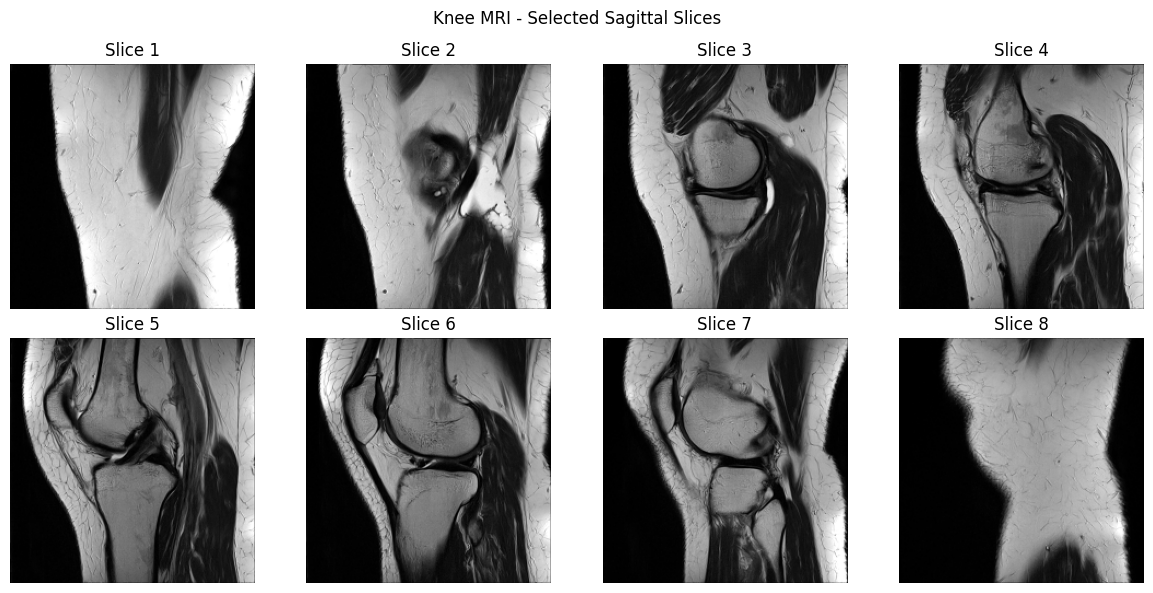

Model input shape: torch.Size([1, 8, 3, 224, 224])

KNEENOVA PREDICTIONS


,Abnormality,Prediction
0,Medial Meniscus,0.541159
1,Baker's,0.533303
2,Contusion,0.516909
3,PF OA,0.507146
4,MCL,0.493015
5,Lateral OA,0.492638
6,Fracture,0.490050
7,Lateral Meniscus,0.487376
8,Synovitis,0.484598
9,Effusion,0.480447


In [45]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# ---------------------------------------------------------
# 1. Select one test study
# ---------------------------------------------------------

study_uid = test_df.iloc[0]["StudyInstanceUID"]

print("Testing study:")
print(study_uid)


# ---------------------------------------------------------
# 2. Get preferred sagittal series
# ---------------------------------------------------------

study_series = test_series[
    test_series["StudyInstanceUID"] == study_uid
]

preferred = study_series[
    (study_series["Anatomical_Plane"] == "Sagittal") &
    (study_series["Fluid_Sensitive"] == 1) &
    (study_series["Fat_Suppression"] == 1)
]

if len(preferred) == 0:
    preferred = study_series[
        study_series["Anatomical_Plane"] == "Sagittal"
    ]

if len(preferred) == 0:
    preferred = study_series.iloc[[0]]

series_uid = preferred.iloc[0]["SeriesInstanceUID"]

print("Selected sagittal series:")
print(series_uid)


# ---------------------------------------------------------
# 3. Load + preprocess MRI
# ---------------------------------------------------------

volume = load_test_series(
    study_uid,
    series_uid
)

print("Original volume shape:", volume.shape)

volume = normalize_volume(volume)

volume = resize_volume(
    volume,
    size=(224, 224)
)

# Select 8 representative slices
indices = np.linspace(
    0,
    volume.shape[0] - 1,
    8
).astype(int)

selected_slices = volume[indices]

print(
    "Selected slices:",
    selected_slices.shape
)


# ---------------------------------------------------------
# 4. DISPLAY MRI SLICES
# ---------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 6)
)

for i, ax in enumerate(
    axes.flat
):

    ax.imshow(
        selected_slices[i],
        cmap="gray"
    )

    ax.set_title(
        f"Slice {i+1}"
    )

    ax.axis("off")

plt.suptitle(
    "Knee MRI - Selected Sagittal Slices"
)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 5. Convert to model input
# ---------------------------------------------------------

image = torch.tensor(
    selected_slices,
    dtype=torch.float32
)

image = image.unsqueeze(
    1
).repeat(
    1,
    3,
    1,
    1
)

image = image.unsqueeze(
    0
)

print(
    "Model input shape:",
    image.shape
)


# ---------------------------------------------------------
# 6. Run KneeNova
# ---------------------------------------------------------

image = image.to(device)

final_model.eval()

with torch.no_grad():

    logits = final_model(
        image
    )

    probabilities = torch.sigmoid(
        logits
    )[0].cpu().numpy()


# ---------------------------------------------------------
# 7. Display predictions
# ---------------------------------------------------------

results = []

for target, prob in zip(
    TARGETS,
    probabilities
):

    results.append({
        "Abnormality": target,
        "Prediction": float(prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "Prediction",
    ascending=False
).reset_index(drop=True)

print("\nKNEENOVA PREDICTIONS")
display(results_df)

In [46]:
def confidence_text(p):
    if p >= 0.70:
        return "High"
    elif p >= 0.55:
        return "Moderate"
    else:
        return "Low"

results_df["Model Score Level"] = (
    results_df["Prediction"]
    .apply(confidence_text)
)

display(results_df)

,Abnormality,Prediction,Model Score Level
0,Medial Meniscus,0.541159,Low
1,Baker's,0.533303,Low
2,Contusion,0.516909,Low
3,PF OA,0.507146,Low
4,MCL,0.493015,Low
5,Lateral OA,0.492638,Low
6,Fracture,0.490050,Low
7,Lateral Meniscus,0.487376,Low
8,Synovitis,0.484598,Low
9,Effusion,0.480447,Low


In [47]:
# Test the SECOND test study
test_index = 1

study_uid = test_df.iloc[test_index]["StudyInstanceUID"]

print("Testing study:", study_uid)

# Create a single-study dataset
single_test_df = test_df.iloc[[test_index]].copy()

single_dataset = KneeNovaTestDataset(
    single_test_df,
    test_series,
    BASE,
    num_slices=8
)

single_loader = DataLoader(
    single_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

# Get MRI
images, study_ids = next(
    iter(single_loader)
)

print(
    "Input shape:",
    images.shape
)

# Prediction
images = images.to(device)

final_model.eval()

with torch.no_grad():

    logits = final_model(images)

    probabilities = torch.sigmoid(
        logits
    )[0].cpu().numpy()

# Results
test2_results = pd.DataFrame({
    "Abnormality": TARGETS,
    "Prediction": probabilities
})

test2_results = test2_results.sort_values(
    "Prediction",
    ascending=False
).reset_index(drop=True)

print("\nKNEENOVA — TEST STUDY 2")

display(test2_results)

Testing study: 1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
Input shape: torch.Size([1, 8, 3, 224, 224])

KNEENOVA — TEST STUDY 2


,Abnormality,Prediction
0,MCL,0.552545
1,Contusion,0.540989
2,Medial Meniscus,0.515635
3,Medial OA,0.464310
4,Effusion,0.452318
5,Synovitis,0.440747
6,ACL,0.435101
7,Lateral Meniscus,0.434594
8,PF OA,0.428169
9,Fracture,0.417361


In [48]:
# Test the THIRD test study
test_index = 2

study_uid = test_df.iloc[test_index]["StudyInstanceUID"]

single_test_df = test_df.iloc[[test_index]].copy()

single_dataset = KneeNovaTestDataset(
    single_test_df,
    test_series,
    BASE,
    num_slices=8
)

single_loader = DataLoader(
    single_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

images, study_ids = next(iter(single_loader))

images = images.to(device)

final_model.eval()

with torch.no_grad():
    logits = final_model(images)
    probabilities = torch.sigmoid(logits)[0].cpu().numpy()

test3_results = pd.DataFrame({
    "Abnormality": TARGETS,
    "Prediction": probabilities
}).sort_values(
    "Prediction",
    ascending=False
).reset_index(drop=True)

print("Study 3:", study_uid)
display(test3_results)

Study 3: 1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402


,Abnormality,Prediction
0,Medial Meniscus,0.533879
1,Medial OA,0.518535
2,Contusion,0.512390
3,MCL,0.507220
4,Baker's,0.502333
5,Lateral Meniscus,0.496300
6,PF OA,0.491093
7,Lateral OA,0.477990
8,Effusion,0.467019
9,ACL,0.463526


In [49]:
# ============================================================
# KNEENOVA FINAL BACKUP
# ============================================================

import os
import zipfile
import shutil

WORKING = "/kaggle/working"
BACKUP_DIR = os.path.join(WORKING, "KneeNova_Final_Backup")
ZIP_PATH = os.path.join(WORKING, "KneeNova_Final_Backup.zip")

os.makedirs(BACKUP_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Copy final model checkpoints
# ------------------------------------------------------------

final_model_dir = os.path.join(
    WORKING,
    "kneenova_final_checkpoints"
)

if os.path.exists(final_model_dir):

    shutil.copytree(
        final_model_dir,
        os.path.join(
            BACKUP_DIR,
            "final_model"
        ),
        dirs_exist_ok=True
    )


# ------------------------------------------------------------
# 2. Copy submission
# ------------------------------------------------------------

for filename in [
    "submission.csv",
    "MRI_Report_Fusion_Results.csv",
    "MRI_Report_Fusion_Fold_Summary.csv"
]:

    source = os.path.join(
        WORKING,
        filename
    )

    if os.path.exists(source):

        shutil.copy2(
            source,
            BACKUP_DIR
        )


# ------------------------------------------------------------
# 3. Copy existing research backup if available
# ------------------------------------------------------------

old_backup = os.path.join(
    WORKING,
    "KneeNova_Backup.zip"
)

if os.path.exists(old_backup):

    shutil.copy2(
        old_backup,
        BACKUP_DIR
    )


# ------------------------------------------------------------
# 4. Create ZIP
# ------------------------------------------------------------

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk(
        BACKUP_DIR
    ):

        for file in files:

            full_path = os.path.join(
                root,
                file
            )

            arcname = os.path.relpath(
                full_path,
                BACKUP_DIR
            )

            z.write(
                full_path,
                arcname
            )


# ------------------------------------------------------------
# 5. Verify
# ------------------------------------------------------------

print("==========================================")
print("KneeNova backup completed")
print("==========================================")

print(
    "ZIP:",
    ZIP_PATH
)

print(
    "ZIP exists:",
    os.path.exists(ZIP_PATH)
)

if os.path.exists(ZIP_PATH):

    size_mb = (
        os.path.getsize(ZIP_PATH)
        / (1024 ** 2)
    )

    print(
        f"ZIP size: {size_mb:.2f} MB"
    )

print("\nBackup contents:")

for root, dirs, files in os.walk(
    BACKUP_DIR
):

    for file in files:

        print(
            os.path.relpath(
                os.path.join(root, file),
                BACKUP_DIR
            )
        )

KneeNova backup completed
ZIP: /kaggle/working/KneeNova_Final_Backup.zip
ZIP exists: True
ZIP size: 210.69 MB

Backup contents:
submission.csv
MRI_Report_Fusion_Fold_Summary.csv
MRI_Report_Fusion_Results.csv
KneeNova_Backup.zip
final_model/kneenova_final_best.pth
final_model/kneenova_final_epoch_3.pth
final_model/kneenova_final_epoch_2.pth
final_model/kneenova_final_epoch_4.pth
final_model/kneenova_final_epoch_1.pth
